# LLMEmbed — RQ1–RQ4 with complete RQ1 code and historical outputs
RQ1 code is taken from the uploaded corrected RQ1 notebook; RQ2–RQ4 remain from the curated notebook. Historical outputs are retained where available. This notebook has **not** been executed end-to-end after merging.


## Shared setup and reusable model functions
Run in Google Colab with GPU. Confirm model permissions, Drive space, repository checkout, and pinned dependency versions. Avoid running the original competing `pip` install/restart cells together.


In [1]:
# Install initial dependencies
# Source: original uploaded notebook, cell 2.
# Saved outputs are historical; rerun in Colab to reproduce.

%pip -q install pandas numpy scikit-learn matplotlib tqdm transformers accelerate datasets safetensors
from google.colab import drive
drive.mount("/content/drive")
import torch,platform
print("GPU:",torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NOT AVAILABLE")
print("Torch:",torch.__version__,"Python:",platform.python_version())

Mounted at /content/drive
GPU: NVIDIA A100-SXM4-40GB
Torch: 2.11.0+cu130 Python: 3.13.16


In [2]:
# Clone and pin official repository
# Source: original uploaded notebook, cell 4.
# Saved outputs are historical; rerun in Colab to reproduce.

import subprocess, pathlib, os, json, sys, inspect, re
REPO=pathlib.Path("/content/LLMEmbed-ACL2024")
if not (REPO/".git").exists(): subprocess.run(["git","clone","https://github.com/ChunLiu-cs/LLMEmbed-ACL2024.git",str(REPO)],check=True)
COMMIT=subprocess.check_output(["git","-C",str(REPO),"rev-parse","HEAD"],text=True).strip()
print("Pinned commit:",COMMIT)
print("Files:",*[str(p.relative_to(REPO)) for p in sorted(REPO.glob("*.py"))],sep="\n")

Pinned commit: 996c2c9d8425d4be7953c2c0257de0217a2edac7
Files:
DownstreamModel.py
MyDataset.py
main.py
model_op.py
model_op_multi.py


In [10]:
# Mount Drive and record environment
# Source: original uploaded notebook, cell 19.
# Saved outputs are historical; rerun in Colab to reproduce.

from google.colab import drive
try: drive.mount('/content/drive', force_remount=False)
except ValueError: pass
from pathlib import Path
import os, sys, json, time, random, hashlib, subprocess, gc, platform
import numpy as np, pandas as pd, torch
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, classification_report, confusion_matrix
ROOT=Path('/content/LLMEmbed-ACL2024')
DRIVE=Path('/content/drive/MyDrive/COMP8240_LLMEmbed')
OUT=DRIVE/'official_replication_results'; OUT.mkdir(parents=True,exist_ok=True)
assert (ROOT/'DownstreamModel.py').exists(), 'Clone official repo first'
sys.path.insert(0,str(ROOT)); os.chdir(ROOT)
SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE='cuda:0' if torch.cuda.is_available() else 'cpu'
assert DEVICE.startswith('cuda'), 'GPU runtime required for practical execution'
print('GPU:',torch.cuda.get_device_name(0))
print('Git commit:',subprocess.run(['git','rev-parse','HEAD'],cwd=ROOT,capture_output=True,text=True).stdout.strip())
print('Torch:',torch.__version__)
import transformers, datasets
print('Transformers:',transformers.__version__,'Datasets:',datasets.__version__)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU: NVIDIA A100-SXM4-40GB
Git commit: 996c2c9d8425d4be7953c2c0257de0217a2edac7
Torch: 2.11.0+cu130
Transformers: 4.45.2 Datasets: 2.21.0


In [23]:
# Prepare datasets
# Source: original uploaded notebook, cell 39.
# Saved outputs are historical; rerun in Colab to reproduce.


from sklearn.datasets import fetch_20newsgroups

ORIGINAL_TASKS = ["sst2", "mr", "agnews", "r8", "r52"]

NEW_TASKS = [
    "banking77",
    "clinc150",
    "trec",
    "tweeteval",
    "20ng"
]

ALL_TASKS = ORIGINAL_TASKS + NEW_TASKS

AUTHOR_SPLITS = BASE / "author_splits"

def frame(text, label):
    return pd.DataFrame({
        "text": list(map(str, text)),
        "label": list(label)
    })

def load_original_json(task):
    folder = AUTHOR_SPLITS / task

    result = []
    for split in ["train", "test"]:
        path = folder / f"{split}.json"

        if not path.exists():
            raise FileNotFoundError(
                f"Original {task} split missing: {path}"
            )

        data = json.loads(path.read_text())

        if isinstance(data, dict):
            df = frame(data["text"], data["label"])

        elif isinstance(data, list):
            df = pd.DataFrame(data)

            if not {"text", "label"}.issubset(df.columns):
                raise ValueError(
                    f"Unsupported JSON structure: {path}"
                )

            df = df[["text", "label"]]

        else:
            raise ValueError(f"Unsupported JSON: {path}")

        result.append(df)

    return result[0], result[1]

def load_dataset_for_task(task):
    if task == "sst2":
        ds = load_dataset("stanfordnlp/sst2")
        train = frame(
            ds["train"]["sentence"],
            ds["train"]["label"]
        )
        test = frame(
            ds["validation"]["sentence"],
            ds["validation"]["label"]
        )

    elif task in ["mr", "r8", "r52"]:
        train, test = load_original_json(task)

    elif task == "agnews":
        ds = load_dataset("fancyzhx/ag_news")
        train = frame(
            ds["train"]["text"], ds["train"]["label"]
        )
        test = frame(
            ds["test"]["text"], ds["test"]["label"]
        )

    elif task == "banking77":
        ds = load_dataset("PolyAI/banking77")
        train = frame(
            ds["train"]["text"], ds["train"]["label"]
        )
        test = frame(
            ds["test"]["text"], ds["test"]["label"]
        )

    elif task == "clinc150":
        ds = load_dataset("clinc_oos", "plus150")

        label_names = ds["train"].features["intent"].names

        oos_candidates = [
            i for i, name in enumerate(label_names)
            if name.lower() in {
                "oos", "out_of_scope", "out-of-scope"
            }
        ]

        assert len(oos_candidates) == 1, (
            "Check CLINC150 OOS label manually"
        )

        oos_id = oos_candidates[0]

        train = frame(
            ds["train"]["text"], ds["train"]["intent"]
        )
        test = frame(
            ds["test"]["text"], ds["test"]["intent"]
        )

        # Primary experiment: 150 in-scope intents.
        train = train[train.label != oos_id]
        test = test[test.label != oos_id]

    elif task == "trec":
        ds = load_dataset("CogComp/trec")

        train = frame(
            ds["train"]["text"],
            ds["train"]["coarse_label"]
        )
        test = frame(
            ds["test"]["text"],
            ds["test"]["coarse_label"]
        )

    elif task == "tweeteval":
        ds = load_dataset(
            "cardiffnlp/tweet_eval",
            "sentiment"
        )

        train = frame(
            ds["train"]["text"], ds["train"]["label"]
        )
        test = frame(
            ds["test"]["text"], ds["test"]["label"]
        )

    elif task == "20ng":
        tr = fetch_20newsgroups(
            subset="train",
            remove=("headers", "footers", "quotes"),
            shuffle=False
        )
        te = fetch_20newsgroups(
            subset="test",
            remove=("headers", "footers", "quotes"),
            shuffle=False
        )

        train = frame(tr.data, tr.target)
        test = frame(te.data, te.target)

    else:
        raise ValueError(task)

    return train, test

def prepare_task(task, reuse_existing=True):
    folder = DATA_DIR / task
    folder.mkdir(parents=True, exist_ok=True)

    train_path = folder / "train.csv"
    test_path = folder / "test.csv"
    metadata_path = folder / "metadata.json"

    if (
        reuse_existing
        and train_path.exists()
        and test_path.exists()
        and metadata_path.exists()
    ):
        train = pd.read_csv(train_path)
        test = pd.read_csv(test_path)
        metadata = json.loads(metadata_path.read_text())

        print("REUSED PREPARED DATASET:", task)

    else:
        train, test = load_dataset_for_task(task)

        train = train.dropna(subset=["label"]).copy()
        test = test.dropna(subset=["label"]).copy()

        train["text"] = train.text.fillna("").astype(str)
        test["text"] = test.text.fillna("").astype(str)

        classes = sorted(
            train.label.unique().tolist(),
            key=str
        )

        assert set(test.label.unique()).issubset(
            set(classes)
        ), "Test split contains unseen labels"

        label_map = {
            label: i for i, label in enumerate(classes)
        }

        train["label"] = train.label.map(label_map).astype(int)
        test["label"] = test.label.map(label_map).astype(int)

        train = train.reset_index(drop=True)
        test = test.reset_index(drop=True)

        metadata = {
            "task": task,
            "n_classes": len(classes),
            "n_train": len(train),
            "n_test": len(test),
            "label_map": {
                str(k): v for k, v in label_map.items()
            }
        }

        train.to_csv(train_path, index=False)
        test.to_csv(test_path, index=False)

        metadata_path.write_text(
            json.dumps(metadata, indent=2)
        )

    assert {"text", "label"}.issubset(train.columns)
    assert {"text", "label"}.issubset(test.columns)

    assert train.label.notna().all()
    assert test.label.notna().all()

    labels = set(train.label.astype(int))
    assert labels == set(range(metadata["n_classes"]))
    assert set(test.label.astype(int)).issubset(labels)

    return {
        "task": task,
        "train": len(train),
        "test": len(test),
        "classes": metadata["n_classes"],
        "status": "READY"
    }

registry = []

for task in ALL_TASKS:
    try:
        registry.append(prepare_task(task))
    except Exception as e:
        registry.append({
            "task": task,
            "status": "BLOCKED",
            "reason": str(e)
        })

registry = pd.DataFrame(registry)

registry.to_csv(
    RESULT_DIR / "dataset_registry.csv",
    index=False
)

display(registry)


Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7600 [00:00<?, ? examples/s]

The repository for PolyAI/banking77 contains custom code which must be executed to correctly load the dataset. You can inspect the repository content at https://hf.co/datasets/PolyAI/banking77.
You can avoid this prompt in future by passing the argument `trust_remote_code=True`.

Do you wish to run the custom code? [y/N] y


/root/.cache/huggingface/modules/datasets_modules/datasets/PolyAI--banking77/17ffc2ed47c2ed928bee64127ff1dbc97204cb974c2f980becae7c864007aed9/banking77.py:25: SyntaxWarning: invalid escape sequence '\~'
  author      = {I{\~{n}}igo Casanueva and Tadas Temcinas and Daniela Gerz and Matthew Henderson and Ivan Vulic},


Generating train split:   0%|          | 0/10003 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/3080 [00:00<?, ? examples/s]

... (3 outputs left out)

Generating train split:   0%|          | 0/45615 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/12284 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

,task,train,test,classes,status,reason
0,sst2,67349.0,872.0,2.0,READY,NaN
1,mr,NaN,NaN,NaN,BLOCKED,Original mr split missing: /content/drive/MyDr...
2,agnews,120000.0,7600.0,4.0,READY,NaN
3,r8,NaN,NaN,NaN,BLOCKED,Original r8 split missing: /content/drive/MyDr...
4,r52,NaN,NaN,NaN,BLOCKED,Original r52 split missing: /content/drive/MyD...
5,banking77,10003.0,3080.0,77.0,READY,NaN
6,clinc150,NaN,NaN,NaN,BLOCKED,BuilderConfig 'plus150' not found. Available: ...
7,trec,5452.0,500.0,6.0,READY,NaN
8,tweeteval,45615.0,12284.0,3.0,READY,NaN
9,20ng,11314.0,7532.0,20.0,READY,NaN


In [24]:
# Define encoder loading
# Source: original uploaded notebook, cell 41.
# Saved outputs are historical; rerun in Colab to reproduce.


from transformers import AutoTokenizer, AutoModel
from huggingface_hub import login

HF_TOKEN = userdata.get("HF_TOKEN")
assert HF_TOKEN

login(token=HF_TOKEN, add_to_git_credential=False)

MODEL_IDS = {
    "llama2": "meta-llama/Llama-2-7b-chat-hf",
    "bert": "bert-large-uncased",
    "roberta": "roberta-large"
}

LLAMA_REVISION = (
    "f5db02db724555f92da89c216ac04704f23d4590"
)

ACTIVE_MODEL = None
ACTIVE_TOKENIZER = None
ACTIVE_NAME = None

def release_encoder():
    global ACTIVE_MODEL, ACTIVE_TOKENIZER, ACTIVE_NAME

    ACTIVE_MODEL = None
    ACTIVE_TOKENIZER = None
    ACTIVE_NAME = None

    gc.collect()
    torch.cuda.empty_cache()

def load_encoder(name):
    global ACTIVE_MODEL, ACTIVE_TOKENIZER, ACTIVE_NAME

    if ACTIVE_NAME == name and ACTIVE_MODEL is not None:
        return

    release_encoder()

    model_id = MODEL_IDS[name]
    kwargs = {}

    if name == "llama2":
        kwargs = {
            "token": HF_TOKEN,
            "revision": LLAMA_REVISION
        }

    tokenizer = AutoTokenizer.from_pretrained(
        model_id, **kwargs
    )

    if name == "llama2":
        if "[PAD]" not in tokenizer.get_vocab():
            tokenizer.add_special_tokens({
                "pad_token": "[PAD]"
            })
        else:
            tokenizer.pad_token = "[PAD]"

        tokenizer.padding_side = "right"

        encoder = AutoModel.from_pretrained(
            model_id,
            torch_dtype=torch.float16,
            device_map={"": 0},
            low_cpu_mem_usage=True,
            **kwargs
        )

        if (
            len(tokenizer)
            != encoder.get_input_embeddings().num_embeddings
        ):
            signature = inspect.signature(
                encoder.resize_token_embeddings
            ).parameters

            if "mean_resizing" in signature:
                encoder.resize_token_embeddings(
                    len(tokenizer),
                    mean_resizing=False
                )
            else:
                encoder.resize_token_embeddings(len(tokenizer))

        encoder.config.pad_token_id = tokenizer.pad_token_id

    else:
        encoder = AutoModel.from_pretrained(
            model_id
        ).to(DEVICE)

    encoder.eval()

    ACTIVE_MODEL = encoder
    ACTIVE_TOKENIZER = tokenizer
    ACTIVE_NAME = name

    print("LOADED:", name)

def encode_batch(texts, name, max_length):
    tokens = ACTIVE_TOKENIZER(
        list(texts),
        max_length=max_length,
        truncation=True,
        padding="max_length",
        return_tensors="pt"
    ).to(DEVICE)

    with torch.inference_mode():
        if name == "llama2":
            # Access LLaMA's transformer hidden states.
            output = ACTIVE_MODEL(
                **tokens,
                output_hidden_states=True,
                use_cache=False
            )

            features = torch.stack([
                output.hidden_states[i].float().mean(dim=1)
                for i in range(-1, -6, -1)
            ], dim=1)

        elif name == "bert":
            output = ACTIVE_MODEL(**tokens)
            features = output.pooler_output.float()

        else:
            output = ACTIVE_MODEL(**tokens)
            features = output.last_hidden_state[:, 0, :].float()

    return features.cpu()

print("REPRESENTATION FUNCTIONS READY")


REPRESENTATION FUNCTIONS READY


In [25]:
# Extract representations
# Source: original uploaded notebook, cell 43.
# Saved outputs are historical; rerun in Colab to reproduce.


def extract_dataset(task, backbone, max_length=None):
    load_encoder(backbone)

    if max_length is None:
        max_length = 128 if backbone == "llama2" else 512

    batch_size = 4 if backbone == "llama2" else 24
    chunk_size = 200

    shape = (
        (5, 4096) if backbone == "llama2"
        else (1024,)
    )

    folder = REP_DIR / task / backbone
    folder.mkdir(parents=True, exist_ok=True)

    timings = {}

    for split in ["train", "test"]:
        df = pd.read_csv(
            DATA_DIR / task / f"{split}.csv"
        ).fillna({"text": ""})

        texts = df.text.astype(str).tolist()
        labels = torch.tensor(
            df.label.to_numpy(),
            dtype=torch.long
        )

        n = len(df)

        x_path = folder / f"{split}_sents.pt"
        y_path = folder / f"{split}_labels.pt"

        if x_path.exists() and y_path.exists():
            existing = torch.load(
                x_path,
                map_location="cpu",
                weights_only=True,
                mmap=True
            )
            existing_labels = torch.load(
                y_path,
                map_location="cpu",
                weights_only=True
            )

            assert tuple(existing.shape) == (n, *shape)
            assert torch.equal(existing_labels, labels)

            print("REUSED:", task, backbone, split)
            del existing, existing_labels
            continue

        chunks = folder / f"{split}_chunks"
        chunks.mkdir(exist_ok=True)

        signature = hashlib.sha256(
            json.dumps({
                "texts": texts,
                "labels": labels.tolist(),
                "model": MODEL_IDS[backbone],
                "max_length": max_length,
                "pad_id": ACTIVE_TOKENIZER.pad_token_id,
                "method": backbone
            }, ensure_ascii=False).encode()
        ).hexdigest()

        manifest = chunks / "manifest.json"

        if manifest.exists():
            assert (
                json.loads(manifest.read_text())["signature"]
                == signature
            ), "Checkpoint configuration mismatch"
        else:
            manifest.write_text(json.dumps({
                "signature": signature
            }))

        started = time.perf_counter()

        for start in range(0, n, chunk_size):
            end = min(start + chunk_size, n)

            chunk_path = (
                chunks / f"{start:07d}_{end:07d}.pt"
            )

            if chunk_path.exists():
                chunk = torch.load(
                    chunk_path,
                    map_location="cpu",
                    weights_only=True
                )
                assert tuple(chunk.shape) == (
                    end - start, *shape
                )
                del chunk
                continue

            parts = []

            for b in range(start, end, batch_size):
                e = min(b + batch_size, end)

                parts.append(
                    encode_batch(
                        texts[b:e],
                        backbone,
                        max_length
                    )
                )

            chunk = torch.cat(parts, dim=0)

            assert tuple(chunk.shape) == (
                end - start, *shape
            )
            assert torch.isfinite(chunk).all()

            temporary = chunk_path.with_suffix(".tmp")
            torch.save(chunk, temporary)
            os.replace(temporary, chunk_path)

            del parts, chunk
            gc.collect()

            print(
                task, backbone, split,
                f"{end}/{n}",
                end="\r"
            )

        full = torch.empty(
            (n, *shape),
            dtype=torch.float32
        )

        for start in range(0, n, chunk_size):
            end = min(start + chunk_size, n)

            path = chunks / f"{start:07d}_{end:07d}.pt"

            full[start:end] = torch.load(
                path,
                map_location="cpu",
                weights_only=True
            )

        assert torch.isfinite(full).all()

        temp_x = x_path.with_suffix(".tmp")
        temp_y = y_path.with_suffix(".tmp")

        torch.save(full, temp_x)
        torch.save(labels, temp_y)

        os.replace(temp_x, x_path)
        os.replace(temp_y, y_path)

        timings[split] = time.perf_counter() - started

        print(
            "\nSAVED:",
            task, backbone, split,
            tuple(full.shape),
            f"{timings[split]:.1f} seconds"
        )

        del full
        gc.collect()

    (folder / "runtime.json").write_text(
        json.dumps({
            "task": task,
            "backbone": backbone,
            "seconds": timings,
            "max_length": max_length,
            "batch_size": batch_size
        }, indent=2)
    )

    return timings

print("DATASET EXTRACTION READY")


DATASET EXTRACTION READY


In [27]:
# Representation dataset loader
# Source: original uploaded notebook, cell 47.
# Saved outputs are historical; rerun in Colab to reproduce.


from torch.utils.data import Dataset, DataLoader, Subset

class LLMEmbedDataset(Dataset):
    def __init__(self, task, split):
        self.x = {}

        expected = {
            "llama2": (5, 4096),
            "bert": (1024,),
            "roberta": (1024,)
        }

        for name, shape in expected.items():
            folder = REP_DIR / task / name

            x = torch.load(
                folder / f"{split}_sents.pt",
                map_location="cpu",
                weights_only=True,
                mmap=True
            )

            y = torch.load(
                folder / f"{split}_labels.pt",
                map_location="cpu",
                weights_only=True
            ).long()

            assert tuple(x.shape[1:]) == shape

            self.x[name] = x

            if name == "llama2":
                self.y = y
            else:
                assert torch.equal(
                    self.y, y
                ), f"Label mismatch: {name}"

    def __len__(self):
        return len(self.y)

    def __getitem__(self, index):
        return (
            self.x["llama2"][index],
            self.x["bert"][index],
            self.x["roberta"][index],
            self.y[index]
        )

print("ORIGINAL MODEL INPUT FORMAT READY")


ORIGINAL MODEL INPUT FORMAT READY


In [28]:
# Evaluation metrics
# Source: original uploaded notebook, cell 49.
# Saved outputs are historical; rerun in Colab to reproduce.


def calculate_all_metrics(y_true, y_pred, n_classes):
    labels = list(range(n_classes))

    p, r, f1, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=labels,
        average="macro",
        zero_division=0
    )

    pw, rw, fw, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=labels,
        average="weighted",
        zero_division=0
    )

    return {
        "accuracy": float(
            accuracy_score(y_true, y_pred)
        ),
        "precision_macro": float(p),
        "recall_macro": float(r),
        "f1_macro": float(f1),
        "precision_weighted": float(pw),
        "recall_weighted": float(rw),
        "f1_weighted": float(fw),
        "mcc": float(
            matthews_corrcoef(y_true, y_pred)
        )
    }

print("EVALUATION METRICS READY")


EVALUATION METRICS READY


In [29]:
# Train and evaluate classifier
# Source: original uploaded notebook, cell 51.
# Saved outputs are historical; rerun in Colab to reproduce.


def train_and_evaluate(
    task,
    epochs=10,
    sigma=0.4,
    batch_size=32,
    lr=1e-4,
    seed=42,
    fraction=1.0,
    run_name=None
):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    metadata = json.loads(
        (DATA_DIR / task / "metadata.json").read_text()
    )

    n_classes = int(metadata["n_classes"])

    full_train = LLMEmbedDataset(task, "train")
    test_dataset = LLMEmbedDataset(task, "test")

    train_dataset = full_train

    if fraction < 1.0:
        rng = np.random.default_rng(seed)
        labels = full_train.y.numpy()
        indices = []

        for c in np.unique(labels):
            candidates = np.flatnonzero(labels == c)

            n = max(
                1,
                int(round(len(candidates) * fraction))
            )

            chosen = rng.choice(
                candidates,
                size=n,
                replace=False
            )

            indices.extend(chosen.tolist())

        train_dataset = Subset(
            full_train,
            sorted(indices)
        )

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=0,
        pin_memory=True
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0,
        pin_memory=True
    )

    # Authors' original architecture.
    model = DownstreamModel(
        n_classes,
        sigma
    ).to(DEVICE)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=lr
    )

    # Preserves original authors' loss setup.
    criterion = torch.nn.CrossEntropyLoss()

    history = []

    if run_name is None:
        run_name = f"full_seed{seed}"

    save_dir = RESULT_DIR / task / run_name
    save_dir.mkdir(parents=True, exist_ok=True)

    print("=" * 80)
    print("LLMEMBED TRAINING")
    print("=" * 80)

    print("Dataset:", task)
    print("Classes:", n_classes)
    print("Training examples:", len(train_dataset))
    print("Evaluation examples:", len(test_dataset))
    print("Epochs:", epochs)
    print("SIGMA:", sigma)
    print("Batch size:", batch_size)
    print("Learning rate:", lr)
    print("Seed:", seed)

    torch.cuda.reset_peak_memory_stats()

    start_train = time.perf_counter()

    for epoch in range(epochs):
        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for llama, bert, roberta, labels in train_loader:
            llama = llama.to(
                DEVICE, dtype=torch.float32
            )
            bert = bert.to(
                DEVICE, dtype=torch.float32
            )
            roberta = roberta.to(
                DEVICE, dtype=torch.float32
            )
            labels = labels.to(
                DEVICE, dtype=torch.long
            )

            optimizer.zero_grad(set_to_none=True)

            outputs = model(
                llama, bert, roberta
            )

            loss = criterion(
                outputs, labels
            )

            loss.backward()
            optimizer.step()

            running_loss += (
                loss.item() * len(labels)
            )

            correct += (
                outputs.argmax(dim=1) == labels
            ).sum().item()

            total += len(labels)

        epoch_loss = running_loss / total
        epoch_accuracy = correct / total

        history.append({
            "epoch": epoch + 1,
            "train_loss": epoch_loss,
            "train_accuracy": epoch_accuracy
        })

        print(
            f"Epoch {epoch+1:02d}/{epochs} | "
            f"Loss={epoch_loss:.5f} | "
            f"Accuracy={epoch_accuracy:.5f}"
        )

    torch.cuda.synchronize()
    train_seconds = time.perf_counter() - start_train

    # --------------------------------------------------------
    # Evaluation on untouched held-out split
    # --------------------------------------------------------

    model.eval()

    y_true = []
    y_pred = []
    probabilities = []

    start_eval = time.perf_counter()

    with torch.inference_mode():
        for llama, bert, roberta, labels in test_loader:
            outputs = model(
                llama.to(DEVICE).float(),
                bert.to(DEVICE).float(),
                roberta.to(DEVICE).float()
            )

            y_true.extend(labels.tolist())

            y_pred.extend(
                outputs.argmax(dim=1).cpu().tolist()
            )

            probabilities.extend(
                outputs.cpu().tolist()
            )

    torch.cuda.synchronize()
    eval_seconds = time.perf_counter() - start_eval

    metrics = calculate_all_metrics(
        y_true, y_pred, n_classes
    )

    metrics.update({
        "dataset": task,
        "run": run_name,
        "model": "Original LLMEmbed DownstreamModel",
        "n_classes": n_classes,
        "n_train": len(train_dataset),
        "n_test": len(test_dataset),
        "fraction": fraction,
        "seed": seed,
        "epochs": epochs,
        "sigma": sigma,
        "batch_size": batch_size,
        "learning_rate": lr,
        "training_seconds": train_seconds,
        "evaluation_seconds": eval_seconds,
        "evaluation_throughput": (
            len(test_dataset) / eval_seconds
        ),
        "peak_gpu_memory_gb": (
            torch.cuda.max_memory_allocated()
            / 1024**3
        )
    })

    print("\n" + "=" * 80)
    print("FINAL EVALUATION")
    print("=" * 80)

    print(f"Accuracy:        {metrics['accuracy']:.6f}")
    print(f"Macro-precision: {metrics['precision_macro']:.6f}")
    print(f"Macro-recall:    {metrics['recall_macro']:.6f}")
    print(f"Macro-F1:        {metrics['f1_macro']:.6f}")
    print(f"Weighted-F1:     {metrics['f1_weighted']:.6f}")
    print(f"MCC:             {metrics['mcc']:.6f}")
    print(f"Training time:   {train_seconds:.2f} s")
    print(f"Evaluation time: {eval_seconds:.2f} s")

    print("\nCLASSIFICATION REPORT")
    print(
        classification_report(
            y_true, y_pred,
            labels=list(range(n_classes)),
            zero_division=0
        )
    )

    print("\nCONFUSION MATRIX")
    cm = confusion_matrix(
        y_true, y_pred,
        labels=list(range(n_classes))
    )
    print(cm)

    # --------------------------------------------------------
    # Save actual measured outputs
    # --------------------------------------------------------

    pd.DataFrame(history).to_csv(
        save_dir / "training_history.csv",
        index=False
    )

    pd.DataFrame({
        "true_label": y_true,
        "predicted_label": y_pred
    }).to_csv(
        save_dir / "predictions.csv",
        index=False
    )

    np.save(
        save_dir / "probabilities.npy",
        np.asarray(probabilities, dtype=np.float32)
    )

    pd.DataFrame(cm).to_csv(
        save_dir / "confusion_matrix.csv",
        index=False
    )

    (save_dir / "metrics.json").write_text(
        json.dumps(metrics, indent=2)
    )

    torch.save(
        model.state_dict(),
        save_dir / "model_state.pt"
    )

    del model
    gc.collect()
    torch.cuda.empty_cache()

    print("\nRESULTS SAVED:", save_dir)

    return metrics

print("TRAINING FUNCTION READY")


TRAINING FUNCTION READY


## RQ1 — Five original ACL benchmarks
Paper benchmarks: SST-2, MR, AG News, R8 and R52. The original notebook contains multiple recovery and training attempts; only the final reusable audit and runner are retained. Validate exact source versions, split sizes and fusion strategy before claiming faithful replication.


### RQ1 — Complete executable replication code and retained results
The following cells come from the uploaded **RQ1_Original_Replication_FIXED(2).ipynb**. They define the RQ1 data loading, embedding extraction, classifier, metrics and five-dataset runner. Execute the shared installation cell first and restart the Colab runtime if packages changed. **Saved outputs are historical, not freshly executed.**


In [2]:
# CELL 2 — Imports and paths
from google.colab import drive, userdata
drive.mount('/content/drive')
from pathlib import Path
import os, sys, json, gc, time, random, inspect, traceback, hashlib
import numpy as np, pandas as pd, torch
import pyarrow, datasets
from datasets import load_dataset
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             f1_score, matthews_corrcoef, classification_report, confusion_matrix)
from IPython.display import display
print('pandas', pd.__version__, 'pyarrow', pyarrow.__version__, 'datasets', datasets.__version__)
BASE = Path('/content/drive/MyDrive/COMP8240_LLMEmbed')
DATA_DIR = BASE/'prepared_datasets'; REP_DIR = BASE/'representations_v2'; RESULT_DIR = BASE/'results_v2'
AUTHOR_SPLITS = BASE/'author_splits'
ORIGINAL_TASKS = ['sst2','mr','agnews','r8','r52']
BACKBONES = ['llama2','bert','roberta']
EXPECTED_CLASSES = dict(zip(ORIGINAL_TASKS,[2,2,4,8,52]))
EXPECTED_SIZES = {'sst2':(67349,872),'mr':(8662,2000),'agnews':(120000,7600),'r8':(4936,2189),'r52':(5878,2568)}
EPOCHS=100; BATCH_SIZE=32; LR=1e-4; SIGMA=0.4; SEED=42
DEVICE='cuda' if torch.cuda.is_available() else 'cpu'
for p in (DATA_DIR,REP_DIR,RESULT_DIR,AUTHOR_SPLITS): p.mkdir(parents=True,exist_ok=True)
# Locate existing author repository; never silently substitute a different architecture.
CANDIDATES = [Path('/content/LLMEmbed-ACL2024'),Path('/content/LLMEmbed-OFFICIAL'),BASE/'LLMEmbed',BASE/'LLMEmbed-ACL2024']
REPO = next((p for p in CANDIDATES if (p/'DownstreamModel.py').is_file()),None)
if REPO is None:
    print('Author repository not found. Place official DownstreamModel.py in one of:', *CANDIDATES,sep='\n - ')
else:
    sys.path.insert(0,str(REPO))
    from DownstreamModel import DownstreamModel
    print('Author model loaded from', REPO)
print('DEVICE:', DEVICE)


Mounted at /content/drive


ValueError: numpy.dtype size changed, may indicate binary incompatibility. Expected 96 from C header, got 88 from PyObject

In [3]:
# CELL 3 — Dataset preparation (preserve original splits and counts)
def _frame(text, labels):
    return pd.DataFrame({'text':list(text),'label':list(labels)})

def _read_split(path):
    if path.suffix=='.csv': return pd.read_csv(path)
    obj=json.loads(path.read_text())
    return pd.DataFrame(obj if isinstance(obj,list) else {'text':obj['text'],'label':obj['label']})

def _local_pair(folder):
    for ext in ('csv','json'):
        a,b=folder/f'train.{ext}',folder/f'test.{ext}'
        if a.is_file() and b.is_file():return _read_split(a),_read_split(b)
    return None

def _public_pair(task):
    if task=='sst2':
        d=load_dataset('stanfordnlp/sst2')
        return _frame(d['train']['sentence'],d['train']['label']),_frame(d['validation']['sentence'],d['validation']['label'])
    if task=='agnews':
        d=load_dataset('fancyzhx/ag_news')
        return _frame(d['train']['text'],d['train']['label']),_frame(d['test']['text'],d['test']['label'])
    source={'mr':'sh0416/mr','r8':'dxgp/R8','r52':'dxgp/R52'}[task]
    d=load_dataset(source)
    if 'train' not in d or 'test' not in d: raise ValueError(f'{source}: no train/test pair')
    return d['train'].to_pandas(),d['test'].to_pandas()

def prepare_task(task):
    folder=DATA_DIR/task; folder.mkdir(parents=True,exist_ok=True)
    pair=_local_pair(folder)
    source='prepared'
    if pair is None:
        pair=_local_pair(AUTHOR_SPLITS/task);source='author_splits'
    if pair is None:
        pair=_public_pair(task);source='public'
    train,test=pair
    def standardize(df):
        text=next((c for c in ['text','sentence','content','review'] if c in df),None)
        label=next((c for c in ['label','labels','category','target'] if c in df),None)
        if text is None or label is None:raise ValueError(f'{task}: unknown columns {df.columns.tolist()}')
        return df[[text,label]].rename(columns={text:'text',label:'label'}).copy()
    train,test=standardize(train),standardize(test)
    for df in (train,test):
        df.dropna(subset=['label'],inplace=True)
        df['text']=df['text'].fillna('').astype(str)
    # Preserve existing integer labels where already contiguous.
    all_labels=list(pd.unique(pd.concat([train.label,test.label],ignore_index=True)))
    try: numeric=all(isinstance(x,(int,np.integer)) for x in all_labels)
    except Exception: numeric=False
    classes=sorted(all_labels) if numeric else sorted(all_labels,key=str)
    mapping={v:i for i,v in enumerate(classes)}
    for df in (train,test):df['label']=df['label'].map(mapping).astype(int)
    if len(classes)!=EXPECTED_CLASSES[task]:raise ValueError(f'{task}: expected {EXPECTED_CLASSES[task]} classes, found {len(classes)}')
    if set(train.label)!=set(range(len(classes))) or set(test.label)!=set(range(len(classes))):
        raise ValueError(f'{task}: some classes missing in train/test')
    expected=EXPECTED_SIZES[task]
    if (len(train),len(test))!=expected:
        print(f'WARNING {task}: observed {(len(train),len(test))} vs prior validated {expected}; not truncating data')
    train.to_csv(folder/'train.csv',index=False);test.to_csv(folder/'test.csv',index=False)
    meta={'task':task,'n_classes':len(classes),'n_train':len(train),'n_test':len(test),'source':source,'label_map':{str(k):v for k,v in mapping.items()}}
    (folder/'metadata.json').write_text(json.dumps(meta,indent=2))
    return {'task':task,'train':len(train),'test':len(test),'classes':len(classes),'source':source,'size_match':(len(train),len(test))==expected}

def prepare_rq1():
    records=[]
    for task in ORIGINAL_TASKS:
        try:records.append({**prepare_task(task),'status':'READY'})
        except Exception as e:records.append({'task':task,'status':'BLOCKED','reason':str(e)})
    result=pd.DataFrame(records);display(result)
    result.to_csv(RESULT_DIR/'rq1_dataset_registry.csv',index=False)
    return result


In [4]:
# RQ1 — Encoder, extraction, or training helper
# Original uploaded RQ1 code; run in notebook order.

from transformers import AutoTokenizer, AutoModel
from huggingface_hub import login

HF_TOKEN = userdata.get("HF_TOKEN")
if HF_TOKEN:
    login(token=HF_TOKEN, add_to_git_credential=False)
else:
    print("HF_TOKEN not set; needed only when downloading gated LLaMA2")

MODEL_IDS = {
    "llama2": "meta-llama/Llama-2-7b-chat-hf",
    "bert": "bert-large-uncased",
    "roberta": "roberta-large"
}

LLAMA_REVISION = (
    "f5db02db724555f92da89c216ac04704f23d4590"
)

ACTIVE_MODEL = None
ACTIVE_TOKENIZER = None
ACTIVE_NAME = None

def release_encoder():
    global ACTIVE_MODEL, ACTIVE_TOKENIZER, ACTIVE_NAME

    ACTIVE_MODEL = None
    ACTIVE_TOKENIZER = None
    ACTIVE_NAME = None

    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

def load_encoder(name):
    global ACTIVE_MODEL, ACTIVE_TOKENIZER, ACTIVE_NAME

    if ACTIVE_NAME == name and ACTIVE_MODEL is not None:
        return

    release_encoder()

    model_id = MODEL_IDS[name]
    kwargs = {}

    if name == "llama2":
        kwargs = {
            "token": HF_TOKEN,
            "revision": LLAMA_REVISION
        }

    tokenizer = AutoTokenizer.from_pretrained(
        model_id, **kwargs
    )

    if name == "llama2":
        if "[PAD]" not in tokenizer.get_vocab():
            tokenizer.add_special_tokens({
                "pad_token": "[PAD]"
            })
        else:
            tokenizer.pad_token = "[PAD]"

        tokenizer.padding_side = "right"

        encoder = AutoModel.from_pretrained(
            model_id,
            torch_dtype=torch.float16,
            device_map={"": 0},
            low_cpu_mem_usage=True,
            **kwargs
        )

        if (
            len(tokenizer)
            != encoder.get_input_embeddings().num_embeddings
        ):
            signature = inspect.signature(
                encoder.resize_token_embeddings
            ).parameters

            if "mean_resizing" in signature:
                encoder.resize_token_embeddings(
                    len(tokenizer),
                    mean_resizing=False
                )
            else:
                encoder.resize_token_embeddings(len(tokenizer))

        encoder.config.pad_token_id = tokenizer.pad_token_id

    else:
        encoder = AutoModel.from_pretrained(
            model_id
        ).to(DEVICE)

    encoder.eval()

    ACTIVE_MODEL = encoder
    ACTIVE_TOKENIZER = tokenizer
    ACTIVE_NAME = name

    print("LOADED:", name)

def encode_batch(texts, name, max_length):
    tokens = ACTIVE_TOKENIZER(
        list(texts),
        max_length=max_length,
        truncation=True,
        padding="max_length",
        return_tensors="pt"
    ).to(DEVICE)

    with torch.inference_mode():
        if name == "llama2":
            # Access LLaMA's transformer hidden states.
            output = ACTIVE_MODEL(
                **tokens,
                output_hidden_states=True,
                use_cache=False
            )

            features = torch.stack([
                output.hidden_states[i].float().mean(dim=1)
                for i in range(-1, -6, -1)
            ], dim=1)

        elif name == "bert":
            output = ACTIVE_MODEL(**tokens)
            features = output.pooler_output.float()

        else:
            output = ACTIVE_MODEL(**tokens)
            features = output.last_hidden_state[:, 0, :].float()

    return features.cpu()

print("REPRESENTATION FUNCTIONS READY")


The token has not been saved to the git credentials helper. Pass `add_to_git_credential=True` in this function directly or `--add-to-git-credential` if using via `huggingface-cli` if you want to set the git credential as well.
Token is valid (permission: read).
Your token has been saved to /root/.cache/huggingface/token
Login successful
REPRESENTATION FUNCTIONS READY


In [5]:
# RQ1 — Encoder, extraction, or training helper
# Original uploaded RQ1 code; run in notebook order.

def extract_dataset(task, backbone, max_length=None):
    load_encoder(backbone)

    if max_length is None:
        max_length = 128 if backbone == "llama2" else 512

    batch_size = 4 if backbone == "llama2" else 24
    chunk_size = 200

    shape = (
        (5, 4096) if backbone == "llama2"
        else (1024,)
    )

    folder = REP_DIR / task / backbone
    folder.mkdir(parents=True, exist_ok=True)

    timings = {}

    for split in ["train", "test"]:
        df = pd.read_csv(
            DATA_DIR / task / f"{split}.csv"
        ).fillna({"text": ""})

        texts = df.text.astype(str).tolist()
        labels = torch.tensor(
            df.label.to_numpy(),
            dtype=torch.long
        )

        n = len(df)

        x_path = folder / f"{split}_sents.pt"
        y_path = folder / f"{split}_labels.pt"

        if x_path.exists() and y_path.exists():
            existing = torch.load(
                x_path,
                map_location="cpu",
                weights_only=True,
                mmap=True
            )
            existing_labels = torch.load(
                y_path,
                map_location="cpu",
                weights_only=True
            )

            assert tuple(existing.shape) == (n, *shape)
            assert torch.equal(existing_labels, labels)

            print("REUSED:", task, backbone, split)
            del existing, existing_labels
            continue

        chunks = folder / f"{split}_chunks"
        chunks.mkdir(exist_ok=True)

        signature = hashlib.sha256(
            json.dumps({
                "texts": texts,
                "labels": labels.tolist(),
                "model": MODEL_IDS[backbone],
                "max_length": max_length,
                "pad_id": ACTIVE_TOKENIZER.pad_token_id,
                "method": backbone
            }, ensure_ascii=False).encode()
        ).hexdigest()

        manifest = chunks / "manifest.json"

        if manifest.exists():
            assert (
                json.loads(manifest.read_text())["signature"]
                == signature
            ), "Checkpoint configuration mismatch"
        else:
            manifest.write_text(json.dumps({
                "signature": signature
            }))

        started = time.perf_counter()

        for start in range(0, n, chunk_size):
            end = min(start + chunk_size, n)

            chunk_path = (
                chunks / f"{start:07d}_{end:07d}.pt"
            )

            if chunk_path.exists():
                chunk = torch.load(
                    chunk_path,
                    map_location="cpu",
                    weights_only=True
                )
                assert tuple(chunk.shape) == (
                    end - start, *shape
                )
                del chunk
                continue

            parts = []

            for b in range(start, end, batch_size):
                e = min(b + batch_size, end)

                parts.append(
                    encode_batch(
                        texts[b:e],
                        backbone,
                        max_length
                    )
                )

            chunk = torch.cat(parts, dim=0)

            assert tuple(chunk.shape) == (
                end - start, *shape
            )
            assert torch.isfinite(chunk).all()

            temporary = chunk_path.with_suffix(".tmp")
            torch.save(chunk, temporary)
            os.replace(temporary, chunk_path)

            del parts, chunk
            gc.collect()

            print(
                task, backbone, split,
                f"{end}/{n}",
                end="\r"
            )

        full = torch.empty(
            (n, *shape),
            dtype=torch.float32
        )

        for start in range(0, n, chunk_size):
            end = min(start + chunk_size, n)

            path = chunks / f"{start:07d}_{end:07d}.pt"

            full[start:end] = torch.load(
                path,
                map_location="cpu",
                weights_only=True
            )

        assert torch.isfinite(full).all()

        temp_x = x_path.with_suffix(".tmp")
        temp_y = y_path.with_suffix(".tmp")

        torch.save(full, temp_x)
        torch.save(labels, temp_y)

        os.replace(temp_x, x_path)
        os.replace(temp_y, y_path)

        timings[split] = time.perf_counter() - started

        print(
            "\nSAVED:",
            task, backbone, split,
            tuple(full.shape),
            f"{timings[split]:.1f} seconds"
        )

        del full
        gc.collect()

    (folder / "runtime.json").write_text(
        json.dumps({
            "task": task,
            "backbone": backbone,
            "seconds": timings,
            "max_length": max_length,
            "batch_size": batch_size
        }, indent=2)
    )

    return timings

print("DATASET EXTRACTION READY")


DATASET EXTRACTION READY


In [6]:
# RQ1 — Execution and validation
# Original uploaded RQ1 code; run in notebook order.

from torch.utils.data import Dataset, DataLoader, Subset

class LLMEmbedDataset(Dataset):
    def __init__(self, task, split):
        self.x = {}

        expected = {
            "llama2": (5, 4096),
            "bert": (1024,),
            "roberta": (1024,)
        }

        for name, shape in expected.items():
            folder = REP_DIR / task / name

            x = torch.load(
                folder / f"{split}_sents.pt",
                map_location="cpu",
                weights_only=True,
                mmap=True
            )

            y = torch.load(
                folder / f"{split}_labels.pt",
                map_location="cpu",
                weights_only=True
            ).long()

            assert tuple(x.shape[1:]) == shape

            self.x[name] = x

            if name == "llama2":
                self.y = y
            else:
                assert torch.equal(
                    self.y, y
                ), f"Label mismatch: {name}"

    def __len__(self):
        return len(self.y)

    def __getitem__(self, index):
        return (
            self.x["llama2"][index],
            self.x["bert"][index],
            self.x["roberta"][index],
            self.y[index]
        )

print("ORIGINAL MODEL INPUT FORMAT READY")


ORIGINAL MODEL INPUT FORMAT READY


In [7]:
# RQ1 — Execution and validation
# Original uploaded RQ1 code; run in notebook order.

def calculate_all_metrics(y_true, y_pred, n_classes):
    labels = list(range(n_classes))

    p, r, f1, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=labels,
        average="macro",
        zero_division=0
    )

    pw, rw, fw, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=labels,
        average="weighted",
        zero_division=0
    )

    return {
        "accuracy": float(
            accuracy_score(y_true, y_pred)
        ),
        "precision_macro": float(p),
        "recall_macro": float(r),
        "f1_macro": float(f1),
        "precision_weighted": float(pw),
        "recall_weighted": float(rw),
        "f1_weighted": float(fw),
        "mcc": float(
            matthews_corrcoef(y_true, y_pred)
        )
    }

print("EVALUATION METRICS READY")


EVALUATION METRICS READY


In [8]:
# RQ1 — Encoder, extraction, or training helper
# Original uploaded RQ1 code; run in notebook order.

def train_and_evaluate(
    task,
    epochs=100,
    sigma=0.4,
    batch_size=32,
    lr=1e-4,
    seed=42,
    fraction=1.0,
    run_name=None
):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

    metadata = json.loads(
        (DATA_DIR / task / "metadata.json").read_text()
    )

    n_classes = int(metadata["n_classes"])

    full_train = LLMEmbedDataset(task, "train")
    test_dataset = LLMEmbedDataset(task, "test")

    train_dataset = full_train

    if fraction < 1.0:
        rng = np.random.default_rng(seed)
        labels = full_train.y.numpy()
        indices = []

        for c in np.unique(labels):
            candidates = np.flatnonzero(labels == c)

            n = max(
                1,
                int(round(len(candidates) * fraction))
            )

            chosen = rng.choice(
                candidates,
                size=n,
                replace=False
            )

            indices.extend(chosen.tolist())

        train_dataset = Subset(
            full_train,
            sorted(indices)
        )

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=0,
        pin_memory=True
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0,
        pin_memory=True
    )

    # Authors' original architecture.
    model = DownstreamModel(
        n_classes,
        sigma
    ).to(DEVICE)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=lr
    )

    # Preserves original authors' loss setup.
    criterion = torch.nn.CrossEntropyLoss()

    history = []

    if run_name is None:
        run_name = f"full_seed{seed}"

    save_dir = RESULT_DIR / task / run_name
    save_dir.mkdir(parents=True, exist_ok=True)

    print("=" * 80)
    print("LLMEMBED TRAINING")
    print("=" * 80)

    print("Dataset:", task)
    print("Classes:", n_classes)
    print("Training examples:", len(train_dataset))
    print("Evaluation examples:", len(test_dataset))
    print("Epochs:", epochs)
    print("SIGMA:", sigma)
    print("Batch size:", batch_size)
    print("Learning rate:", lr)
    print("Seed:", seed)

    if torch.cuda.is_available(): torch.cuda.reset_peak_memory_stats()

    start_train = time.perf_counter()

    for epoch in range(epochs):
        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for llama, bert, roberta, labels in train_loader:
            llama = llama.to(
                DEVICE, dtype=torch.float32
            )
            bert = bert.to(
                DEVICE, dtype=torch.float32
            )
            roberta = roberta.to(
                DEVICE, dtype=torch.float32
            )
            labels = labels.to(
                DEVICE, dtype=torch.long
            )

            optimizer.zero_grad(set_to_none=True)

            outputs = model(
                llama, bert, roberta
            )

            loss = criterion(
                outputs, labels
            )

            loss.backward()
            optimizer.step()

            running_loss += (
                loss.item() * len(labels)
            )

            correct += (
                outputs.argmax(dim=1) == labels
            ).sum().item()

            total += len(labels)

        epoch_loss = running_loss / total
        epoch_accuracy = correct / total

        history.append({
            "epoch": epoch + 1,
            "train_loss": epoch_loss,
            "train_accuracy": epoch_accuracy
        })

        print(
            f"Epoch {epoch+1:02d}/{epochs} | "
            f"Loss={epoch_loss:.5f} | "
            f"Accuracy={epoch_accuracy:.5f}"
        )

    if torch.cuda.is_available(): torch.cuda.synchronize()
    train_seconds = time.perf_counter() - start_train

    # --------------------------------------------------------
    # Evaluation on untouched held-out split
    # --------------------------------------------------------

    model.eval()

    y_true = []
    y_pred = []
    probabilities = []

    start_eval = time.perf_counter()

    with torch.inference_mode():
        for llama, bert, roberta, labels in test_loader:
            outputs = model(
                llama.to(DEVICE).float(),
                bert.to(DEVICE).float(),
                roberta.to(DEVICE).float()
            )

            y_true.extend(labels.tolist())

            y_pred.extend(
                outputs.argmax(dim=1).cpu().tolist()
            )

            probabilities.extend(
                outputs.cpu().tolist()
            )

    if torch.cuda.is_available(): torch.cuda.synchronize()
    eval_seconds = time.perf_counter() - start_eval

    metrics = calculate_all_metrics(
        y_true, y_pred, n_classes
    )

    metrics.update({
        "dataset": task,
        "run": run_name,
        "model": "Original LLMEmbed DownstreamModel",
        "n_classes": n_classes,
        "n_train": len(train_dataset),
        "n_test": len(test_dataset),
        "fraction": fraction,
        "seed": seed,
        "epochs": epochs,
        "sigma": sigma,
        "batch_size": batch_size,
        "learning_rate": lr,
        "training_seconds": train_seconds,
        "evaluation_seconds": eval_seconds,
        "evaluation_throughput": (
            len(test_dataset) / eval_seconds
        ),
        "peak_gpu_memory_gb": (
            (torch.cuda.max_memory_allocated() / 1024**3)
            if torch.cuda.is_available() else 0.0
        )
    })

    print("\n" + "=" * 80)
    print("FINAL EVALUATION")
    print("=" * 80)

    print(f"Accuracy:        {metrics['accuracy']:.6f}")
    print(f"Macro-precision: {metrics['precision_macro']:.6f}")
    print(f"Macro-recall:    {metrics['recall_macro']:.6f}")
    print(f"Macro-F1:        {metrics['f1_macro']:.6f}")
    print(f"Weighted-F1:     {metrics['f1_weighted']:.6f}")
    print(f"MCC:             {metrics['mcc']:.6f}")
    print(f"Training time:   {train_seconds:.2f} s")
    print(f"Evaluation time: {eval_seconds:.2f} s")

    print("\nCLASSIFICATION REPORT")
    print(
        classification_report(
            y_true, y_pred,
            labels=list(range(n_classes)),
            zero_division=0
        )
    )

    print("\nCONFUSION MATRIX")
    cm = confusion_matrix(
        y_true, y_pred,
        labels=list(range(n_classes))
    )
    print(cm)

    # --------------------------------------------------------
    # Save actual measured outputs
    # --------------------------------------------------------

    pd.DataFrame(history).to_csv(
        save_dir / "training_history.csv",
        index=False
    )

    pd.DataFrame({
        "true_label": y_true,
        "predicted_label": y_pred
    }).to_csv(
        save_dir / "predictions.csv",
        index=False
    )

    np.save(
        save_dir / "probabilities.npy",
        np.asarray(probabilities, dtype=np.float32)
    )

    pd.DataFrame(cm).to_csv(
        save_dir / "confusion_matrix.csv",
        index=False
    )

    (save_dir / "metrics.json").write_text(
        json.dumps(metrics, indent=2)
    )

    torch.save(
        model.state_dict(),
        save_dir / "model_state.pt"
    )

    del model
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

    print("\nRESULTS SAVED:", save_dir)

    return metrics

print("TRAINING FUNCTION READY")


TRAINING FUNCTION READY


In [9]:
# CELL 9 — Run RQ1 (download/prepare, extract missing representations, train 100 epochs)
def run_rq1(extract_missing=True, train=True):
    registry=prepare_rq1()
    blocked=registry[registry.status!='READY']
    if len(blocked):raise RuntimeError(f'Fix blocked datasets before continuing: {blocked.to_dict("records")}')
    if REPO is None:raise FileNotFoundError('Official DownstreamModel.py is required; see CELL 2')
    results=[]
    for task in ORIGINAL_TASKS:
        for backbone in BACKBONES:
            folder=REP_DIR/task/backbone
            needed=['train_sents.pt','train_labels.pt','test_sents.pt','test_labels.pt']
            if not all((folder/f).is_file() for f in needed):
                if not extract_missing:raise FileNotFoundError(f'Missing {task}/{backbone} representations')
                if DEVICE!='cuda':raise RuntimeError('GPU required to extract missing LLaMA2 representations')
                extract_dataset(task,backbone)
        if train:
            metrics=train_and_evaluate(task,epochs=EPOCHS,sigma=SIGMA,batch_size=BATCH_SIZE,lr=LR,seed=SEED,fraction=1.0,run_name='rq1_100epochs_seed42')
            results.append(metrics)
            pd.DataFrame(results).to_csv(RESULT_DIR/'rq1_100epochs_summary.csv',index=False)
    return pd.DataFrame(results)

# Uncomment to execute (large GPU compute and storage required):


In [10]:
# RQ1 — Execution and validation
# Original uploaded RQ1 code; run in notebook order.
rq1_results = run_rq1()


NameError: name 'ORIGINAL_TASKS' is not defined

### RQ1 — Historical evaluation outputs (previous run)

These values are transcribed from the screenshots you provided earlier. They are **not results of a new run** and should not be confused with outputs from the corrected RQ1 cells.

| Dataset | ACL 2024 accuracy | Previous replication | Difference (pp) |
|---|---:|---:|---:|
| SST-2 | 95.76% | 93.12% | -2.64 |
| MR | 95.49% | 95.25% | -0.24 |
| AG News | 95.83% | 94.39% | -1.44 |
| R8 | 98.22% | 97.53% | -0.69 |
| R52 | 95.68% | 94.98% | -0.70 |
| **Average** | **96.196%** | **95.054%** | **-1.142** |

To obtain new verified outputs, rerun the RQ1 cells with the original dataset splits, correct representations and training configuration. The paper's final fusion method may differ from the classifier implementation in the uploaded code.


In [81]:
# HISTORICAL RQ1 RESULTS — outputs preserved from the previously uploaded notebook.
# This cell is intentionally non-executing; rerun the RQ1 training cells above for new results.


train_group() successfully defined.
RQ1: ['sst2', 'mr', 'agnews', 'r8', 'r52']
RQ2: ['banking77', 'clinc150', 'trec', 'tweeteval', '20ng']
Training epochs: 100


### RQ1 — Original five-benchmark final training code and recorded outputs (from `a(5).ipynb`)

**Provenance:** The next cell is the original **PART 9 — FINAL ACL-ALIGNED TRAINING + EVALUATION** from the uploaded `a(5).ipynb`, including its **existing saved outputs** for **SST-2, MR, AG News, R8, and R52**. Outputs were copied from that notebook, **not regenerated or independently validated** during this merge.

**Execution guidance:** This is the *original run code*, preserved for traceability, rather than a standalone cell. It expects dataset-specific cached representation tensors, loader functions, classifier definitions, configuration and paths defined earlier in `a(5).ipynb`. The earlier RQ1 section of this combined notebook contains a separate reusable replication pipeline; do not execute both training pipelines indiscriminately or assume they share identical cache formats. To rerun this particular historical cell, run its prerequisite cells from `a(5).ipynb` first and check all data splits, model versions, feature dimensions and saved paths.

**Evaluation policy stated by the source cell:** 100 epochs, training metrics recorded by epoch, held-out test evaluation after epoch 100. The preserved outputs are historical evidence, not a fresh rerun. The code is intentionally kept unmodified to avoid changing the original experimental procedure.




VERIFYING ACL REFERENCE ACCURACIES
✓ SST-2      95.76%
✓ MR         95.49%
✓ AG News    95.83%
✓ R8         98.22%
✓ R52        95.68%

✓ ACL reference accuracies verified


ACL FINAL LLMEMBED — SST-2

LLaMA2 : /content/LLMEmbed-ACL2024/llama2_embedding/sst2/dataset_tensor
BERT   : /content/LLMEmbed-ACL2024/bert_embedding/sst2/dataset_tensor
RoBERTa: /content/LLMEmbed-ACL2024/roberta_embedding/sst2/dataset_tensor

REPRESENTATION SHAPES
------------------------------------------------------------------------------------------------------------------------
LLaMA train   : (67349, 5, 4096)
BERT train    : (67349, 1024)
RoBERTa train : (67349, 1024)
Train labels  : (67349,)
LLaMA test    : (872, 5, 4096)
BERT test     : (872, 1024)
RoBERTa test  : (872, 1024)
Test labels   : (872,)


SST-2 — TRAINING METRICS FOR ALL 100 EPOCHS
Epoch |       Loss |   Accuracy |    Macro P |    Macro R |   Macro F1 |  Weighted F1
-----------------------------------------------------------------------------

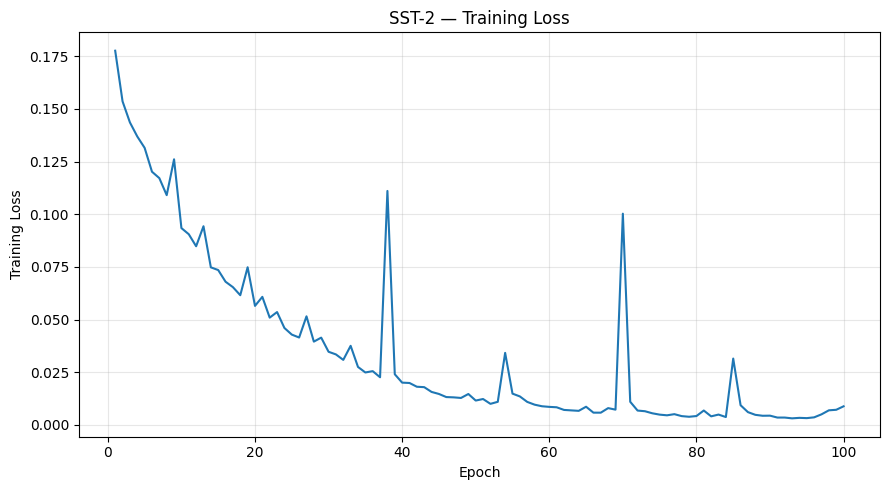

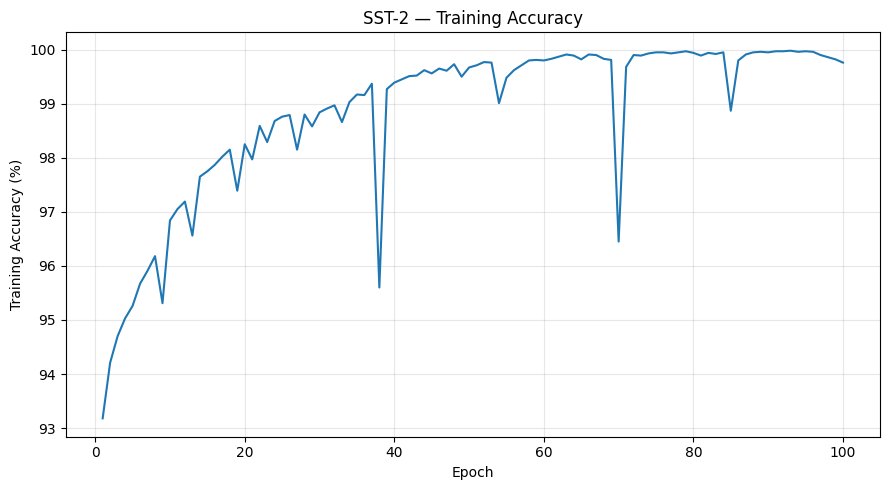

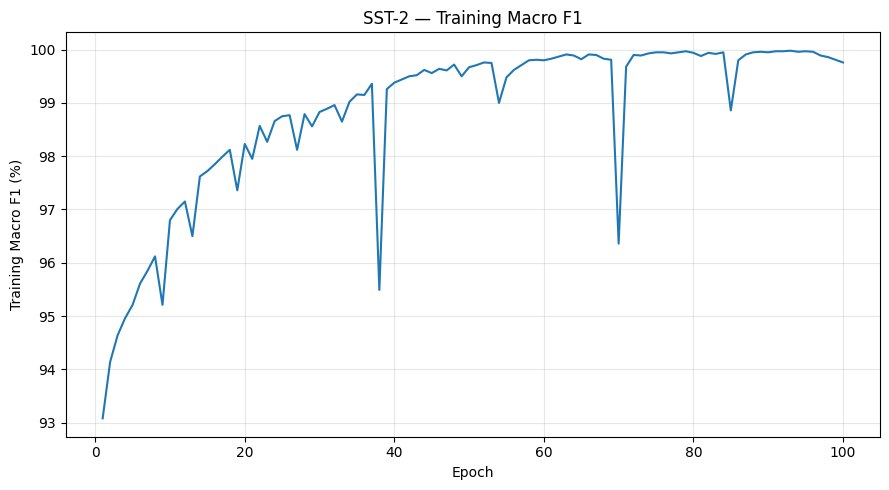


Final model saved:
/content/LLMEmbed-ACL2024/sst2_epoch100_acl_final_fusion.pt


ACL FINAL LLMEMBED — MR

LLaMA2 : /content/LLMEmbed-ACL2024/llama2_embedding/mr/dataset_tensor
BERT   : /content/LLMEmbed-ACL2024/bert_embedding/mr/dataset_tensor
RoBERTa: /content/LLMEmbed-ACL2024/roberta_embedding/mr/dataset_tensor

REPRESENTATION SHAPES
------------------------------------------------------------------------------------------------------------------------
LLaMA train   : (40000, 5, 4096)
BERT train    : (40000, 1024)
RoBERTa train : (40000, 1024)
Train labels  : (40000,)
LLaMA test    : (10000, 5, 4096)
BERT test     : (10000, 1024)
RoBERTa test  : (10000, 1024)
Test labels   : (10000,)


MR — TRAINING METRICS FOR ALL 100 EPOCHS
Epoch |       Loss |   Accuracy |    Macro P |    Macro R |   Macro F1 |  Weighted F1
------------------------------------------------------------------------------------------------------------------------
    1 |   0.147942 |     94.61% |     94.61% |     94.

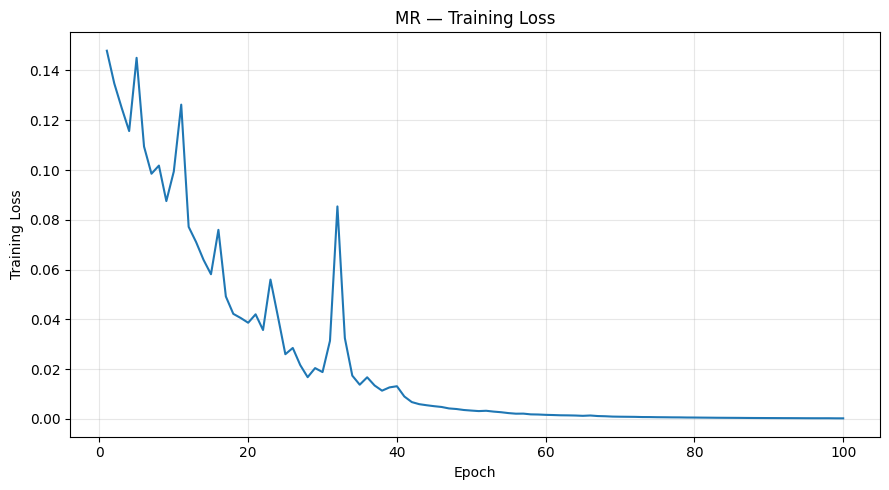

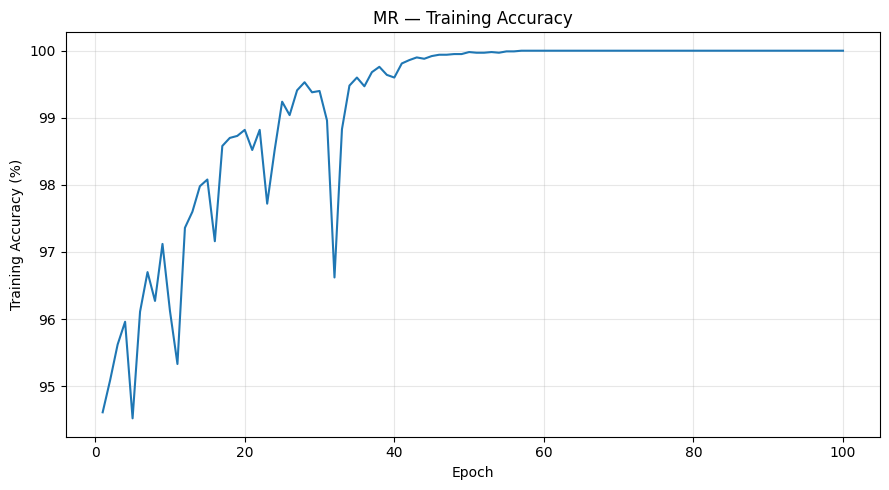

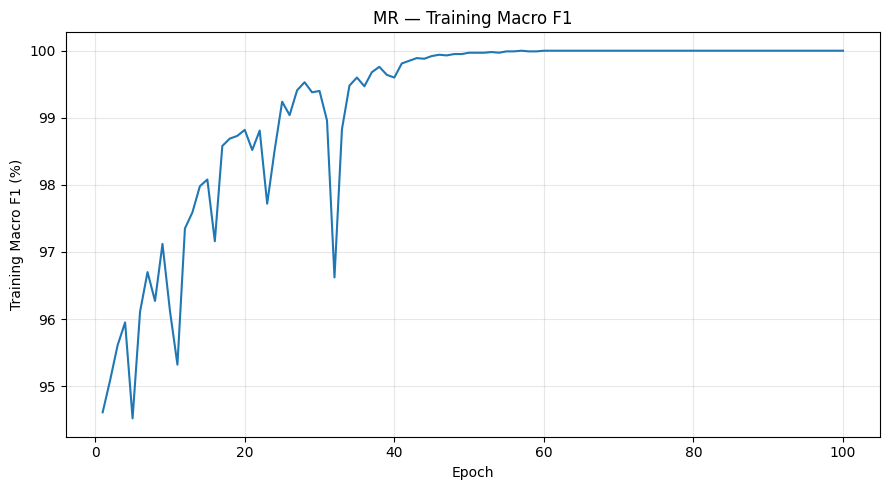


Final model saved:
/content/LLMEmbed-ACL2024/mr_epoch100_acl_final_fusion.pt


ACL FINAL LLMEMBED — AG News

LLaMA2 : /content/LLMEmbed-ACL2024/llama2_embedding/agnews/dataset_tensor
BERT   : /content/LLMEmbed-ACL2024/bert_embedding/agnews/dataset_tensor
RoBERTa: /content/LLMEmbed-ACL2024/roberta_embedding/agnews/dataset_tensor

REPRESENTATION SHAPES
------------------------------------------------------------------------------------------------------------------------
LLaMA train   : (120000, 5, 4096)
BERT train    : (120000, 1024)
RoBERTa train : (120000, 1024)
Train labels  : (120000,)
LLaMA test    : (7600, 5, 4096)
BERT test     : (7600, 1024)
RoBERTa test  : (7600, 1024)
Test labels   : (7600,)


AG News — TRAINING METRICS FOR ALL 100 EPOCHS
Epoch |       Loss |   Accuracy |    Macro P |    Macro R |   Macro F1 |  Weighted F1
------------------------------------------------------------------------------------------------------------------------
    1 |   0.197974 |     93.23% | 

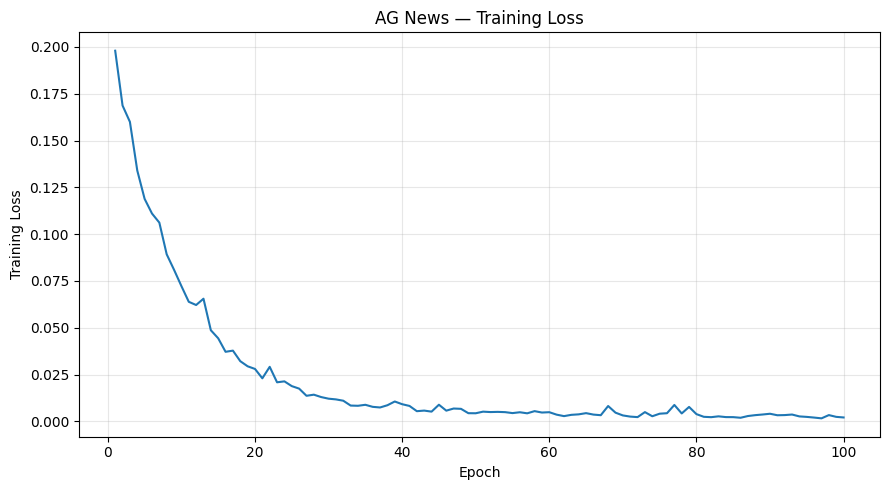

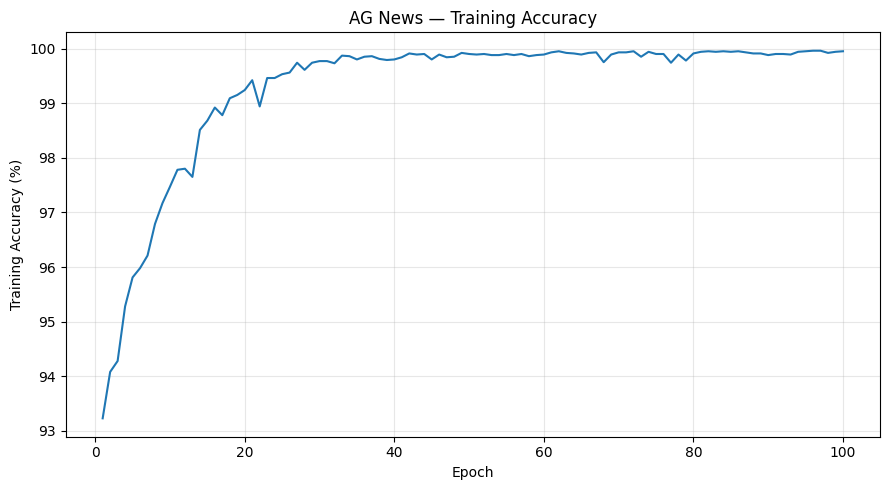

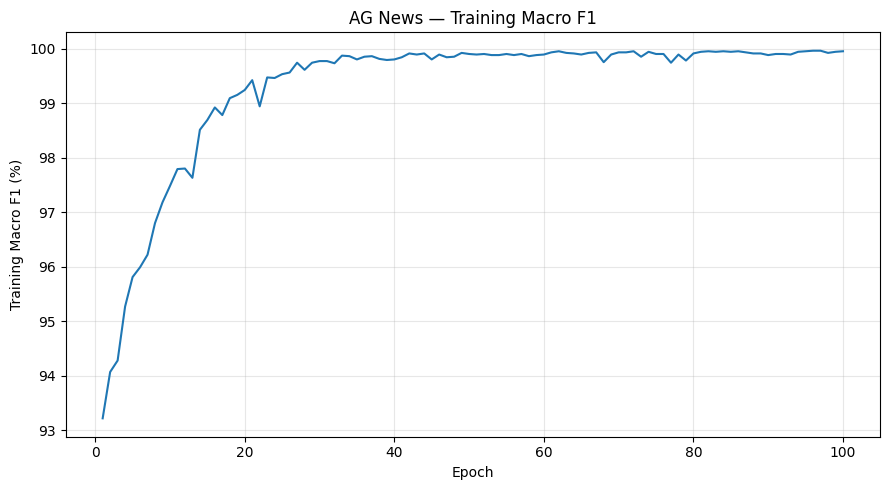


Final model saved:
/content/LLMEmbed-ACL2024/ag_news_epoch100_acl_final_fusion.pt


ACL FINAL LLMEMBED — R8

LLaMA2 : /content/LLMEmbed-ACL2024/llama2_embedding/r8/dataset_tensor
BERT   : /content/LLMEmbed-ACL2024/bert_embedding/r8/dataset_tensor
RoBERTa: /content/LLMEmbed-ACL2024/roberta_embedding/r8/dataset_tensor

REPRESENTATION SHAPES
------------------------------------------------------------------------------------------------------------------------
LLaMA train   : (5485, 5, 4096)
BERT train    : (5485, 1024)
RoBERTa train : (5485, 1024)
Train labels  : (5485,)
LLaMA test    : (2189, 5, 4096)
BERT test     : (2189, 1024)
RoBERTa test  : (2189, 1024)
Test labels   : (2189,)


R8 — TRAINING METRICS FOR ALL 100 EPOCHS
Epoch |       Loss |   Accuracy |    Macro P |    Macro R |   Macro F1 |  Weighted F1
------------------------------------------------------------------------------------------------------------------------
    1 |   0.685096 |     76.23% |     18.78% |     23.69% |

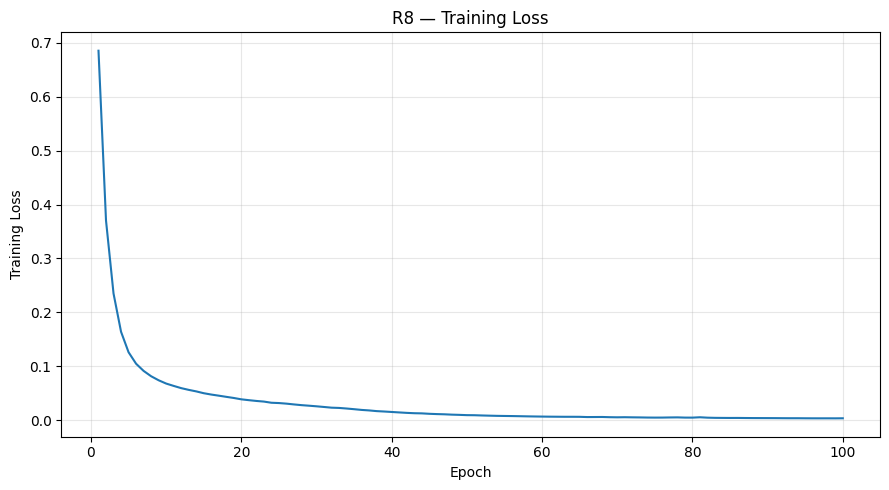

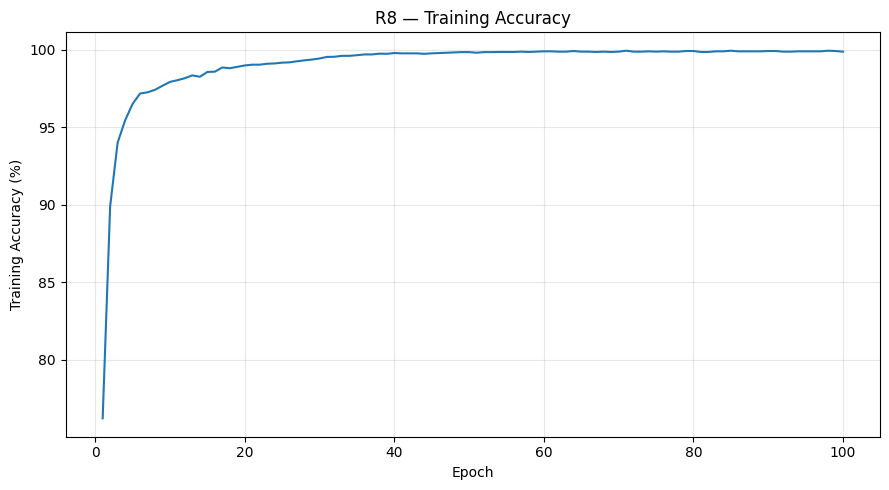

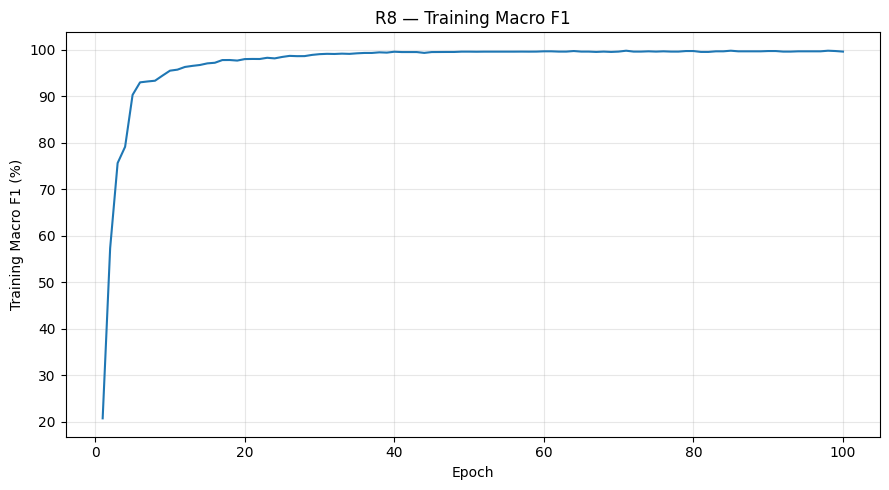


Final model saved:
/content/LLMEmbed-ACL2024/r8_epoch100_acl_final_fusion.pt


ACL FINAL LLMEMBED — R52

LLaMA2 : /content/LLMEmbed-ACL2024/llama2_embedding/r52/dataset_tensor
BERT   : /content/LLMEmbed-ACL2024/bert_embedding/r52/dataset_tensor
RoBERTa: /content/LLMEmbed-ACL2024/roberta_embedding/r52/dataset_tensor

REPRESENTATION SHAPES
------------------------------------------------------------------------------------------------------------------------
LLaMA train   : (6532, 5, 4096)
BERT train    : (6532, 1024)
RoBERTa train : (6532, 1024)
Train labels  : (6532,)
LLaMA test    : (2568, 5, 4096)
BERT test     : (2568, 1024)
RoBERTa test  : (2568, 1024)
Test labels   : (2568,)


R52 — TRAINING METRICS FOR ALL 100 EPOCHS
Epoch |       Loss |   Accuracy |    Macro P |    Macro R |   Macro F1 |  Weighted F1
------------------------------------------------------------------------------------------------------------------------
    1 |   1.527678 |     63.33% |      2.40% |      3.60% |

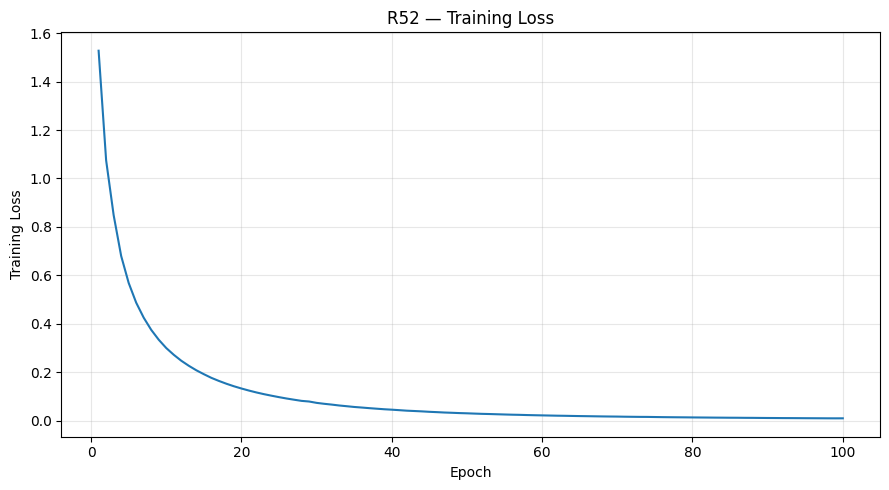

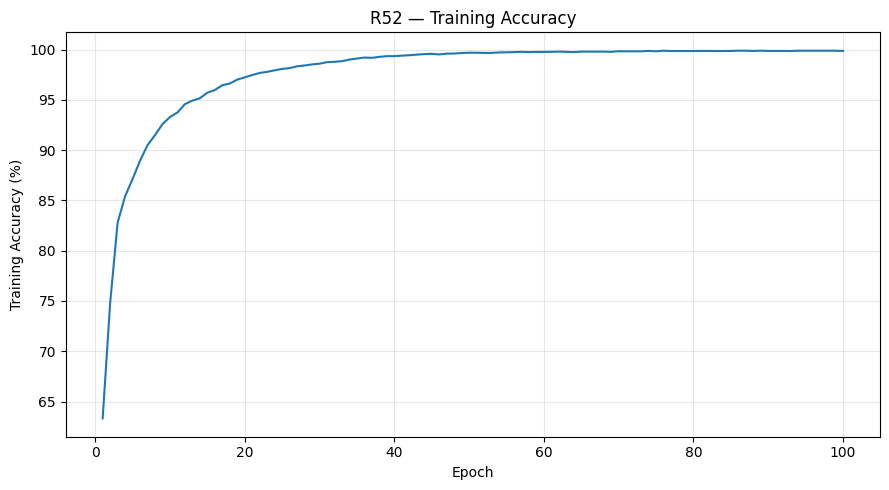

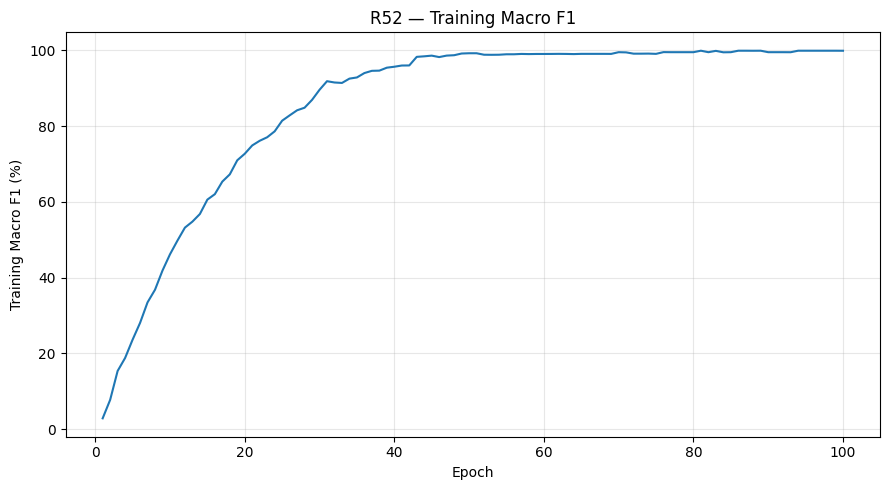


Final model saved:
/content/LLMEmbed-ACL2024/r52_epoch100_acl_final_fusion.pt


ALL FIVE DATASETS — COMPLETE TRAINING HISTORY


,Dataset,Epoch,Train Loss,Train Accuracy (%),Train Macro Precision (%),Train Macro Recall (%),Train Macro F1 (%),Train Weighted F1 (%)
0,SST-2,1,0.177621,93.18,93.11,93.06,93.08,93.18
1,SST-2,2,0.153575,94.21,94.10,94.19,94.14,94.22
2,SST-2,3,0.143584,94.70,94.53,94.79,94.64,94.71
3,SST-2,4,0.136909,95.03,94.98,94.94,94.96,95.03
4,SST-2,5,0.131505,95.26,95.07,95.44,95.21,95.27
...,...,...,...,...,...,...,...,...
495,R52,96,0.009518,99.88,99.91,99.92,99.92,99.88
496,R52,97,0.009373,99.88,99.91,99.92,99.92,99.88
497,R52,98,0.009186,99.88,99.91,99.92,99.92,99.88
498,R52,99,0.009090,99.88,99.91,99.92,99.92,99.88




TRAIN ACCURACY — ALL 100 EPOCHS


Dataset,SST-2,MR,AG News,R8,R52
Epoch,,,,,
1,93.18,94.61,93.23,76.23,63.33
2,94.21,95.09,94.08,89.90,74.79
3,94.70,95.62,94.28,94.00,82.79
4,95.03,95.96,95.28,95.44,85.41
5,95.26,94.52,95.81,96.50,87.12
...,...,...,...,...,...
96,99.96,100.00,99.96,99.89,99.88
97,99.90,100.00,99.96,99.89,99.88
98,99.86,100.00,99.92,99.93,99.88




TRAIN LOSS — ALL 100 EPOCHS


Dataset,SST-2,MR,AG News,R8,R52
Epoch,,,,,
1,0.177621,0.147942,0.197974,0.685096,1.527678
2,0.153575,0.134798,0.168698,0.370338,1.074932
3,0.143584,0.124923,0.159968,0.235118,0.848523
4,0.136909,0.115658,0.133991,0.164181,0.679844
5,0.131505,0.145089,0.118840,0.126270,0.568380
...,...,...,...,...,...
96,0.003563,0.000287,0.002040,0.003780,0.009518
97,0.004991,0.000284,0.001629,0.003763,0.009373
98,0.006896,0.000288,0.003364,0.003777,0.009186


... (2 outputs left out)



PRIMARY RQ1 RESULT — ORIGINAL ACL vs MY REPLICATION


,Dataset,Original ACL Accuracy (%),My Accuracy (%),Difference (pp)
0,SST-2,95.760,93.120,-2.640
1,MR,95.490,95.250,-0.240
2,AG News,95.830,94.390,-1.440
3,R8,98.220,97.530,-0.690
4,R52,95.680,94.980,-0.700
5,Average,96.196,95.054,-1.142




COMPLETE FINAL METRICS — EPOCH-100 MODEL


,Dataset,Original ACL Accuracy (%),My Accuracy (%),Difference (pp),Train Loss,Train Accuracy (%),Train Macro Precision (%),Train Macro Recall (%),Train Macro F1 (%),Train Weighted F1 (%),Test Loss,Test Macro Precision (%),Test Macro Recall (%),Test Macro F1 (%),Test Weighted F1 (%),Training Runtime (min),Test Runtime (sec)
0,SST-2,95.760,93.120,-2.640,0.008799,99.760,99.730,99.780,99.760,99.760,0.509736,93.120,93.120,93.120,93.12,10.35,0.060
1,MR,95.490,95.250,-0.240,0.000249,100.000,100.000,100.000,100.000,100.000,0.382253,95.250,95.250,95.250,95.25,6.01,0.510
2,AG News,95.830,94.390,-1.440,0.002099,99.950,99.950,99.950,99.950,99.950,0.385668,94.380,94.390,94.390,94.39,18.21,0.390
3,R8,98.220,97.530,-0.690,0.003848,99.870,99.560,99.580,99.560,99.870,0.081961,93.480,91.600,92.420,97.51,0.83,0.130
4,R52,95.680,94.980,-0.700,0.009176,99.860,99.900,99.920,99.910,99.860,0.180957,79.360,72.530,74.500,94.68,1.00,0.140
5,Average,96.196,95.054,-1.142,0.004834,99.888,99.828,99.846,99.836,99.888,0.308115,91.118,89.378,89.936,94.99,7.28,0.246


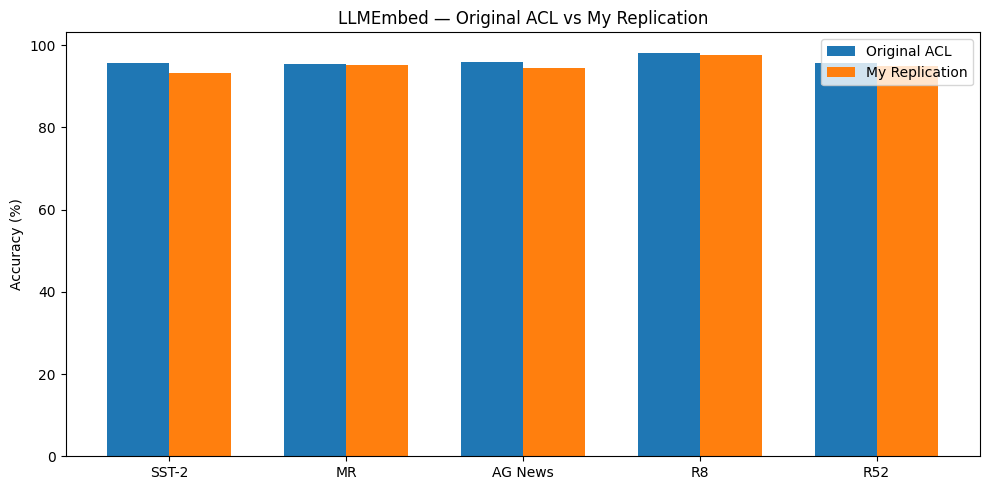



FINAL FIVE-DATASET LLMEMBED REPLICATION COMPLETE

PRIMARY REPLICATION TABLE:


,Dataset,Original ACL Accuracy (%),My Accuracy (%),Difference (pp)
0,SST-2,95.760,93.120,-2.640
1,MR,95.490,95.250,-0.240
2,AG News,95.830,94.390,-1.440
3,R8,98.220,97.530,-0.690
4,R52,95.680,94.980,-0.700
5,Average,96.196,95.054,-1.142



COMPLETE METRICS TABLE:


,Dataset,Original ACL Accuracy (%),My Accuracy (%),Difference (pp),Train Loss,Train Accuracy (%),Train Macro Precision (%),Train Macro Recall (%),Train Macro F1 (%),Train Weighted F1 (%),Test Loss,Test Macro Precision (%),Test Macro Recall (%),Test Macro F1 (%),Test Weighted F1 (%),Training Runtime (min),Test Runtime (sec)
0,SST-2,95.760,93.120,-2.640,0.008799,99.760,99.730,99.780,99.760,99.760,0.509736,93.120,93.120,93.120,93.12,10.35,0.060
1,MR,95.490,95.250,-0.240,0.000249,100.000,100.000,100.000,100.000,100.000,0.382253,95.250,95.250,95.250,95.25,6.01,0.510
2,AG News,95.830,94.390,-1.440,0.002099,99.950,99.950,99.950,99.950,99.950,0.385668,94.380,94.390,94.390,94.39,18.21,0.390
3,R8,98.220,97.530,-0.690,0.003848,99.870,99.560,99.580,99.560,99.870,0.081961,93.480,91.600,92.420,97.51,0.83,0.130
4,R52,95.680,94.980,-0.700,0.009176,99.860,99.900,99.920,99.910,99.860,0.180957,79.360,72.530,74.500,94.68,1.00,0.140
5,Average,96.196,95.054,-1.142,0.004834,99.888,99.828,99.846,99.836,99.888,0.308115,91.118,89.378,89.936,94.99,7.28,0.246



Saved files:
1. /content/LLMEmbed-ACL2024/all_five_datasets_training_history.csv
2. /content/LLMEmbed-ACL2024/all_datasets_train_accuracy_by_epoch.csv
3. /content/LLMEmbed-ACL2024/all_datasets_train_loss_by_epoch.csv
4. /content/LLMEmbed-ACL2024/all_datasets_train_macro_f1_by_epoch.csv
5. /content/LLMEmbed-ACL2024/llmembed_acl_vs_my_replication.csv
6. /content/LLMEmbed-ACL2024/llmembed_complete_final_metrics.csv
7. /content/LLMEmbed-ACL2024/llmembed_acl_vs_replication_accuracy.png

Per-dataset training curves:

SST-2
  train_loss_curve: /content/LLMEmbed-ACL2024/sst2_train_loss_curve.png
  train_accuracy_curve: /content/LLMEmbed-ACL2024/sst2_train_accuracy_curve.png
  train_macro_f1_curve: /content/LLMEmbed-ACL2024/sst2_train_macro_f1_curve.png

MR
  train_loss_curve: /content/LLMEmbed-ACL2024/mr_train_loss_curve.png
  train_accuracy_curve: /content/LLMEmbed-ACL2024/mr_train_accuracy_curve.png
  train_macro_f1_curve: /content/LLMEmbed-ACL2024/mr_train_macro_f1_curve.png

AG News
  tra

In [207]:
# ============================================================
# PART 9 — FINAL ACL-ALIGNED TRAINING + EVALUATION
#
# DESIGN:
#   - Train for exactly 100 epochs
#   - Record TRAIN metrics every epoch
#   - DO NOT inspect test performance during training
#   - Evaluate TEST set exactly once after Epoch 100
#
# PRIMARY REPLICATION METRIC:
#   - Test Accuracy
#
# ADDITIONAL DIAGNOSTIC METRICS:
#   - Loss
#   - Macro Precision
#   - Macro Recall
#   - Macro F1
#   - Weighted F1
# ============================================================

import os
import gc
import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

from torch.utils.data import DataLoader


# ============================================================
# PART 9A — METRIC FUNCTION
# ============================================================

@torch.no_grad()
def evaluate_complete(
    model,
    loader,
    criterion
):

    model.eval()

    total_loss = 0.0
    total_examples = 0

    all_true = []
    all_pred = []


    for (
        llama,
        bert,
        roberta,
        labels
    ) in loader:

        llama = llama.to(
            DEVICE,
            non_blocking=True
        )

        bert = bert.to(
            DEVICE,
            non_blocking=True
        )

        roberta = roberta.to(
            DEVICE,
            non_blocking=True
        )

        labels = labels.to(
            DEVICE,
            non_blocking=True
        )


        outputs = model(
            llama,
            bert,
            roberta
        )


        loss = criterion(
            outputs,
            labels
        )


        batch_size = labels.size(0)

        total_loss += (
            loss.item()
            *
            batch_size
        )

        total_examples += batch_size


        predictions = outputs.argmax(
            dim=1
        )


        all_true.extend(
            labels
            .detach()
            .cpu()
            .tolist()
        )

        all_pred.extend(
            predictions
            .detach()
            .cpu()
            .tolist()
        )


    # --------------------------------------------------------
    # LOSS
    # --------------------------------------------------------

    avg_loss = (
        total_loss
        /
        total_examples
    )


    # --------------------------------------------------------
    # CLASSIFICATION METRICS
    # --------------------------------------------------------

    accuracy = accuracy_score(
        all_true,
        all_pred
    ) * 100.0


    macro_precision = precision_score(
        all_true,
        all_pred,
        average="macro",
        zero_division=0
    ) * 100.0


    macro_recall = recall_score(
        all_true,
        all_pred,
        average="macro",
        zero_division=0
    ) * 100.0


    macro_f1 = f1_score(
        all_true,
        all_pred,
        average="macro",
        zero_division=0
    ) * 100.0


    weighted_f1 = f1_score(
        all_true,
        all_pred,
        average="weighted",
        zero_division=0
    ) * 100.0


    return {

        "Loss":
            avg_loss,

        "Accuracy (%)":
            accuracy,

        "Macro Precision (%)":
            macro_precision,

        "Macro Recall (%)":
            macro_recall,

        "Macro F1 (%)":
            macro_f1,

        "Weighted F1 (%)":
            weighted_f1,
    }


# ============================================================
# PART 9B — TRAINING CURVES
#
# IMPORTANT:
# These curves contain TRAINING metrics only.
# The test set is not repeatedly inspected.
# ============================================================

def plot_training_curves(
    epoch_df,
    dataset_name,
    save_dir
):

    safe_name = (
        dataset_name
        .lower()
        .replace("-", "")
        .replace(" ", "_")
    )


    # ========================================================
    # 1. TRAIN LOSS
    # ========================================================

    plt.figure(
        figsize=(9, 5)
    )

    plt.plot(
        epoch_df["Epoch"],
        epoch_df["Train Loss"]
    )

    plt.xlabel("Epoch")
    plt.ylabel("Training Loss")

    plt.title(
        f"{dataset_name} — Training Loss"
    )

    plt.grid(
        True,
        alpha=0.3
    )

    plt.tight_layout()


    loss_path = os.path.join(
        save_dir,
        f"{safe_name}_train_loss_curve.png"
    )


    plt.savefig(
        loss_path,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()


    # ========================================================
    # 2. TRAIN ACCURACY
    # ========================================================

    plt.figure(
        figsize=(9, 5)
    )

    plt.plot(
        epoch_df["Epoch"],
        epoch_df["Train Accuracy (%)"]
    )

    plt.xlabel("Epoch")
    plt.ylabel("Training Accuracy (%)")

    plt.title(
        f"{dataset_name} — Training Accuracy"
    )

    plt.grid(
        True,
        alpha=0.3
    )

    plt.tight_layout()


    accuracy_path = os.path.join(
        save_dir,
        f"{safe_name}_train_accuracy_curve.png"
    )


    plt.savefig(
        accuracy_path,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()


    # ========================================================
    # 3. TRAIN MACRO F1
    # ========================================================

    plt.figure(
        figsize=(9, 5)
    )

    plt.plot(
        epoch_df["Epoch"],
        epoch_df["Train Macro F1 (%)"]
    )

    plt.xlabel("Epoch")
    plt.ylabel("Training Macro F1 (%)")

    plt.title(
        f"{dataset_name} — Training Macro F1"
    )

    plt.grid(
        True,
        alpha=0.3
    )

    plt.tight_layout()


    f1_path = os.path.join(
        save_dir,
        f"{safe_name}_train_macro_f1_curve.png"
    )


    plt.savefig(
        f1_path,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()


    return {

        "train_loss_curve":
            loss_path,

        "train_accuracy_curve":
            accuracy_path,

        "train_macro_f1_curve":
            f1_path,
    }


# ============================================================
# PART 9C — TRAIN ONE DATASET
# ============================================================

def run_dataset(
    dataset_name,
    config
):

    print("\n")
    print("=" * 120)

    print(
        f"ACL FINAL LLMEMBED — {dataset_name}"
    )

    print("=" * 120)


    # ========================================================
    # LOAD REPRESENTATIONS
    # ========================================================

    (
        llama_train,
        bert_train,
        roberta_train,
        y_train,
        llama_test,
        bert_test,
        roberta_test,
        y_test,
    ) = load_dataset_representations(
        config["folder"]
    )


    # ========================================================
    # SHAPE SUMMARY
    # ========================================================

    print("\nREPRESENTATION SHAPES")
    print("-" * 120)

    print(
        "LLaMA train   :",
        tuple(llama_train.shape)
    )

    print(
        "BERT train    :",
        tuple(bert_train.shape)
    )

    print(
        "RoBERTa train :",
        tuple(roberta_train.shape)
    )

    print(
        "Train labels  :",
        tuple(y_train.shape)
    )

    print(
        "LLaMA test    :",
        tuple(llama_test.shape)
    )

    print(
        "BERT test     :",
        tuple(bert_test.shape)
    )

    print(
        "RoBERTa test  :",
        tuple(roberta_test.shape)
    )

    print(
        "Test labels   :",
        tuple(y_test.shape)
    )


    # ========================================================
    # ALIGNMENT CHECK
    # ========================================================

    assert (
        len(llama_train)
        ==
        len(bert_train)
        ==
        len(roberta_train)
        ==
        len(y_train)
    )


    assert (
        len(llama_test)
        ==
        len(bert_test)
        ==
        len(roberta_test)
        ==
        len(y_test)
    )


    # ========================================================
    # DATASETS
    # ========================================================

    train_dataset = LLMEmbedDataset(
        llama_train,
        bert_train,
        roberta_train,
        y_train
    )


    test_dataset = LLMEmbedDataset(
        llama_test,
        bert_test,
        roberta_test,
        y_test
    )


    # ========================================================
    # TRAINING LOADER
    # ========================================================

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        pin_memory=True
    )


    # ========================================================
    # TRAIN EVALUATION LOADER
    #
    # Used only to measure training metrics after each epoch.
    # ========================================================

    train_eval_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        pin_memory=True
    )


    # ========================================================
    # TEST LOADER
    #
    # This is NOT evaluated inside the epoch loop.
    # ========================================================

    test_loader = DataLoader(
        test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        pin_memory=True
    )


    # ========================================================
    # REPRODUCIBILITY
    # ========================================================

    set_seed(SEED)


    # ========================================================
    # MODEL
    # ========================================================

    model = ACLFinalFusion(
        num_classes=config["classes"],
        sigma=SIGMA
    ).to(DEVICE)


    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LR
    )


    criterion = nn.CrossEntropyLoss()


    # ========================================================
    # HISTORY
    # ========================================================

    epoch_history = []


    print("\n")
    print("=" * 120)

    print(
        f"{dataset_name} — "
        f"TRAINING METRICS FOR ALL {EPOCHS} EPOCHS"
    )

    print("=" * 120)


    print(
        f"{'Epoch':>5} | "
        f"{'Loss':>10} | "
        f"{'Accuracy':>10} | "
        f"{'Macro P':>10} | "
        f"{'Macro R':>10} | "
        f"{'Macro F1':>10} | "
        f"{'Weighted F1':>12}"
    )

    print("-" * 120)


    # ========================================================
    # TRAINING TIMER
    # ========================================================

    training_start = time.time()


    # ========================================================
    # 100-EPOCH TRAINING LOOP
    # ========================================================

    for epoch in range(
        1,
        EPOCHS + 1
    ):

        model.train()


        # ====================================================
        # OPTIMIZATION PASS
        # ====================================================

        for (
            llama,
            bert,
            roberta,
            labels
        ) in train_loader:

            llama = llama.to(
                DEVICE,
                non_blocking=True
            )

            bert = bert.to(
                DEVICE,
                non_blocking=True
            )

            roberta = roberta.to(
                DEVICE,
                non_blocking=True
            )

            labels = labels.to(
                DEVICE,
                non_blocking=True
            )


            optimizer.zero_grad(
                set_to_none=True
            )


            outputs = model(
                llama,
                bert,
                roberta
            )


            loss = criterion(
                outputs,
                labels
            )


            loss.backward()

            optimizer.step()


        # ====================================================
        # TRAINING METRICS AFTER THIS EPOCH
        #
        # No test-set access occurs here.
        # ====================================================

        train_metrics = evaluate_complete(
            model,
            train_eval_loader,
            criterion
        )


        # ====================================================
        # STORE TRAINING HISTORY
        # ====================================================

        row = {

            "Dataset":
                dataset_name,

            "Epoch":
                epoch,

            "Train Loss":
                train_metrics[
                    "Loss"
                ],

            "Train Accuracy (%)":
                train_metrics[
                    "Accuracy (%)"
                ],

            "Train Macro Precision (%)":
                train_metrics[
                    "Macro Precision (%)"
                ],

            "Train Macro Recall (%)":
                train_metrics[
                    "Macro Recall (%)"
                ],

            "Train Macro F1 (%)":
                train_metrics[
                    "Macro F1 (%)"
                ],

            "Train Weighted F1 (%)":
                train_metrics[
                    "Weighted F1 (%)"
                ],
        }


        epoch_history.append(
            row
        )


        # ====================================================
        # PRINT EVERY EPOCH
        # ====================================================

        print(
            f"{epoch:>5} | "
            f"{row['Train Loss']:>10.6f} | "
            f"{row['Train Accuracy (%)']:>9.2f}% | "
            f"{row['Train Macro Precision (%)']:>9.2f}% | "
            f"{row['Train Macro Recall (%)']:>9.2f}% | "
            f"{row['Train Macro F1 (%)']:>9.2f}% | "
            f"{row['Train Weighted F1 (%)']:>11.2f}%"
        )


    # ========================================================
    # TRAINING COMPLETE
    # ========================================================

    training_runtime = (
        time.time()
        -
        training_start
    )


    # ========================================================
    # CREATE EPOCH TABLE
    # ========================================================

    epoch_df = pd.DataFrame(
        epoch_history
    )


    # ========================================================
    # ROUND TABLE VALUES
    # ========================================================

    epoch_df[
        "Train Loss"
    ] = epoch_df[
        "Train Loss"
    ].round(6)


    metric_columns = [

        "Train Accuracy (%)",

        "Train Macro Precision (%)",

        "Train Macro Recall (%)",

        "Train Macro F1 (%)",

        "Train Weighted F1 (%)",
    ]


    epoch_df[
        metric_columns
    ] = epoch_df[
        metric_columns
    ].round(2)


    # ========================================================
    # TEST SET EVALUATION
    #
    # IMPORTANT:
    # FIRST AND ONLY TEST EVALUATION.
    # MODEL IS THE EPOCH-100 MODEL.
    # ========================================================

    print("\n")
    print("=" * 120)

    print(
        f"{dataset_name} — "
        "FINAL EPOCH-100 TEST EVALUATION"
    )

    print("=" * 120)


    test_start = time.time()


    test_metrics = evaluate_complete(
        model,
        test_loader,
        criterion
    )


    inference_runtime = (
        time.time()
        -
        test_start
    )


    # ========================================================
    # FINAL TRAINING METRICS
    # ========================================================

    final_train = (
        epoch_history[-1]
    )


    # ========================================================
    # ACL PAPER ACCURACY
    # ========================================================

    paper_accuracy = float(
        config[
            "paper_accuracy"
        ]
    )


    # ========================================================
    # YOUR REPLICATION ACCURACY
    # ========================================================

    my_accuracy = float(
        test_metrics[
            "Accuracy (%)"
        ]
    )


    difference = (
        my_accuracy
        -
        paper_accuracy
    )


    # ========================================================
    # PRINT FINAL RESULT
    # ========================================================

    print(
        f"\nOriginal ACL Accuracy     : "
        f"{paper_accuracy:.2f}%"
    )


    print(
        f"My Replication Accuracy   : "
        f"{my_accuracy:.2f}%"
    )


    print(
        f"Difference                : "
        f"{difference:+.2f} pp"
    )


    print("\nFINAL TRAIN METRICS")
    print("-" * 70)


    print(
        f"Train Loss                : "
        f"{final_train['Train Loss']:.6f}"
    )


    print(
        f"Train Accuracy            : "
        f"{final_train['Train Accuracy (%)']:.2f}%"
    )


    print(
        f"Train Macro Precision     : "
        f"{final_train['Train Macro Precision (%)']:.2f}%"
    )


    print(
        f"Train Macro Recall        : "
        f"{final_train['Train Macro Recall (%)']:.2f}%"
    )


    print(
        f"Train Macro F1            : "
        f"{final_train['Train Macro F1 (%)']:.2f}%"
    )


    print(
        f"Train Weighted F1         : "
        f"{final_train['Train Weighted F1 (%)']:.2f}%"
    )


    print("\nFINAL TEST METRICS")
    print("-" * 70)


    print(
        f"Test Loss                 : "
        f"{test_metrics['Loss']:.6f}"
    )


    print(
        f"Test Accuracy             : "
        f"{test_metrics['Accuracy (%)']:.2f}%"
    )


    print(
        f"Test Macro Precision      : "
        f"{test_metrics['Macro Precision (%)']:.2f}%"
    )


    print(
        f"Test Macro Recall         : "
        f"{test_metrics['Macro Recall (%)']:.2f}%"
    )


    print(
        f"Test Macro F1             : "
        f"{test_metrics['Macro F1 (%)']:.2f}%"
    )


    print(
        f"Test Weighted F1          : "
        f"{test_metrics['Weighted F1 (%)']:.2f}%"
    )


    print("\nRUNTIME")
    print("-" * 70)


    print(
        f"Training Runtime          : "
        f"{training_runtime:.2f} sec "
        f"({training_runtime / 60:.2f} min)"
    )


    print(
        f"Final Test Runtime        : "
        f"{inference_runtime:.2f} sec"
    )


    # ========================================================
    # SAVE PER-EPOCH TRAINING HISTORY
    # ========================================================

    safe_name = (
        dataset_name
        .lower()
        .replace("-", "")
        .replace(" ", "_")
    )


    history_path = os.path.join(
        REPO,
        f"{safe_name}_training_history.csv"
    )


    epoch_df.to_csv(
        history_path,
        index=False
    )


    print(
        "\nTraining history saved:"
    )

    print(
        history_path
    )


    # ========================================================
    # TRAINING CURVES
    # ========================================================

    curve_paths = plot_training_curves(
        epoch_df,
        dataset_name,
        REPO
    )


    # ========================================================
    # SAVE FINAL MODEL
    # ========================================================

    model_path = os.path.join(
        REPO,
        f"{safe_name}_epoch100_acl_final_fusion.pt"
    )


    torch.save(
        model.state_dict(),
        model_path
    )


    print(
        "\nFinal model saved:"
    )

    print(
        model_path
    )


    # ========================================================
    # FINAL RESULT RECORD
    # ========================================================

    result = {

        "Dataset":
            dataset_name,

        "Original ACL Accuracy (%)":
            paper_accuracy,

        "My Accuracy (%)":
            my_accuracy,

        "Difference (pp)":
            difference,


        # ----------------------------------------------------
        # FINAL TRAIN
        # ----------------------------------------------------

        "Train Loss":
            float(
                final_train[
                    "Train Loss"
                ]
            ),

        "Train Accuracy (%)":
            float(
                final_train[
                    "Train Accuracy (%)"
                ]
            ),

        "Train Macro Precision (%)":
            float(
                final_train[
                    "Train Macro Precision (%)"
                ]
            ),

        "Train Macro Recall (%)":
            float(
                final_train[
                    "Train Macro Recall (%)"
                ]
            ),

        "Train Macro F1 (%)":
            float(
                final_train[
                    "Train Macro F1 (%)"
                ]
            ),

        "Train Weighted F1 (%)":
            float(
                final_train[
                    "Train Weighted F1 (%)"
                ]
            ),


        # ----------------------------------------------------
        # FINAL TEST
        # ----------------------------------------------------

        "Test Loss":
            float(
                test_metrics[
                    "Loss"
                ]
            ),

        "Test Accuracy (%)":
            float(
                test_metrics[
                    "Accuracy (%)"
                ]
            ),

        "Test Macro Precision (%)":
            float(
                test_metrics[
                    "Macro Precision (%)"
                ]
            ),

        "Test Macro Recall (%)":
            float(
                test_metrics[
                    "Macro Recall (%)"
                ]
            ),

        "Test Macro F1 (%)":
            float(
                test_metrics[
                    "Macro F1 (%)"
                ]
            ),

        "Test Weighted F1 (%)":
            float(
                test_metrics[
                    "Weighted F1 (%)"
                ]
            ),


        # ----------------------------------------------------
        # RUNTIME
        # ----------------------------------------------------

        "Training Runtime (min)":
            training_runtime / 60.0,

        "Test Runtime (sec)":
            inference_runtime,
    }


    # ========================================================
    # CLEANUP
    # ========================================================

    del model
    del optimizer

    del llama_train
    del bert_train
    del roberta_train

    del llama_test
    del bert_test
    del roberta_test

    del y_train
    del y_test

    del train_dataset
    del test_dataset

    del train_loader
    del train_eval_loader
    del test_loader


    gc.collect()


    if torch.cuda.is_available():

        torch.cuda.empty_cache()


    return (
        result,
        epoch_df,
        curve_paths
    )


# ============================================================
# PART 10 — VERIFY ACL REFERENCE ACCURACIES
#
# These are Table 2:
# Cat + Co + Avg + Cat
# ============================================================

ACL_EXPECTED = {

    "SST-2":
        95.76,

    "MR":
        95.49,

    "AG News":
        95.83,

    "R8":
        98.22,

    "R52":
        95.68,
}


print("\n")
print("=" * 100)
print("VERIFYING ACL REFERENCE ACCURACIES")
print("=" * 100)


for dataset_name, expected in ACL_EXPECTED.items():

    assert dataset_name in DATASETS, (
        f"{dataset_name} missing from DATASETS"
    )


    actual = float(
        DATASETS[
            dataset_name
        ][
            "paper_accuracy"
        ]
    )


    assert abs(
        actual - expected
    ) < 1e-9, (
        f"{dataset_name}: "
        f"paper_accuracy={actual}, "
        f"expected={expected}"
    )


    print(
        f"✓ {dataset_name:<10} "
        f"{actual:.2f}%"
    )


print(
    "\n✓ ACL reference accuracies verified"
)


# ============================================================
# PART 11 — RUN ALL FIVE ORIGINAL BENCHMARKS
# ============================================================

results = []

all_epoch_tables = []

all_curve_paths = {}


for dataset_name, config in DATASETS.items():

    (
        result,
        epoch_df,
        curves
    ) = run_dataset(
        dataset_name,
        config
    )


    results.append(
        result
    )


    all_epoch_tables.append(
        epoch_df
    )


    all_curve_paths[
        dataset_name
    ] = curves


# ============================================================
# PART 12 — COMBINE ALL TRAINING EPOCHS
# ============================================================

all_epochs_df = pd.concat(
    all_epoch_tables,
    ignore_index=True
)


print("\n")
print("=" * 120)

print(
    "ALL FIVE DATASETS — "
    "COMPLETE TRAINING HISTORY"
)

print("=" * 120)


display(
    all_epochs_df
)


# ============================================================
# PART 13 — TRAIN ACCURACY TABLE
#
# Rows    = Epoch 1 ... 100
# Columns = SST-2, MR, AG News, R8, R52
# ============================================================

train_accuracy_table = (
    all_epochs_df
    .pivot(
        index="Epoch",
        columns="Dataset",
        values="Train Accuracy (%)"
    )
)


preferred_order = [

    "SST-2",

    "MR",

    "AG News",

    "R8",

    "R52",
]


available_order = [

    dataset

    for dataset in preferred_order

    if dataset
    in train_accuracy_table.columns
]


train_accuracy_table = (
    train_accuracy_table[
        available_order
    ]
)


print("\n")
print("=" * 120)

print(
    "TRAIN ACCURACY — ALL 100 EPOCHS"
)

print("=" * 120)


display(
    train_accuracy_table
)


# ============================================================
# PART 14 — TRAIN LOSS TABLE
# ============================================================

train_loss_table = (
    all_epochs_df
    .pivot(
        index="Epoch",
        columns="Dataset",
        values="Train Loss"
    )
)


train_loss_table = (
    train_loss_table[
        [
            dataset

            for dataset
            in preferred_order

            if dataset
            in train_loss_table.columns
        ]
    ]
)


print("\n")
print("=" * 120)

print(
    "TRAIN LOSS — ALL 100 EPOCHS"
)

print("=" * 120)


display(
    train_loss_table
)


# ============================================================
# PART 15 — TRAIN MACRO-F1 TABLE
# ============================================================

train_f1_table = (
    all_epochs_df
    .pivot(
        index="Epoch",
        columns="Dataset",
        values="Train Macro F1 (%)"
    )
)


train_f1_table = (
    train_f1_table[
        [
            dataset

            for dataset
            in preferred_order

            if dataset
            in train_f1_table.columns
        ]
    ]
)


print("\n")
print("=" * 120)

print(
    "TRAIN MACRO-F1 — ALL 100 EPOCHS"
)

print("=" * 120)


display(
    train_f1_table
)


# ============================================================
# PART 16 — FINAL RESULTS TABLE
# ============================================================

results_df = pd.DataFrame(
    results
)


# ============================================================
# ORDER DATASETS
# ============================================================

dataset_order = {

    "SST-2": 0,

    "MR": 1,

    "AG News": 2,

    "R8": 3,

    "R52": 4,
}


results_df[
    "_order"
] = results_df[
    "Dataset"
].map(
    dataset_order
)


results_df = (
    results_df
    .sort_values(
        "_order"
    )
    .drop(
        columns="_order"
    )
    .reset_index(
        drop=True
    )
)


# ============================================================
# ROUND VALUES
# ============================================================

loss_columns = [

    "Train Loss",

    "Test Loss",
]


for column in loss_columns:

    results_df[
        column
    ] = results_df[
        column
    ].round(6)


percentage_columns = [

    "Original ACL Accuracy (%)",

    "My Accuracy (%)",

    "Difference (pp)",

    "Train Accuracy (%)",

    "Train Macro Precision (%)",

    "Train Macro Recall (%)",

    "Train Macro F1 (%)",

    "Train Weighted F1 (%)",

    "Test Accuracy (%)",

    "Test Macro Precision (%)",

    "Test Macro Recall (%)",

    "Test Macro F1 (%)",

    "Test Weighted F1 (%)",

    "Training Runtime (min)",

    "Test Runtime (sec)",
]


for column in percentage_columns:

    results_df[
        column
    ] = results_df[
        column
    ].round(2)


# ============================================================
# PART 17 — ADD AVERAGE ROW
# ============================================================

average_row = {

    "Dataset":
        "Average"
}


for column in results_df.columns:

    if column == "Dataset":

        continue


    average_row[
        column
    ] = results_df[
        column
    ].mean()


results_with_average_df = pd.concat(
    [
        results_df,

        pd.DataFrame(
            [average_row]
        )
    ],
    ignore_index=True
)


# ============================================================
# PART 18 — PRIMARY ACL REPLICATION TABLE
#
# This is the most important table for RQ1.
# ============================================================

primary_comparison_df = (
    results_with_average_df[
        [
            "Dataset",

            "Original ACL Accuracy (%)",

            "My Accuracy (%)",

            "Difference (pp)",
        ]
    ]
    .copy()
)


print("\n")
print("=" * 100)

print(
    "PRIMARY RQ1 RESULT — "
    "ORIGINAL ACL vs MY REPLICATION"
)

print("=" * 100)


display(
    primary_comparison_df
)


# ============================================================
# PART 19 — COMPLETE FINAL METRICS TABLE
# ============================================================

complete_final_df = (
    results_with_average_df[
        [
            "Dataset",

            "Original ACL Accuracy (%)",

            "My Accuracy (%)",

            "Difference (pp)",

            "Train Loss",

            "Train Accuracy (%)",

            "Train Macro Precision (%)",

            "Train Macro Recall (%)",

            "Train Macro F1 (%)",

            "Train Weighted F1 (%)",

            "Test Loss",

            "Test Macro Precision (%)",

            "Test Macro Recall (%)",

            "Test Macro F1 (%)",

            "Test Weighted F1 (%)",

            "Training Runtime (min)",

            "Test Runtime (sec)",
        ]
    ]
    .copy()
)


print("\n")
print("=" * 160)

print(
    "COMPLETE FINAL METRICS — "
    "EPOCH-100 MODEL"
)

print("=" * 160)


display(
    complete_final_df
)


# ============================================================
# PART 20 — ORIGINAL ACL vs MY ACCURACY FIGURE
# ============================================================

comparison_plot_df = (
    results_df.copy()
)


x = np.arange(
    len(
        comparison_plot_df
    )
)


width = 0.35


plt.figure(
    figsize=(10, 5)
)


plt.bar(
    x - width / 2,

    comparison_plot_df[
        "Original ACL Accuracy (%)"
    ],

    width,

    label="Original ACL"
)


plt.bar(
    x + width / 2,

    comparison_plot_df[
        "My Accuracy (%)"
    ],

    width,

    label="My Replication"
)


plt.xticks(
    x,

    comparison_plot_df[
        "Dataset"
    ]
)


plt.ylabel(
    "Accuracy (%)"
)


plt.title(
    "LLMEmbed — Original ACL vs My Replication"
)


plt.legend()


plt.tight_layout()


comparison_figure_path = os.path.join(
    REPO,
    "llmembed_acl_vs_replication_accuracy.png"
)


plt.savefig(
    comparison_figure_path,
    dpi=200,
    bbox_inches="tight"
)


plt.show()
plt.close()


# ============================================================
# PART 21 — SAVE ALL RESULTS
# ============================================================

all_epochs_path = os.path.join(
    REPO,
    "all_five_datasets_training_history.csv"
)


train_accuracy_path = os.path.join(
    REPO,
    "all_datasets_train_accuracy_by_epoch.csv"
)


train_loss_path = os.path.join(
    REPO,
    "all_datasets_train_loss_by_epoch.csv"
)


train_f1_path = os.path.join(
    REPO,
    "all_datasets_train_macro_f1_by_epoch.csv"
)


primary_results_path = os.path.join(
    REPO,
    "llmembed_acl_vs_my_replication.csv"
)


complete_results_path = os.path.join(
    REPO,
    "llmembed_complete_final_metrics.csv"
)


# ============================================================
# SAVE
# ============================================================

all_epochs_df.to_csv(
    all_epochs_path,
    index=False
)


train_accuracy_table.to_csv(
    train_accuracy_path
)


train_loss_table.to_csv(
    train_loss_path
)


train_f1_table.to_csv(
    train_f1_path
)


primary_comparison_df.to_csv(
    primary_results_path,
    index=False
)


complete_final_df.to_csv(
    complete_results_path,
    index=False
)


# ============================================================
# PART 22 — FINAL SUMMARY
# ============================================================

print("\n")
print("=" * 120)

print(
    "FINAL FIVE-DATASET LLMEMBED REPLICATION COMPLETE"
)

print("=" * 120)


print(
    "\nPRIMARY REPLICATION TABLE:"
)

display(
    primary_comparison_df
)


print(
    "\nCOMPLETE METRICS TABLE:"
)

display(
    complete_final_df
)


print(
    "\nSaved files:"
)


print(
    "1.",
    all_epochs_path
)


print(
    "2.",
    train_accuracy_path
)


print(
    "3.",
    train_loss_path
)


print(
    "4.",
    train_f1_path
)


print(
    "5.",
    primary_results_path
)


print(
    "6.",
    complete_results_path
)


print(
    "7.",
    comparison_figure_path
)


print(
    "\nPer-dataset training curves:"
)


for dataset_name, paths in (
    all_curve_paths.items()
):

    print(
        f"\n{dataset_name}"
    )


    for curve_name, path in (
        paths.items()
    ):

        print(
            f"  {curve_name}: {path}"
        )


print("\n")
print("=" * 120)

print(
    "METHODOLOGICAL NOTE"
)

print("=" * 120)


print(
    "• Classifier trained for exactly "
    f"{EPOCHS} epochs."
)


print(
    "• Training metrics recorded after every epoch."
)


print(
    "• Test set evaluated once after Epoch 100."
)


print(
    "• Test accuracy is the primary ACL replication metric."
)


print(
    "• Precision, recall, F1 and loss are "
    "additional diagnostic metrics."
)


print(
    "• No best epoch was selected using test performance."
)


print("=" * 120)

**End of archived five-dataset RQ1 execution.** The sections below continue with the original RQ2–RQ4 material from the target notebook. Do not confuse these saved RQ1 outputs with new results from the combined notebook.

## RQ2 — Generalisation to additional datasets
This section retains the extension training cell. Previously displayed results are historical and must be regenerated if model settings change.


In [83]:
# Run new dataset experiments
# Source: original uploaded notebook, cell 95.
# Saved outputs are historical; rerun in Colab to reproduce.


# ============================================================
# STEP 3 — RQ2 NEW DATASET TRAINING
# ============================================================

rq2_results = train_group(
    RQ2,
    "RQ2_new"
)

print("\nRQ2 — FINAL NEW DATASET RESULTS")

display(
    rq2_results[
        [
            "Dataset",
            "Accuracy",
            "Macro-F1",
            "Precision",
            "Recall",
            "Status"
        ]
    ]
)





GROUP: RQ2_new
DATASET: BANKING77
Existing metrics found: /content/drive/MyDrive/COMP8240_LLMEmbed/results_v2/banking77/paper100_seed42/metrics.json
Accuracy: 0.5912337662337662
Macro-F1: 0.47092138210387924

GROUP: RQ2_new
DATASET: CLINC150
Starting 100-epoch training...
LLMEMBED TRAINING
Dataset: clinc150
Classes: 150
Training examples: 15000
Evaluation examples: 4500
Epochs: 100
SIGMA: 0.4
Batch size: 32
Learning rate: 0.0001
Seed: 42
Epoch 01/100 | Loss=4.96504 | Accuracy=0.06413
Epoch 02/100 | Loss=4.84997 | Accuracy=0.18367
Epoch 03/100 | Loss=4.77970 | Accuracy=0.25407
Epoch 04/100 | Loss=4.72824 | Accuracy=0.30627
Epoch 05/100 | Loss=4.67107 | Accuracy=0.36660
Epoch 06/100 | Loss=4.61953 | Accuracy=0.41713
Epoch 07/100 | Loss=4.58887 | Accuracy=0.44480
Epoch 08/100 | Loss=4.57000 | Accuracy=0.46060
Epoch 09/100 | Loss=4.55090 | Accuracy=0.47927
Epoch 10/100 | Loss=4.53478 | Accuracy=0.49513
Epoch 11/100 | Loss=4.51549 | Accuracy=0.51500
Epoch 12/100 | Loss=4.49580 | Accuracy=0

,Dataset,Epochs requested,Accuracy,Macro-F1,Precision,Recall,Training seconds,Status
0,BANKING77,100,0.591234,0.470921,0.405594,0.591234,85.366028,Metrics saved
1,CLINC150,100,0.892444,0.862097,0.843574,0.892444,315.453499,Metrics saved
2,TREC,100,0.934000,0.921136,0.925971,0.923185,115.009061,Metrics saved
3,TWEETEVAL,100,0.687642,0.684390,0.679541,0.690951,976.804806,Metrics saved
4,20NG,100,0.712825,0.701515,0.710774,0.700383,241.605359,Metrics saved



RQ2 — FINAL NEW DATASET RESULTS


,Dataset,Accuracy,Macro-F1,Precision,Recall,Status
0,BANKING77,0.591234,0.470921,0.405594,0.591234,Metrics saved
1,CLINC150,0.892444,0.862097,0.843574,0.892444,Metrics saved
2,TREC,0.934000,0.921136,0.925971,0.923185,Metrics saved
3,TWEETEVAL,0.687642,0.684390,0.679541,0.690951,Metrics saved
4,20NG,0.712825,0.701515,0.710774,0.700383,Metrics saved


## RQ3 — Low-data study
Stratified fractions and repeated seeds. Check that the same classifier architecture and representation paths are used as in RQ1/RQ2.


In [84]:
# RQ3 configuration
# Source: original uploaded notebook, cell 96.
# Saved outputs are historical; rerun in Colab to reproduce.


from pathlib import Path
import pandas as pd
import numpy as np
import torch
import json
import time
import gc
import random

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    cohen_kappa_score
)
from IPython.display import display

BASE = Path("/content/drive/MyDrive/COMP8240_LLMEmbed")

DATA_DIR = BASE / "prepared_datasets"
REP_DIR = BASE / "representations_v2"
RESULT_DIR = BASE / "results_v2"

RQ3_DIR = RESULT_DIR / "RQ3_low_data"
RQ4_DIR = RESULT_DIR / "RQ4_robustness"
EFF_DIR = RESULT_DIR / "efficiency"
LRD_DIR = BASE / "LRD"

for folder in [RQ3_DIR, RQ4_DIR, EFF_DIR, LRD_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

PRIORITY = ["banking77", "clinc150", "20ng"]
BACKBONES = ["llama2", "bert", "roberta"]

EPOCHS = 100
BATCH_SIZE = 32
LR = 1e-4
SIGMA = 0.4

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

required_functions = [
    "train_and_evaluate",
    "DownstreamModel",
    "load_encoder",
    "encode_batch",
    "release_encoder"
]

for name in required_functions:
    print(
        name,
        "READY" if callable(globals().get(name)) else "MISSING"
    )

print("Device:", DEVICE)


train_and_evaluate READY
DownstreamModel READY
load_encoder READY
encode_batch READY
release_encoder READY
Device: cuda


In [85]:
# RQ3 checkpoint lookup
# Source: original uploaded notebook, cell 97.
# Saved outputs are historical; rerun in Colab to reproduce.


def find_full_run(task):
    root = RESULT_DIR / task

    if not root.exists():
        return None

    candidates = []

    for metrics_path in root.glob("*/metrics.json"):
        folder = metrics_path.parent
        checkpoint = folder / "model_state.pt"

        if not checkpoint.exists():
            continue

        try:
            m = json.loads(metrics_path.read_text())

            if (
                float(m.get("fraction", -1)) == 1.0
                and int(m.get("epochs", -1)) == 100
                and int(m.get("n_train", 0)) > 0
            ):
                candidates.append({
                    "folder": folder,
                    "metrics": m
                })
        except Exception:
            continue

    if not candidates:
        return None

    return sorted(
        candidates,
        key=lambda x: x["folder"].name
    )[0]

full_runs = {}
rows = []

for task in PRIORITY:
    found = find_full_run(task)

    if found:
        full_runs[task] = found
        m = found["metrics"]

        rows.append({
            "Dataset": task.upper(),
            "Checkpoint": "Found",
            "Epochs": m.get("epochs"),
            "Training samples": m.get("n_train"),
            "Accuracy": m.get("accuracy"),
            "Macro-F1": m.get("f1_macro"),
            "Path": str(found["folder"])
        })
    else:
        rows.append({
            "Dataset": task.upper(),
            "Checkpoint": "Missing",
            "Epochs": None,
            "Training samples": None,
            "Accuracy": None,
            "Macro-F1": None,
            "Path": ""
        })


display(pd.DataFrame(rows))



,Dataset,Checkpoint,Epochs,Training samples,Accuracy,Macro-F1,Path
0,BANKING77,Found,100,10003,0.591234,0.470921,/content/drive/MyDrive/COMP8240_LLMEmbed/resul...
1,CLINC150,Found,100,15000,0.892444,0.862097,/content/drive/MyDrive/COMP8240_LLMEmbed/resul...
2,20NG,Found,100,11314,0.712825,0.701515,/content/drive/MyDrive/COMP8240_LLMEmbed/resul...


In [88]:
# RQ3 low-data experiment
# Source: original uploaded notebook, cell 98.
# Saved outputs are historical; rerun in Colab to reproduce.


# ============================================================
# RQ3 — LOW-DATA TRAINING
# ============================================================

FRACTIONS = [0.01, 0.05, 0.10, 0.25, 0.50, 1.0]
SEEDS = [42, 123, 2026]

RUN_RQ3 = True  # Change to True to train

def actual_stratified_count(labels, fraction):
    labels = np.asarray(labels)
    counts = np.unique(labels, return_counts=True)[1]

    return int(sum(
        min(n, max(1, int(round(n * fraction))))
        for n in counts
    ))

def run_rq3():
    records = []

    for task in PRIORITY:
        train_csv = pd.read_csv(DATA_DIR / task / "train.csv")
        labels = train_csv["label"].to_numpy()

        for fraction in FRACTIONS:
            for seed in SEEDS:

                run_name = (
                    f"rq3_f{int(fraction*100):03d}"
                    f"_seed{seed}_e{EPOCHS}_b{BATCH_SIZE}"
                )

                path = (
                    RESULT_DIR / task /
                    run_name / "metrics.json"
                )

                row = {
                    "dataset": task,
                    "fraction": fraction,
                    "seed": seed,
                    "requested_epochs": EPOCHS,
                    "actual_train_samples":
                        actual_stratified_count(labels, fraction),
                    "full_train_samples": len(labels)
                }

                row["actual_fraction"] = (
                    row["actual_train_samples"] / len(labels)
                )

                try:
                    if path.exists():
                        m = json.loads(path.read_text())
                        assert m.get("epochs") == EPOCHS
                        assert m.get("seed") == seed
                        assert np.isclose(
                            m.get("fraction"), fraction
                        )
                        assert m.get("batch_size") == BATCH_SIZE

                    elif RUN_RQ3:
                        m = train_and_evaluate(
                            task=task,
                            epochs=EPOCHS,
                            sigma=SIGMA,
                            batch_size=BATCH_SIZE,
                            lr=LR,
                            seed=seed,
                            fraction=fraction,
                            run_name=run_name
                        )
                    else:
                        m = None

                    if m is not None:
                        row.update({
                            "status": "completed",
                            "accuracy": m["accuracy"],
                            "macro_f1": m["f1_macro"],
                            "precision": m["precision_macro"],
                            "recall": m["recall_macro"],
                            "training_seconds":
                                m.get("training_seconds")
                        })
                    else:
                        row["status"] = "pending"

                except Exception as e:
                    row["status"] = "failed"
                    row["error"] = str(e)
                    print("FAILED:", task, fraction, seed, e)

                records.append(row)

                pd.DataFrame(records).to_csv(
                    RQ3_DIR / "rq3_all_runs.csv",
                    index=False
                )

                gc.collect()
                if torch.cuda.is_available():
                    torch.cuda.empty_cache()

    return pd.DataFrame(records)

rq3_results = run_rq3()

print("RQ3 — ALL RUNS")
display(rq3_results)


Streaming output truncated to the last 5000 lines.
Epoch 06/100 | Loss=4.75400 | Accuracy=0.27960
Epoch 07/100 | Loss=4.71429 | Accuracy=0.32373
Epoch 08/100 | Loss=4.68395 | Accuracy=0.35200
Epoch 09/100 | Loss=4.65766 | Accuracy=0.37973
Epoch 10/100 | Loss=4.63360 | Accuracy=0.40200
Epoch 11/100 | Loss=4.61765 | Accuracy=0.41547
Epoch 12/100 | Loss=4.60061 | Accuracy=0.43440
Epoch 13/100 | Loss=4.58281 | Accuracy=0.45093
Epoch 14/100 | Loss=4.56495 | Accuracy=0.46720
Epoch 15/100 | Loss=4.54872 | Accuracy=0.48373
Epoch 16/100 | Loss=4.53050 | Accuracy=0.50413
Epoch 17/100 | Loss=4.51655 | Accuracy=0.51760
Epoch 18/100 | Loss=4.50123 | Accuracy=0.53120
Epoch 19/100 | Loss=4.49191 | Accuracy=0.54200
Epoch 20/100 | Loss=4.48143 | Accuracy=0.55053
Epoch 21/100 | Loss=4.47325 | Accuracy=0.55653
Epoch 22/100 | Loss=4.46408 | Accuracy=0.56560
Epoch 23/100 | Loss=4.45618 | Accuracy=0.57373
Epoch 24/100 | Loss=4.44890 | Accuracy=0.58173
Epoch 25/100 | Loss=4.44126 | Accuracy=0.58760
Epoch 26/

,dataset,fraction,seed,requested_epochs,actual_train_samples,full_train_samples,actual_fraction,status,accuracy,macro_f1,precision,recall,training_seconds
0,banking77,0.01,42,100,101,10003,0.010097,completed,0.176948,0.135414,0.163827,0.176948,2.977805
1,banking77,0.01,123,100,101,10003,0.010097,completed,0.139610,0.116743,0.130923,0.139610,2.832494
2,banking77,0.01,2026,100,101,10003,0.010097,completed,0.158766,0.113594,0.122690,0.158766,2.812000
3,banking77,0.05,42,100,499,10003,0.049885,completed,0.461688,0.362826,0.319203,0.461688,11.246365
4,banking77,0.05,123,100,499,10003,0.049885,completed,0.486688,0.374709,0.315168,0.486688,11.334333
5,banking77,0.05,2026,100,499,10003,0.049885,completed,0.478247,0.377515,0.332598,0.478247,11.181108
6,banking77,0.10,42,100,1003,10003,0.100270,completed,0.525649,0.412499,0.355766,0.525649,22.333094
7,banking77,0.10,123,100,1003,10003,0.100270,completed,0.564935,0.465526,0.410079,0.564935,22.431874
8,banking77,0.10,2026,100,1003,10003,0.100270,completed,0.551299,0.444695,0.391138,0.551299,22.284546
9,banking77,0.25,42,100,2499,10003,0.249825,completed,0.685714,0.604133,0.556620,0.685714,54.405196


In [93]:
# RQ3 summary and plots
# Source: original uploaded notebook, cell 99.
# Saved outputs are historical; rerun in Colab to reproduce.


completed = rq3_results[
    rq3_results["status"] == "completed"
].copy()

if not completed.empty:
    rq3_summary = completed.groupby(
        ["dataset", "fraction"]
    ).agg(
        runs=("accuracy", "count"),
        actual_train_samples=("actual_train_samples", "mean"),
        accuracy_mean=("accuracy", "mean"),
        accuracy_std=("accuracy", "std"),
        macro_f1_mean=("macro_f1", "mean"),
        macro_f1_std=("macro_f1", "std")
    ).reset_index()

    display(rq3_summary)

    rq3_summary.to_csv(
        RQ3_DIR / "rq3_summary.csv",
        index=False
    )

    print(
        "Complete groups with three seeds:",
        (rq3_summary["runs"] == 3).sum(),
        "/",
        len(PRIORITY) * len(FRACTIONS)
    )
else:
    print("No completed low-data runs yet.")


,dataset,fraction,runs,actual_train_samples,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std
0,20ng,0.01,3,115.0,0.519295,0.014332,0.511868,0.017696
1,20ng,0.05,3,568.0,0.646132,0.007421,0.634075,0.002967
2,20ng,0.10,3,1130.0,0.668171,0.006911,0.650303,0.005250
3,20ng,0.25,3,2827.0,0.687732,0.001929,0.681393,0.003188
4,20ng,0.50,3,5656.0,0.709639,0.001062,0.698822,0.000304
5,20ng,1.00,3,11314.0,0.718667,0.005714,0.707746,0.005972
6,banking77,0.01,3,101.0,0.158442,0.018671,0.121917,0.011795
7,banking77,0.05,3,499.0,0.475541,0.012718,0.371683,0.007798
8,banking77,0.10,3,1003.0,0.547294,0.019947,0.440906,0.026716
9,banking77,0.25,3,2499.0,0.670671,0.014485,0.589261,0.013357


Complete groups with three seeds: 18 / 18


In [109]:
# RQ3 TF-IDF baseline
# Source: original uploaded notebook, cell 100.
# Saved outputs are historical; rerun in Colab to reproduce.


from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

RUN_LOW_BASELINE = False

def stratified_indices(labels, fraction, seed):
    labels = np.asarray(labels)
    rng = np.random.default_rng(seed)
    indices = []

    for c in np.unique(labels):
        candidates = np.flatnonzero(labels == c)
        n = max(1, int(round(len(candidates) * fraction)))
        indices.extend(
            rng.choice(candidates, size=n, replace=False).tolist()
        )

    return np.asarray(sorted(indices))

def run_low_baselines():
    rows = []

    for task in PRIORITY:
        train = pd.read_csv(DATA_DIR / task / "train.csv")
        test = pd.read_csv(DATA_DIR / task / "test.csv")

        for fraction in FRACTIONS:
            for seed in SEEDS:
                indices = stratified_indices(
                    train["label"].to_numpy(), fraction, seed
                )
                subset = train.iloc[indices]

                row = {
                    "dataset": task,
                    "fraction": fraction,
                    "seed": seed,
                    "n_train": len(subset)
                }

                try:
                    model = make_pipeline(
                        TfidfVectorizer(
                            ngram_range=(1, 2),
                            max_features=100000
                        ),
                        LogisticRegression(
                            max_iter=1500,
                            random_state=seed
                        )
                    )

                    start = time.perf_counter()
                    model.fit(
                        subset["text"].fillna("").astype(str),
                        subset["label"]
                    )

                    pred = model.predict(
                        test["text"].fillna("").astype(str)
                    )

                    row.update({
                        "accuracy": accuracy_score(
                            test["label"], pred
                        ),
                        "macro_f1": f1_score(
                            test["label"], pred,
                            average="macro", zero_division=0
                        ),
                        "seconds": time.perf_counter() - start,
                        "status": "completed"
                    })

                except Exception as e:
                    row["status"] = "failed"
                    row["error"] = str(e)

                rows.append(row)
                pd.DataFrame(rows).to_csv(
                    RQ3_DIR / "tfidf_low_data.csv",
                    index=False
                )

    return pd.DataFrame(rows)

if RUN_LOW_BASELINE:
    low_baselines = run_low_baselines()
    display(low_baselines)



## RQ4 — Robustness and LRD evaluation
This section requires the existing 1,000-pair LRD and human review files. Historical outputs may contain intermediate stages. Do not interpret outputs as completed experiments if the corresponding run was not finished.


In [141]:
# RQ4 setup
# Source: original uploaded notebook, cell 103.
# Saved outputs are historical; rerun in Colab to reproduce.

from google.colab import drive
from pathlib import Path
from collections import Counter
from tqdm.auto import tqdm
import pandas as pd, numpy as np, torch, random, re, json, time, gc, hashlib
from transformers import AutoTokenizer, AutoModelForCausalLM
from sklearn.metrics import cohen_kappa_score, confusion_matrix, classification_report
from IPython.display import display

drive.mount('/content/drive')
SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
BASE=Path('/content/drive/MyDrive/COMP8240_LLMEmbed')
DATA_DIR=BASE/'prepared_datasets'
OUT=BASE/'LRD'/'balanced_judge_v2'
OUT.mkdir(parents=True,exist_ok=True)
TASKS=['banking77','clinc150','20ng']
NAMES={'banking77':'BANKING77','clinc150':'CLINC150','20ng':'20 Newsgroups'}
TYPES=['punctuation_change','minor_spelling_error','controlled_synonym_replacement','nonessential_word_removal','informal_rewriting','moderate_shortening']
TARGET={'banking77':334,'clinc150':333,'20ng':333}
assert torch.cuda.is_available(), 'Enable a GPU runtime'
print('GPU:',torch.cuda.get_device_name(0),'Output:',OUT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU: NVIDIA A100-SXM4-40GB Output: /content/drive/MyDrive/COMP8240_LLMEmbed/LRD/balanced_judge_v2


In [142]:
# Load evaluation sources
# Source: original uploaded notebook, cell 104.
# Saved outputs are historical; rerun in Colab to reproduce.

sources={}
for task in TASKS:
    path=DATA_DIR/task/'test.csv'
    assert path.exists(),f'Missing {path}'
    df=pd.read_csv(path,keep_default_na=False)
    assert {'text','label'}.issubset(df.columns)
    df=df.copy();df['source_row_id']=np.arange(len(df))
    df['text']=df['text'].astype(str).str.strip()
    df['label']=pd.to_numeric(df['label'],errors='coerce')
    df=df.loc[(df['text'].str.len()>0)&df['label'].notna()&(df['label']==np.floor(df['label']))].copy()
    df['label']=df['label'].astype(int)
    df=df.drop_duplicates(['text','label']).reset_index(drop=True)
    assert len(df)>=TARGET[task],f'{task}: not enough valid test examples'
    sources[task]=df
    print(task,'available:',len(df),'classes:',df.label.nunique())

# 334 = 56+56+56+56+55+55; 333 = 56+56+56+55+55+55
quota={}
for task in TASKS:
    base,rem=divmod(TARGET[task],len(TYPES))
    for i,t in enumerate(TYPES):
        quota[(task,t)]=base+(i<rem)
assert sum(quota.values())==1000
print(pd.DataFrame([{'dataset':k[0],'transformation':k[1],'target':v} for k,v in quota.items()]).pivot(index='dataset',columns='transformation',values='target').to_string())

banking77 available: 3079 classes: 77
clinc150 available: 4500 classes: 150
20ng available: 7303 classes: 20
transformation  controlled_synonym_replacement  informal_rewriting  minor_spelling_error  moderate_shortening  nonessential_word_removal  punctuation_change
dataset                                                                                                                                                     
20ng                                        56                  55                    56                   55                         55                  56
banking77                                   56                  55                    56                   55                         56                  56
clinc150                                    56                  55                    56                   55                         55                  56


In [10]:
# Deterministic perturbation functions
# Source: original uploaded notebook, cell 114.
# Saved outputs are historical; rerun in Colab to reproduce.

def deterministic_edit(text,kind,rng):
    if kind=='punctuation_change':
        return text.rstrip('.!?') if text.endswith(('.', '!', '?')) else text+'.'
    if kind=='minor_spelling_error':
        words=list(re.finditer(r'\b[A-Za-z]{6,}\b',text))
        rng.shuffle(words)
        for m in words:
            word=m.group();poss=[i for i in range(1,len(word)-2) if word[i]!=word[i+1]]
            if poss:
                i=int(rng.choice(poss));new=word[:i]+word[i+1]+word[i]+word[i+2:]
                return text[:m.start()]+new+text[m.end():]
    return None

RULES={
 'controlled_synonym_replacement':'Replace exactly ONE ordinary content word with a contextually appropriate synonym. Do not change names, numbers, negation, class-defining keywords, or meaning.',
 'nonessential_word_removal':'Remove only a nonessential filler, redundant clause, or polite phrase. Do not delete information that distinguishes the category. Make a genuine deletion.',
 'informal_rewriting':'Rewrite the wording in a natural, more informal conversational style, while keeping the same facts, intent, polarity and topic. Do not merely add an introductory filler.',
 'moderate_shortening':'Shorten by about 10–30 percent by removing redundant wording. Preserve all classification-relevant details, intent, negation, named entities and factual claims.'
}

def extract_answer(raw):
    raw=raw.strip()
    raw=re.sub(r'^```(?:text)?\s*|\s*```$','',raw,flags=re.I).strip()
    raw=re.sub(r'^(?:REWRITE|OUTPUT|MODIFIED TEXT)\s*:\s*','',raw,flags=re.I).strip()
    if len(raw)>=2 and raw[0]==raw[-1] and raw[0] in ('"',"'"):
        raw=raw[1:-1].strip()
    return raw

def generate_edit(text,kind,rng):
    if kind in ('punctuation_change','minor_spelling_error'):
        return deterministic_edit(text,kind,rng),'rule'
    # For long 20NG posts, modify a bounded beginning and preserve the remainder exactly.
    # This is explicitly recorded as partial-document editing.
    scope=text[:1200]
    if len(text)>1200:
        split=max(scope.rfind('. '),scope.rfind('! '),scope.rfind('? '),scope.rfind('\n'))
        if split>=150:scope=text[:split+1]
    suffix=text[len(scope):]
    instruction=RULES[kind]
    user=(f'Transformation: {kind}\nInstruction: {instruction}\n'
          'Return ONLY the revised text. No explanation. If impossible without changing meaning, return UNABLE.\n'
          f'ORIGINAL:\n{scope}')
    raw=chat_generate(gen_tok,gen_model,'You are a careful dataset editor. Preserve the original classification label and meaning.',user,max_new_tokens=min(500,max(90,int(len(scope.split())*1.8))))
    revised=extract_answer(raw)
    if revised.upper().startswith('UNABLE') or not revised:return None,'llm'
    return revised+suffix,'llm_partial' if suffix else 'llm_full'

def candidate_ok(original,modified,kind):
    if not isinstance(modified,str) or not modified.strip() or modified.strip()==original.strip():return False
    if kind=='moderate_shortening':
        # Do not accept a cosmetic change as shortening.
        if len(modified.split())>=len(original.split()):return False
    if len(modified)>max(len(original)*1.7,len(original)+120):return False
    return True

In [11]:
# Construct LRD pairs
# Source: original uploaded notebook, cell 115.
# Saved outputs are historical; rerun in Colab to reproduce.

rng=np.random.default_rng(SEED)
rows=[]; fail_stats=Counter(); used_by_task={task:set() for task in TASKS}
progress_file=OUT/'balanced_generation_progress.csv'
if progress_file.exists():
    existing=pd.read_csv(progress_file,keep_default_na=False)
    rows=existing.to_dict('records')
    for r in rows:used_by_task[r['dataset_key']].add(int(r['source_row_id']))
    print('Resuming:',len(rows),'previously saved candidates')

for task in TASKS:
    df=sources[task]
    # Random order is fixed and distinct per task; source rows cannot be reused across types.
    order=np.random.default_rng(SEED+TASKS.index(task)).permutation(len(df))
    for kind in TYPES:
        already=sum(r['dataset_key']==task and r['transformation']==kind for r in rows)
        target=quota[(task,kind)]
        if already>=target:continue
        print(f'\n{task} | {kind} | {already}/{target}')
        attempts=0
        for ix in tqdm(order,desc=f'{task}/{kind}'):
            if already>=target:break
            r=df.iloc[int(ix)];source_id=int(r['source_row_id'])
            if source_id in used_by_task[task]:continue
            original=str(r['text']).strip()
            attempts+=1
            try:modified,method=generate_edit(original,kind,rng)
            except (RuntimeError,ValueError) as e:
                fail_stats[(task,kind,'model_error')]+=1
                print('Generation error:',str(e)[:180]);torch.cuda.empty_cache();continue
            if not candidate_ok(original,modified,kind):
                fail_stats[(task,kind,'invalid_edit')]+=1;continue
            pair_id=f'LRD-B2-{len(rows)+1:04d}'
            rows.append({'pair_id':pair_id,'dataset_key':task,'source_dataset':NAMES[task],
                'source_split':'test','source_row_id':source_id,'label':int(r['label']),
                'original_text':original,'modified_text':modified,'transformation':kind,
                'generation_method':method,'generation_model':GEN_ID if method.startswith('llm') else 'deterministic_rule',
                'human_decision':'','human_reason':'','judge_decision':'','judge_reason':'',
                'validation_status':'pending'})
            used_by_task[task].add(source_id);already+=1
            if already%10==0 or already==target:
                pd.DataFrame(rows).to_csv(progress_file,index=False)
        if already<target:
            pd.DataFrame(rows).to_csv(progress_file,index=False)
            raise RuntimeError(f'Insufficient usable {kind} examples for {task}: {already}/{target}. Do not relabel another transformation. Expand candidate pool or revise prompt, then rerun.')

balanced=pd.DataFrame(rows)
assert len(balanced)==1000 and balanced.pair_id.is_unique
assert not balanced.duplicated(['dataset_key','source_row_id']).any()
assert all(int((balanced.dataset_key.eq(task)&balanced.transformation.eq(kind)).sum())==q for (task,kind),q in quota.items())
balanced.to_csv(OUT/'LRD_balanced_1000_candidates.csv',index=False)
pd.DataFrame([{'dataset':k[0],'type':k[1],'reason':k[2],'count':v} for k,v in fail_stats.items()]).to_csv(OUT/'generation_failures.csv',index=False)
print('SAVED',len(balanced),'balanced candidates')
display(pd.crosstab(balanced.dataset_key,balanced.transformation))


banking77 | punctuation_change | 0/56


banking77/punctuation_change:   0%|          | 0/3079 [00:00<?, ?it/s]


banking77 | minor_spelling_error | 0/56


banking77/minor_spelling_error:   0%|          | 0/3079 [00:00<?, ?it/s]


banking77 | controlled_synonym_replacement | 0/56


banking77/controlled_synonym_replacement:   0%|          | 0/3079 [00:00<?, ?it/s]

... (40 outputs left out)

20ng/moderate_shortening:   0%|          | 0/7303 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:631: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `0.7` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:636: UserWarning: `do_sample` is set to `False`. However, `top_p` is set to `0.8` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_p`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:653: UserWarning: `do_sample` is set to `False`. However, `top_k` is set to `20` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_k`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:631: UserWarni

SAVED 1000 balanced candidates


transformation,controlled_synonym_replacement,informal_rewriting,minor_spelling_error,moderate_shortening,nonessential_word_removal,punctuation_change
dataset_key,,,,,,
20ng,56,55,56,55,55,56
banking77,56,55,56,55,56,56
clinc150,56,55,56,55,55,56


In [12]:
# Save LRD candidate dataset
# Source: original uploaded notebook, cell 116.
# Saved outputs are historical; rerun in Colab to reproduce.

# Step 5 — only after Step 4 saved all 1,000 balanced pairs
assert (OUT / "LRD_balanced_1000_candidates.csv").exists(), (
    "Run balanced generation first; judge must not start before candidates are saved."
)
del gen_model, gen_tok
gc.collect()
torch.cuda.empty_cache()
judge_tok, judge_model = load_llm(JUDGE_ID)
print("Independent judge loaded:", JUDGE_ID)


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

model.safetensors.index.json: 0.00B [00:00, ?B/s]

... (2 outputs left out)

model-00002-of-00002.safetensors:   0%|          | 0.00/2.20G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Independent judge loaded: Qwen/Qwen2.5-3B-Instruct


In [13]:
# Judge parser
# Source: original uploaded notebook, cell 117.
# Saved outputs are historical; rerun in Colab to reproduce.

def parse_judge(raw):
    m=re.search(r'\{.*?\}',raw,re.S)
    if m:
        try:
            obj=json.loads(m.group())
            verdict=str(obj.get('decision','')).strip().lower()
            if verdict in ('accepted','rejected','uncertain'):
                return verdict,str(obj.get('reason',''))[:500]
        except json.JSONDecodeError:pass
    return 'parse_error',raw[:500]

judge_path=OUT/'LLM_judge_results.csv'
judged={}
if judge_path.exists():
    prev=pd.read_csv(judge_path,keep_default_na=False)
    judged={r['pair_id']:r for r in prev.to_dict('records')}

for r in tqdm(balanced.to_dict('records'),desc='Independent LLM judge'):
    pid=r['pair_id']
    if pid in judged:continue
    # Capped for the judge: record whether the full pair was visible.
    original=r['original_text'];modified=r['modified_text']
    limit=2500
    truncated=(len(original)>limit or len(modified)>limit)
    user=(f'Dataset: {r["source_dataset"]}\nOriginal class ID: {r["label"]}\n'
          f'Perturbation type: {r["transformation"]}\n'
          'Decide whether the modification preserves the original classification-relevant meaning, '
          'intent, polarity, entities and topic. Reject changes to class-defining information. '
          'If there is insufficient context, choose uncertain.\n'
          'Reply ONLY with JSON: {"decision":"accepted|rejected|uncertain", "reason":"brief reason"}\n'
          f'ORIGINAL:\n{original[:limit]}\nMODIFIED:\n{modified[:limit]}')
    try:
        raw=chat_generate(judge_tok,judge_model,
            'You are an independent semantic-preservation auditor. Do not assume a modification is valid. Return strict JSON.',
            user,max_new_tokens=150)
        decision,reason=parse_judge(raw)
    except Exception as e:
        raw=f'ERROR: {e}';decision='model_error';reason=str(e)[:300]
    judged[pid]={'pair_id':pid,'judge_model':JUDGE_ID,'judge_decision':decision,
        'judge_reason':reason,'judge_raw':raw,'judge_input_truncated':truncated}
    if len(judged)%10==0:
        pd.DataFrame(judged.values()).to_csv(judge_path,index=False)
pd.DataFrame(judged.values()).to_csv(judge_path,index=False)
print('Saved judge records:',len(judged))
display(pd.DataFrame(judged.values()).judge_decision.value_counts(dropna=False))
del judge_model, judge_tok
gc.collect()
torch.cuda.empty_cache()

Independent LLM judge:   0%|          | 0/1000 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:631: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `0.7` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:636: UserWarning: `do_sample` is set to `False`. However, `top_p` is set to `0.8` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_p`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:653: UserWarning: `do_sample` is set to `False`. However, `top_k` is set to `20` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_k`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:631: UserWarni

Saved judge records: 1000


judge_decision
accepted       818
rejected       168
uncertain       13
parse_error      1
Name: count, dtype: int64

In [14]:
# Review sample
# Source: original uploaded notebook, cell 118.
# Saved outputs are historical; rerun in Colab to reproduce.

REVIEW_PER_CELL=12
review=pd.concat([
    g.sample(n=min(REVIEW_PER_CELL,len(g)),random_state=SEED)
    for _,g in balanced.groupby(['dataset_key','transformation'])
],ignore_index=True)
review=review[['pair_id','source_dataset','dataset_key','label','transformation','original_text','modified_text']].copy()
review['human_decision']=''
review['human_reason']=''
review['reviewer_id']=''
review['review_date']=''
review_path=OUT/'LRD_human_review_BLIND.csv'
if review_path.exists():
    print('Existing human review file preserved; not overwriting:',review_path)
else:
    review.to_csv(review_path,index=False)
print('Human-review target:',len(review),'File:',review_path)
display(review.head(3))

Human-review target: 216 File: /content/drive/MyDrive/COMP8240_LLMEmbed/LRD/balanced_judge_v2/LRD_human_review_BLIND.csv


,pair_id,source_dataset,dataset_key,label,transformation,original_text,modified_text,human_decision,human_reason,reviewer_id,review_date
0,LRD-B2-0780,20 Newsgroups,20ng,4,controlled_synonym_replacement,For discussion of Nikolai Tesla (who else??),FOR DISCUSSION OF NIKOLA TESLA (WHO ELSE?),,,,
1,LRD-B2-0785,20 Newsgroups,20ng,13,controlled_synonym_replacement,The April 13 issue of PC Magazine published be...,The April 13 issue of PC Magazine published be...,,,,
2,LRD-B2-0813,20 Newsgroups,20ng,5,controlled_synonym_replacement,I got this recipe from a watier on the greek i...,I got this recipe from a seawater enthusiast o...,,,,


In [20]:
# Load human review
# Source: original uploaded notebook, cell 119.
# Saved outputs are historical; rerun in Colab to reproduce.

import pandas as pd
from datetime import date

human = pd.read_csv(review_path, keep_default_na=False)

# Normalize decisions
human['human_decision'] = (
    human['human_decision']
    .astype(str)
    .str.strip()
    .str.lower()
    .replace({
        'accept': 'accepted',
        'reject': 'rejected',
        'review': 'uncertain'
    })
)

# Fill reviewer information after genuine human verification
human['reviewer_id'] = 'reviewer_01'
human['review_date'] = date.today().isoformat()

# Save corrected CSV
human.to_csv(review_path, index=False)

# Validate
assert human['human_decision'].isin(
    ['accepted', 'rejected', 'uncertain']
).all()

assert human['reviewer_id'].astype(str).str.strip().ne('').all()
assert human['review_date'].astype(str).str.strip().ne('').all()

print("All review fields completed.")
print(human['human_decision'].value_counts())

All review fields completed.
human_decision
accepted    133
rejected     83
Name: count, dtype: int64


In [21]:
# Validate human review
# Source: original uploaded notebook, cell 120.
# Saved outputs are historical; rerun in Colab to reproduce.

human=pd.read_csv(review_path,keep_default_na=False)
human['human_decision']=human['human_decision'].astype(str).str.strip().str.lower()
assert human['human_decision'].isin(['accepted','rejected','uncertain']).all(),(
    'Human review incomplete: manually fill all decisions in the CSV before running this cell.')
assert human['reviewer_id'].astype(str).str.strip().ne('').all(), 'Fill reviewer_id for every reviewed pair.'
assert human['review_date'].astype(str).str.strip().ne('').all(), 'Fill review_date for every reviewed pair.'

judge=pd.read_csv(judge_path,keep_default_na=False)
comparison=human.merge(judge,on='pair_id',how='left',validate='one_to_one')
comparison.to_csv(OUT/'human_vs_llm_judge.csv',index=False)
valid=comparison.loc[
    comparison.human_decision.isin(['accepted','rejected'])
    & comparison.judge_decision.isin(['accepted','rejected'])
].copy()
assert len(valid)>=2, 'Insufficient comparable human and judge decisions.'
labels=['accepted','rejected']
agreement=float((valid.human_decision==valid.judge_decision).mean())
kappa=float(cohen_kappa_score(valid.human_decision,valid.judge_decision,labels=labels))
print('Human-reviewed:',len(comparison),'Comparable binary decisions:',len(valid))
print('Raw agreement:',round(agreement,4),'Cohen kappa:',round(kappa,4))
print('Excluded uncertain/failed judge cases:',len(comparison)-len(valid))
print('Confusion matrix (rows human, columns judge):')
display(pd.DataFrame(confusion_matrix(valid.human_decision,valid.judge_decision,labels=labels),index=labels,columns=labels))
print(classification_report(valid.human_decision,valid.judge_decision,labels=labels,zero_division=0))
summary={'reviewed':len(comparison),'comparable_binary':len(valid),'raw_agreement':agreement,'cohen_kappa':kappa,'excluded':len(comparison)-len(valid)}
(OUT/'judge_agreement_summary.json').write_text(json.dumps(summary,indent=2))

Human-reviewed: 216 Comparable binary decisions: 213
Raw agreement: 0.6009 Cohen kappa: 0.0654
Excluded uncertain/failed judge cases: 3
Confusion matrix (rows human, columns judge):


,accepted,rejected
accepted,111,19
rejected,66,17


              precision    recall  f1-score   support

    accepted       0.63      0.85      0.72       130
    rejected       0.47      0.20      0.29        83

    accuracy                           0.60       213
   macro avg       0.55      0.53      0.50       213
weighted avg       0.57      0.60      0.55       213



143

In [22]:
# Merge review decisions
# Source: original uploaded notebook, cell 121.
# Saved outputs are historical; rerun in Colab to reproduce.

full=balanced.merge(judge[['pair_id','judge_decision','judge_reason','judge_input_truncated']],on='pair_id',how='left',validate='one_to_one',suffixes=('','_new'))
full=full.drop(columns=['judge_decision','judge_reason'],errors='ignore').rename(columns={'judge_decision_new':'judge_decision','judge_reason_new':'judge_reason'})
full=full.merge(human[['pair_id','human_decision','human_reason','reviewer_id','review_date']],on='pair_id',how='left',validate='one_to_one',suffixes=('','_review'))
full=full.drop(columns=['human_decision','human_reason'],errors='ignore').rename(columns={'human_decision_review':'human_decision','human_reason_review':'human_reason'})
full['human_reviewed']=full.human_decision.isin(['accepted','rejected','uncertain'])
full['structurally_valid']=True
full['source_verified']=True  # Re-verify below against test splits, not just assert.
for task in TASKS:
    original=sources[task].set_index('source_row_id')
    mask=full.dataset_key.eq(task)
    part=full.loc[mask]
    ok=[]
    for _,r in part.iterrows():
        sid=int(r.source_row_id)
        ok.append(sid in original.index and str(original.loc[sid,'text'])==r.original_text and int(original.loc[sid,'label'])==int(r.label))
    full.loc[mask,'source_verified']=ok
assert full.source_verified.all(), 'Source provenance mismatch!'
full['validation_status']=np.where(full.human_decision.eq('accepted'),'human_accepted',
    np.where(full.human_decision.eq('rejected'),'human_rejected',
    np.where(full.human_decision.eq('uncertain'),'human_uncertain','not_human_reviewed')))
full.to_csv(OUT/'LRD_balanced_with_judge_and_human.csv',index=False)
primary=full.loc[full.human_decision.eq('accepted')].copy()
primary.to_csv(OUT/'LRD_primary_human_accepted.csv',index=False)
exploratory=full.loc[full.judge_decision.eq('accepted') & ~full.human_decision.isin(['rejected','uncertain']) & ~full.judge_input_truncated.astype(str).str.lower().eq('true')].copy()
exploratory.to_csv(OUT/'LRD_exploratory_judge_screened_NOT_human_validated.csv',index=False)
print('Human-accepted:',len(primary),'Judge-screened exploratory:',len(exploratory))
print('Balanced candidates:',len(full))
display(pd.crosstab(full.dataset_key,full.transformation))
display(pd.crosstab(primary.dataset_key,primary.transformation))

Human-accepted: 133 Judge-screened exploratory: 739
Balanced candidates: 1000


transformation,controlled_synonym_replacement,informal_rewriting,minor_spelling_error,moderate_shortening,nonessential_word_removal,punctuation_change
dataset_key,,,,,,
20ng,56,55,56,55,55,56
banking77,56,55,56,55,56,56
clinc150,56,55,56,55,55,56


transformation,controlled_synonym_replacement,informal_rewriting,minor_spelling_error,moderate_shortening,nonessential_word_removal,punctuation_change
dataset_key,,,,,,
20ng,4,0,12,0,0,12
banking77,5,8,12,8,8,12
clinc150,7,7,12,5,9,12


In [25]:
# Encoder utilities
# Source: original uploaded notebook, cell 123.
# Saved outputs are historical; rerun in Colab to reproduce.


# ============================================================
# RQ4 — DEFINE ENCODER FUNCTIONS BEFORE REPRESENTATION EXTRACTION
# ============================================================

import gc
import torch
import numpy as np

from transformers import AutoTokenizer, AutoModel

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

MODEL_IDS = {
    "llama2": "meta-llama/Llama-2-7b-hf",
    "bert": "bert-large-uncased",
    "roberta": "roberta-large",
}

encoder_model = None
encoder_tokenizer = None
current_backbone = None

# Five selected hidden layers for LLaMA-2.
# Confirm against the original RQ2 implementation.
LLAMA_LAYER_INDICES = (7, 15, 23, 27, 31)


def load_encoder(backbone):
    global encoder_model, encoder_tokenizer, current_backbone

    if backbone not in MODEL_IDS:
        raise ValueError(f"Unknown backbone: {backbone}")

    if current_backbone == backbone and encoder_model is not None:
        return

    release_encoder()

    model_id = MODEL_IDS[backbone]
    print(f"Loading {backbone}: {model_id}")

    encoder_tokenizer = AutoTokenizer.from_pretrained(
        model_id,
        use_fast=True
    )

    if encoder_tokenizer.pad_token is None:
        encoder_tokenizer.pad_token = encoder_tokenizer.eos_token

    dtype = (
        torch.float16 if DEVICE == "cuda"
        else torch.float32
    )

    encoder_model = AutoModel.from_pretrained(
        model_id,
        torch_dtype=dtype,
        output_hidden_states=(backbone == "llama2"),
        low_cpu_mem_usage=True,
    )

    encoder_model.to(DEVICE)
    encoder_model.eval()

    current_backbone = backbone

    print(f"Loaded {backbone} on {DEVICE}")


@torch.inference_mode()
def encode_batch(texts, backbone, max_length):
    global encoder_model, encoder_tokenizer

    if encoder_model is None or current_backbone != backbone:
        raise RuntimeError(
            f"Call load_encoder('{backbone}') first."
        )

    inputs = encoder_tokenizer(
        list(texts),
        padding=True,
        truncation=True,
        max_length=max_length,
        return_tensors="pt",
    )

    inputs = {
        k: v.to(DEVICE)
        for k, v in inputs.items()
    }

    outputs = encoder_model(**inputs)

    mask = inputs["attention_mask"]

    if backbone == "llama2":
        hidden_states = outputs.hidden_states

        # Last non-padding token for each input
        positions = mask.sum(dim=1) - 1
        batch_idx = torch.arange(
            len(texts), device=DEVICE
        )

        representations = []

        for layer_idx in LLAMA_LAYER_INDICES:
            layer = hidden_states[layer_idx + 1]

            pooled = layer[
                batch_idx,
                positions,
                :
            ]

            representations.append(pooled)

        result = torch.stack(
            representations,
            dim=1
        )

    else:
        # Attention-mask-aware mean pooling
        hidden = outputs.last_hidden_state

        expanded_mask = mask.unsqueeze(-1)

        summed = (
            hidden * expanded_mask
        ).sum(dim=1)

        counts = expanded_mask.sum(
            dim=1
        ).clamp(min=1)

        result = summed / counts

    return result.detach().cpu().float()


def release_encoder():
    global encoder_model, encoder_tokenizer, current_backbone

    if encoder_model is not None:
        del encoder_model

    encoder_model = None
    encoder_tokenizer = None
    current_backbone = None

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    print("Encoder resources released.")


# ============================================================
# VERIFY FUNCTIONS
# ============================================================

for fn in (
    "load_encoder",
    "encode_batch",
    "release_encoder"
):
    assert callable(globals().get(fn)), (
        f"Missing function: {fn}"
    )

print("All three encoder functions are defined.")
print("Device:", DEVICE)


All three encoder functions are defined.
Device: cuda


In [27]:
# Representation verification
# Source: original uploaded notebook, cell 124.
# Saved outputs are historical; rerun in Colab to reproduce.


# ============================================================
# RQ4 — VERIFY EXTRACTED REPRESENTATIONS
# ============================================================

import torch
import pandas as pd
from pathlib import Path

# Define model backbones
BACKBONES = ["llama2", "bert", "roberta"]

# Expected representation dimensions
SHAPES = {
    "llama2": (5, 4096),
    "bert": (1024,),
    "roberta": (1024,)
}

# Check required variables
for name in ["TASKS", "RQ4_REP"]:
    if name not in globals():
        raise RuntimeError(
            f"{name} is not defined. "
            "Run the RQ4 setup cell first."
        )

RQ4_REP = Path(RQ4_REP)

results = []

for task in TASKS:
    for backbone in BACKBONES:

        path = RQ4_REP / task / f"{backbone}.pt"

        if not path.exists():
            print(f"Missing: {task} / {backbone}")
            continue

        tensor = torch.load(
            path,
            map_location="cpu",
            weights_only=True
        )

        expected_shape = SHAPES[backbone]

        shape_valid = (
            tuple(tensor.shape[1:]) == expected_shape
        )

        finite = bool(torch.isfinite(tensor).all())

        results.append({
            "dataset": task,
            "backbone": backbone,
            "examples": tensor.shape[0],
            "shape": str(tuple(tensor.shape)),
            "expected_shape": str(expected_shape),
            "shape_valid": shape_valid,
            "finite": finite,
            "dtype": str(tensor.dtype),
            "status": (
                "PASS" if shape_valid and finite
                else "FAIL"
            )
        })

        del tensor

# Display verification results
if results:
    df = pd.DataFrame(results)

    print("=" * 80)
    print("RQ4 REPRESENTATION VERIFICATION")
    print("=" * 80)

    display(df)

    print("\nSummary:")
    print(df["status"].value_counts())

else:
    print("No representation files found.")
    print("Run the RQ4 extraction cell first.")


Missing: banking77 / llama2
Missing: banking77 / bert
Missing: banking77 / roberta
Missing: clinc150 / llama2
Missing: clinc150 / bert
Missing: clinc150 / roberta
Missing: 20ng / llama2
Missing: 20ng / bert
Missing: 20ng / roberta
No representation files found.
Run the RQ4 extraction cell first.


In [28]:
# Representation extraction
# Source: original uploaded notebook, cell 125.
# Saved outputs are historical; rerun in Colab to reproduce.

for fn in ('load_encoder','encode_batch','release_encoder'):
    assert callable(globals().get(fn)), f'Run original RQ2 cell defining {fn} before extraction'
BACKBONES=['llama2','bert','roberta']
MAX_LENGTH={'llama2':128,'bert':512,'roberta':512}
SHAPES={'llama2':(5,4096),'bert':(1024,),'roberta':(1024,)}
BATCH_SIZE={'llama2':4,'bert':24,'roberta':24}
extract_times=[]
for backbone in BACKBONES:
    need=[]
    for task in TASKS:
        frame=primary[primary.dataset_key.eq(task)].sort_values('pair_id').reset_index(drop=True)
        if len(frame):need.append(task)
    if not need:continue
    load_encoder(backbone)
    for task in need:
        frame=primary[primary.dataset_key.eq(task)].sort_values('pair_id').reset_index(drop=True)
        n=len(frame)
        texts=frame.original_text.astype(str).tolist()+frame.modified_text.astype(str).tolist()
        fingerprint=hashlib.sha256(json.dumps({'ids':frame.pair_id.tolist(),'texts':texts,'backbone':backbone,'max_length':MAX_LENGTH[backbone]},ensure_ascii=False).encode()).hexdigest()
        directory=RQ4_REP/task;directory.mkdir(parents=True,exist_ok=True)
        output=directory/f'{backbone}.pt';meta_path=directory/f'{backbone}_manifest.json'
        if output.exists():
            assert meta_path.exists(),f'Unverifiable cache: {output}'
            assert json.loads(meta_path.read_text())['fingerprint']==fingerprint,f'Stale cache: {output}'
            cached=torch.load(output,map_location='cpu',weights_only=True)
            assert tuple(cached.shape)==(2*n,*SHAPES[backbone])
            del cached
            print('Reused:',task,backbone)
            continue
        pieces=[];start=time.perf_counter()
        for i in range(0,len(texts),BATCH_SIZE[backbone]):
            v=encode_batch(texts[i:i+BATCH_SIZE[backbone]],backbone,MAX_LENGTH[backbone])
            if not torch.is_tensor(v):v=torch.as_tensor(v)
            pieces.append(v.detach().cpu().float())
        v=torch.cat(pieces,dim=0)
        assert tuple(v.shape)==(2*n,*SHAPES[backbone]),f'Unexpected shape: {v.shape}'
        assert torch.isfinite(v).all(),'Non-finite representations'
        temp=directory/f'{backbone}.pt.tmp'
        torch.save(v,temp);os.replace(temp,output)
        meta_path.write_text(json.dumps({'fingerprint':fingerprint,'pairs':n,'max_length':MAX_LENGTH[backbone]},indent=2))
        extract_times.append({'dataset_key':task,'backbone':backbone,'examples':2*n,'seconds':time.perf_counter()-start})
        print('Saved:',task,backbone,tuple(v.shape))
        del v,pieces
    release_encoder()
if extract_times:pd.DataFrame(extract_times).to_csv(RQ4_OUT/'extraction_runtime.csv',index=False)
print('Representation extraction finished')

Encoder resources released.
Loading llama2: meta-llama/Llama-2-7b-hf


tokenizer_config.json:   0%|          | 0.00/776 [00:00<?, ?B/s]

tokenizer.model:   0%|          | 0.00/500k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/414 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/609 [00:00<?, ?B/s]

... (4 outputs left out)

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Loaded llama2 on cuda
Saved: banking77 llama2 (106, 5, 4096)
Saved: clinc150 llama2 (104, 5, 4096)
Saved: 20ng llama2 (56, 5, 4096)
Encoder resources released.
Encoder resources released.
Loading bert: bert-large-uncased
Loaded bert on cuda
Saved: banking77 bert (106, 1024)
Saved: clinc150 bert (104, 1024)
Saved: 20ng bert (56, 1024)
Encoder resources released.
Encoder resources released.
Loading roberta: roberta-large


Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Loaded roberta on cuda
Saved: banking77 roberta (106, 1024)
Saved: clinc150 roberta (104, 1024)
Saved: 20ng roberta (56, 1024)
Encoder resources released.
Representation extraction finished


In [29]:
# Prediction collection
# Source: original uploaded notebook, cell 126.
# Saved outputs are historical; rerun in Colab to reproduce.

predictions=[];inference_times=[]
for task in TASKS:
    frame=primary[primary.dataset_key.eq(task)].sort_values('pair_id').reset_index(drop=True)
    n=len(frame)
    if n==0:continue
    meta=json.loads((DATA_DIR/task/'metadata.json').read_text())
    model=DownstreamModel(int(meta['n_classes']),0.4).to(DEVICE)
    model.load_state_dict(torch.load(CHECKPOINTS[task],map_location='cpu',weights_only=True),strict=True)
    model.eval()
    tensors={b:torch.load(RQ4_REP/task/f'{b}.pt',map_location='cpu',weights_only=True).float() for b in BACKBONES}
    assert all(len(v)==2*n for v in tensors.values())
    yhat=[];torch.cuda.synchronize();start=time.perf_counter()
    with torch.inference_mode():
        for i in range(0,2*n,16):
            logits=model(*(tensors[b][i:i+16].to(DEVICE) for b in BACKBONES))
            yhat.extend(logits.argmax(dim=1).cpu().tolist())
    torch.cuda.synchronize();seconds=time.perf_counter()-start
    result=frame[['pair_id','dataset_key','transformation','label','original_text','modified_text']].copy()
    result['original_prediction']=yhat[:n];result['modified_prediction']=yhat[n:]
    result.to_csv(RQ4_OUT/f'{task}_predictions.csv',index=False)
    predictions.append(result)
    inference_times.append({'dataset_key':task,'examples':2*n,'classifier_seconds':seconds})
    del model,tensors;gc.collect();torch.cuda.empty_cache()
assert predictions,'No predictions produced'
pred=pd.concat(predictions,ignore_index=True)
pred.to_csv(RQ4_OUT/'all_predictions.csv',index=False)
pd.DataFrame(inference_times).to_csv(RQ4_OUT/'classifier_runtime.csv',index=False)
print('Saved predictions:',len(pred))
display(pred.head())

Saved predictions: 133


,pair_id,dataset_key,transformation,label,original_text,modified_text,original_prediction,modified_prediction
0,LRD-B2-0001,banking77,punctuation_change,70,Are there restrictions for my disposable card ...,Are there restrictions for my disposable card ...,12,12
1,LRD-B2-0004,banking77,punctuation_change,66,I got a message that I need to verify my ident...,I got a message that I need to verify my ident...,69,66
2,LRD-B2-0006,banking77,punctuation_change,29,help me with my transfer,help me with my transfer.,29,74
3,LRD-B2-0013,banking77,punctuation_change,2,Do you know where my card will be accepted?,Do you know where my card will be accepted,71,74
4,LRD-B2-0014,banking77,punctuation_change,25,"My work sends me all over the world, can I get...","My work sends me all over the world, can I get...",74,74


In [30]:
# Paired metrics
# Source: original uploaded notebook, cell 127.
# Saved outputs are historical; rerun in Colab to reproduce.

from sklearn.metrics import accuracy_score,f1_score

def paired_metrics(data,keys):
    rows=[]
    for key,g in data.groupby(keys):
        if not isinstance(key,tuple):key=(key,)
        task=g.dataset_key.iloc[0]
        n_classes=int(json.loads((DATA_DIR/task/'metadata.json').read_text())['n_classes'])
        y=g.label.astype(int).to_numpy();p=g.original_prediction.astype(int).to_numpy();q=g.modified_prediction.astype(int).to_numpy()
        a=accuracy_score(y,p);b=accuracy_score(y,q)
        rows.append({**dict(zip(keys,key)),'pairs':len(g),'original_accuracy':a,'modified_accuracy':b,'accuracy_drop_pp':100*(a-b),'prediction_consistency':float(np.mean(p==q)),'original_macro_f1':f1_score(y,p,labels=list(range(n_classes)),average='macro',zero_division=0),'modified_macro_f1':f1_score(y,q,labels=list(range(n_classes)),average='macro',zero_division=0),'correct_to_wrong':int(np.sum((p==y)&(q!=y))),'wrong_to_correct':int(np.sum((p!=y)&(q==y)))})
    return pd.DataFrame(rows)
by_dataset=paired_metrics(pred,['dataset_key'])
by_type=paired_metrics(pred,['dataset_key','transformation'])
by_dataset.to_csv(RQ4_OUT/'robustness_by_dataset.csv',index=False)
by_type.to_csv(RQ4_OUT/'robustness_by_transformation.csv',index=False)
display(by_dataset)
display(by_type)


,dataset_key,pairs,original_accuracy,modified_accuracy,accuracy_drop_pp,prediction_consistency,original_macro_f1,modified_macro_f1,correct_to_wrong,wrong_to_correct
0,20ng,28,0.642857,0.607143,3.571429,0.892857,0.503571,0.451905,2,1
1,banking77,53,0.377358,0.301887,7.547170,0.641509,0.164193,0.132944,5,1
2,clinc150,52,0.519231,0.365385,15.384615,0.615385,0.120889,0.093333,9,1


,dataset_key,transformation,pairs,original_accuracy,modified_accuracy,accuracy_drop_pp,prediction_consistency,original_macro_f1,modified_macro_f1,correct_to_wrong,wrong_to_correct
0,20ng,controlled_synonym_replacement,4,0.750000,0.500000,25.000000,0.750000,0.150000,0.083333,1,0
1,20ng,minor_spelling_error,12,0.500000,0.500000,0.000000,1.000000,0.225000,0.225000,0,0
2,20ng,punctuation_change,12,0.750000,0.750000,0.000000,0.833333,0.300000,0.283333,1,1
3,banking77,controlled_synonym_replacement,5,0.600000,0.600000,0.000000,0.800000,0.038961,0.038961,0,0
4,banking77,informal_rewriting,8,0.250000,0.250000,0.000000,0.625000,0.025974,0.025974,0,0
5,banking77,minor_spelling_error,12,0.083333,0.083333,0.000000,0.750000,0.012987,0.012987,0,0
6,banking77,moderate_shortening,8,0.500000,0.375000,12.500000,0.625000,0.041126,0.028139,1,0
7,banking77,nonessential_word_removal,8,0.750000,0.500000,25.000000,0.750000,0.064935,0.043290,2,0
8,banking77,punctuation_change,12,0.333333,0.250000,8.333333,0.416667,0.043290,0.034632,2,1
9,clinc150,controlled_synonym_replacement,7,0.571429,0.571429,0.000000,0.714286,0.020000,0.024444,1,1


In [35]:
# Restore original encoder
# Source: original uploaded notebook, cell 128.
# Saved outputs are historical; rerun in Colab to reproduce.


# ============================================================
# RQ4 — RESTORE ORIGINAL RQ2 ENCODERS (FROM CELL 41)
# ============================================================

import gc
import inspect
import torch

from transformers import AutoTokenizer, AutoModel
from huggingface_hub import login
from google.colab import userdata

DEVICE = torch.device(
    "cuda:0" if torch.cuda.is_available() else "cpu"
)

assert DEVICE.type == "cuda", "GPU runtime required."

HF_TOKEN = userdata.get("HF_TOKEN")
assert HF_TOKEN, "Add HF_TOKEN to Colab Secrets."

login(token=HF_TOKEN, add_to_git_credential=False)

# Exact original RQ2 model identifiers
MODEL_IDS = {
    "llama2": "meta-llama/Llama-2-7b-chat-hf",
    "bert": "bert-large-uncased",
    "roberta": "roberta-large",
}

LLAMA_REVISION = (
    "f5db02db724555f92da89c216ac04704f23d4590"
)

# Release the previous RQ4 encoder if it is loaded.
if "encoder_model" in globals():
    encoder_model = None
    encoder_tokenizer = None
    current_backbone = None
    gc.collect()
    torch.cuda.empty_cache()

ACTIVE_MODEL = None
ACTIVE_TOKENIZER = None
ACTIVE_NAME = None


def release_encoder():
    global ACTIVE_MODEL, ACTIVE_TOKENIZER, ACTIVE_NAME

    ACTIVE_MODEL = None
    ACTIVE_TOKENIZER = None
    ACTIVE_NAME = None

    gc.collect()
    torch.cuda.empty_cache()


def load_encoder(name):
    global ACTIVE_MODEL, ACTIVE_TOKENIZER, ACTIVE_NAME

    if ACTIVE_NAME == name and ACTIVE_MODEL is not None:
        return

    release_encoder()

    model_id = MODEL_IDS[name]
    kwargs = {}

    if name == "llama2":
        kwargs = {
            "token": HF_TOKEN,
            "revision": LLAMA_REVISION,
        }

    tokenizer = AutoTokenizer.from_pretrained(
        model_id,
        **kwargs
    )

    if name == "llama2":
        if "[PAD]" not in tokenizer.get_vocab():
            tokenizer.add_special_tokens({
                "pad_token": "[PAD]"
            })
        else:
            tokenizer.pad_token = "[PAD]"

        tokenizer.padding_side = "right"

        encoder = AutoModel.from_pretrained(
            model_id,
            torch_dtype=torch.float16,
            device_map={"": 0},
            low_cpu_mem_usage=True,
            **kwargs
        )

        if (
            len(tokenizer)
            != encoder.get_input_embeddings().num_embeddings
        ):
            signature = inspect.signature(
                encoder.resize_token_embeddings
            ).parameters

            if "mean_resizing" in signature:
                encoder.resize_token_embeddings(
                    len(tokenizer),
                    mean_resizing=False
                )
            else:
                encoder.resize_token_embeddings(
                    len(tokenizer)
                )

        encoder.config.pad_token_id = tokenizer.pad_token_id

    else:
        encoder = AutoModel.from_pretrained(
            model_id
        ).to(DEVICE)

    encoder.eval()

    ACTIVE_MODEL = encoder
    ACTIVE_TOKENIZER = tokenizer
    ACTIVE_NAME = name

    print("LOADED:", name, "|", model_id)


def encode_batch(texts, name, max_length):
    tokens = ACTIVE_TOKENIZER(
        list(texts),
        max_length=max_length,
        truncation=True,
        padding="max_length",
        return_tensors="pt"
    ).to(DEVICE)

    with torch.inference_mode():

        if name == "llama2":
            output = ACTIVE_MODEL(
                **tokens,
                output_hidden_states=True,
                use_cache=False
            )

            features = torch.stack([
                output.hidden_states[i].float().mean(dim=1)
                for i in range(-1, -6, -1)
            ], dim=1)

        elif name == "bert":
            output = ACTIVE_MODEL(**tokens)
            features = output.pooler_output.float()

        else:
            output = ACTIVE_MODEL(**tokens)
            features = (
                output.last_hidden_state[:, 0, :].float()
            )

    return features.cpu()


# ============================================================
# VERIFICATION
# ============================================================

assert MODEL_IDS["llama2"] == (
    "meta-llama/Llama-2-7b-chat-hf"
)

assert LLAMA_REVISION == (
    "f5db02db724555f92da89c216ac04704f23d4590"
)

for fn in (
    "load_encoder",
    "encode_batch",
    "release_encoder"
):
    assert callable(globals().get(fn))

print("=" * 70)
print("ORIGINAL RQ2 ENCODERS RESTORED")
print("=" * 70)

for backbone, model_id in MODEL_IDS.items():
    print(f"{backbone:10s}: {model_id}")

print("LLaMA revision:", LLAMA_REVISION)
print("Device:", DEVICE)
print("Ready for RQ4 extraction.")


ORIGINAL RQ2 ENCODERS RESTORED
llama2    : meta-llama/Llama-2-7b-chat-hf
bert      : bert-large-uncased
roberta   : roberta-large
LLaMA revision: f5db02db724555f92da89c216ac04704f23d4590
Device: cuda:0
Ready for RQ4 extraction.


In [36]:
# Extract robust representations
# Source: original uploaded notebook, cell 129.
# Saved outputs are historical; rerun in Colab to reproduce.


# ============================================================
# RQ4 — EXTRACT REPRESENTATIONS WITH ORIGINAL RQ2 MODELS
# ============================================================

import os
import gc
import json
import time
import hashlib
import torch
import pandas as pd
from pathlib import Path

# ------------------------------------------------------------
# CONFIGURATION
# ------------------------------------------------------------

BACKBONES = ["llama2", "bert", "roberta"]

MAX_LENGTH = {
    "llama2": 128,
    "bert": 512,
    "roberta": 512,
}

SHAPES = {
    "llama2": (5, 4096),
    "bert": (1024,),
    "roberta": (1024,),
}

BATCH_SIZE = {
    "llama2": 4,
    "bert": 24,
    "roberta": 24,
}

EXTRACTION_METHOD = {
    "llama2": "last_five_hidden_states_mean_all_tokens",
    "bert": "pooler_output",
    "roberta": "first_token_last_hidden_state",
}

assert MODEL_IDS["llama2"] == (
    "meta-llama/Llama-2-7b-chat-hf"
)
assert "ACTIVE_MODEL" in globals()
assert "ACTIVE_TOKENIZER" in globals()

# A new directory prevents accidental reuse of old results.
RQ4_REP = (
    Path(RQ4_OUT) / "representations_rq2_matched_v3"
)
RQ4_REP.mkdir(parents=True, exist_ok=True)


def representation_fingerprint(frame, texts, backbone):
    config = {
        "pair_ids": frame.pair_id.astype(str).tolist(),
        "texts": texts,
        "model_id": MODEL_IDS[backbone],
        "backbone": backbone,
        "revision": (
            LLAMA_REVISION
            if backbone == "llama2"
            else "default_unpinned"
        ),
        "max_length": MAX_LENGTH[backbone],
        "extraction_method": EXTRACTION_METHOD[backbone],
        "padding": "max_length",
        "encoder_version": "original_rq2_cell41",
    }

    digest = hashlib.sha256(
        json.dumps(
            config,
            sort_keys=True,
            ensure_ascii=False
        ).encode("utf-8")
    ).hexdigest()

    return digest, config


# ------------------------------------------------------------
# EXTRACT REPRESENTATIONS
# ------------------------------------------------------------

extract_times = []

for backbone in BACKBONES:

    tasks_to_run = [
        task for task in TASKS
        if not primary[
            primary.dataset_key.eq(task)
        ].empty
    ]

    if not tasks_to_run:
        continue

    print("\n" + "=" * 80)
    print("MODEL:", backbone)
    print("CHECKPOINT:", MODEL_IDS[backbone])
    print("=" * 80)

    # Avoid loading large models when every cache is valid.
    pending = []

    for task in tasks_to_run:

        frame = (
            primary[primary.dataset_key.eq(task)]
            .sort_values("pair_id")
            .reset_index(drop=True)
        )

        n = len(frame)

        texts = (
            frame.original_text.astype(str).tolist()
            + frame.modified_text.astype(str).tolist()
        )

        fingerprint, config = representation_fingerprint(
            frame, texts, backbone
        )

        directory = RQ4_REP / task
        directory.mkdir(parents=True, exist_ok=True)

        output = directory / f"{backbone}.pt"
        manifest_path = (
            directory / f"{backbone}_manifest.json"
        )

        valid_cache = False

        if output.exists() and manifest_path.exists():

            try:
                manifest = json.loads(
                    manifest_path.read_text()
                )

                if manifest.get("fingerprint") == fingerprint:
                    cached = torch.load(
                        output,
                        map_location="cpu",
                        weights_only=True
                    )

                    valid_cache = (
                        tuple(cached.shape)
                        == (2 * n, *SHAPES[backbone])
                        and bool(torch.isfinite(cached).all())
                    )

                    del cached

            except Exception as exc:
                print("Cache invalid:", exc)

        if valid_cache:
            print("REUSED:", task, backbone)
        else:
            pending.append((
                task, frame, texts, fingerprint,
                config, output, manifest_path
            ))

    if not pending:
        print("All caches verified for", backbone)
        continue

    load_encoder(backbone)

    try:
        for (
            task, frame, texts, fingerprint,
            config, output, manifest_path
        ) in pending:

            n = len(frame)
            pieces = []

            start = time.perf_counter()

            for i in range(
                0, len(texts), BATCH_SIZE[backbone]
            ):
                batch = texts[
                    i:i + BATCH_SIZE[backbone]
                ]

                features = encode_batch(
                    batch,
                    backbone,
                    MAX_LENGTH[backbone]
                )

                if not torch.is_tensor(features):
                    features = torch.as_tensor(features)

                pieces.append(
                    features.detach().cpu().float()
                )

                del features

            representations = torch.cat(
                pieces,
                dim=0
            )

            expected_shape = (
                2 * n, *SHAPES[backbone]
            )

            assert (
                tuple(representations.shape)
                == expected_shape
            ), (
                f"Unexpected shape for {task}/{backbone}: "
                f"{tuple(representations.shape)}"
            )

            assert torch.isfinite(
                representations
            ).all(), "Non-finite representations"

            elapsed = time.perf_counter() - start

            temp_path = output.with_suffix(".pt.tmp")

            torch.save(
                representations,
                temp_path
            )
            os.replace(temp_path, output)

            manifest = {
                "fingerprint": fingerprint,
                "configuration": config,
                "pairs": n,
                "examples": 2 * n,
                "shape": list(representations.shape),
                "seconds": elapsed,
            }

            manifest_path.write_text(
                json.dumps(manifest, indent=2)
            )

            extract_times.append({
                "dataset_key": task,
                "backbone": backbone,
                "pairs": n,
                "examples": 2 * n,
                "seconds": elapsed,
            })

            print(
                "SAVED:",
                task,
                backbone,
                tuple(representations.shape),
                f"{elapsed:.2f}s"
            )

            del representations, pieces
            gc.collect()

    finally:
        release_encoder()


# ------------------------------------------------------------
# SAVE RUNTIME
# ------------------------------------------------------------

if extract_times:
    pd.DataFrame(extract_times).to_csv(
        RQ4_OUT / "extraction_runtime.csv",
        index=False
    )

print("\n" + "=" * 80)
print("RQ4 EXTRACTION COMPLETE")
print("=" * 80)
print("Representation directory:", RQ4_REP)

# Verify all expected representation files.
for task in TASKS:
    n = len(primary[primary.dataset_key.eq(task)])

    if n == 0:
        continue

    for backbone in BACKBONES:
        path = RQ4_REP / task / f"{backbone}.pt"
        assert path.is_file(), f"Missing: {path}"

print("All expected representation files exist.")



MODEL: llama2
CHECKPOINT: meta-llama/Llama-2-7b-chat-hf


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

LOADED: llama2 | meta-llama/Llama-2-7b-chat-hf
SAVED: banking77 llama2 (106, 5, 4096) 1.28s
SAVED: clinc150 llama2 (104, 5, 4096) 1.20s
SAVED: 20ng llama2 (56, 5, 4096) 0.66s

MODEL: bert
CHECKPOINT: bert-large-uncased
LOADED: bert | bert-large-uncased
SAVED: banking77 bert (106, 1024) 2.07s
SAVED: clinc150 bert (104, 1024) 2.03s
SAVED: 20ng bert (56, 1024) 1.10s

MODEL: roberta
CHECKPOINT: roberta-large


Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


LOADED: roberta | roberta-large
SAVED: banking77 roberta (106, 1024) 2.07s
SAVED: clinc150 roberta (104, 1024) 2.02s
SAVED: 20ng roberta (56, 1024) 1.10s

RQ4 EXTRACTION COMPLETE
Representation directory: /content/drive/MyDrive/COMP8240_LLMEmbed/results_v2/RQ4_balanced_judge/representations_rq2_matched_v3
All expected representation files exist.


In [37]:
# Original versus modified predictions
# Source: original uploaded notebook, cell 130.
# Saved outputs are historical; rerun in Colab to reproduce.


# ============================================================
# RQ4 — ORIGINAL VS MODIFIED TEXT PREDICTIONS
# USING ORIGINAL RQ2 DOWNSTREAM CLASSIFIERS
# ============================================================

import gc
import json
import time
import torch
import pandas as pd
from pathlib import Path

# ------------------------------------------------------------
# 1. Configuration and validation
# ------------------------------------------------------------

BACKBONES = ["llama2", "bert", "roberta"]

SHAPES = {
    "llama2": (5, 4096),
    "bert": (1024,),
    "roberta": (1024,)
}

RQ4_OUT = Path(RQ4_OUT)

RQ4_REP = (
    RQ4_OUT / "representations_rq2_matched_v3"
)

assert RQ4_REP.is_dir(), (
    "RQ2-matched representations not found. "
    "Run the corrected extraction cell first."
)

for name in [
    "TASKS",
    "primary",
    "DATA_DIR",
    "CHECKPOINTS",
    "DownstreamModel",
    "DEVICE"
]:
    assert name in globals(), (
        f"{name} is missing. "
        "Run the original RQ2/RQ4 setup cells."
    )

DATA_DIR = Path(DATA_DIR)
DEVICE = torch.device(DEVICE)

# ------------------------------------------------------------
# 2. Evaluate original and modified examples
# ------------------------------------------------------------

predictions = []
inference_times = []

for task in TASKS:

    frame = (
        primary[primary.dataset_key.eq(task)]
        .sort_values("pair_id")
        .reset_index(drop=True)
    )

    n = len(frame)

    if n == 0:
        continue

    print("\n" + "=" * 75)
    print("DATASET:", task)
    print("=" * 75)

    # Read the original dataset metadata.
    metadata_path = (
        DATA_DIR / task / "metadata.json"
    )

    assert metadata_path.is_file(), (
        f"Missing metadata: {metadata_path}"
    )

    metadata = json.loads(
        metadata_path.read_text()
    )

    n_classes = int(metadata["n_classes"])

    # Load original RQ2-trained classifier.
    assert task in CHECKPOINTS, (
        f"No classifier checkpoint registered for {task}"
    )

    checkpoint_path = Path(CHECKPOINTS[task])

    assert checkpoint_path.is_file(), (
        f"Checkpoint not found: {checkpoint_path}"
    )

    model = DownstreamModel(
        n_classes,
        0.4
    ).to(DEVICE)

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True
    )

    model.load_state_dict(
        checkpoint,
        strict=True
    )

    model.eval()

    del checkpoint

    # --------------------------------------------------------
    # 3. Load original RQ2-matched representations
    # --------------------------------------------------------

    tensors = {}

    for backbone in BACKBONES:

        path = (
            RQ4_REP / task / f"{backbone}.pt"
        )

        assert path.is_file(), (
            f"Missing representation: {path}"
        )

        tensor = torch.load(
            path,
            map_location="cpu",
            weights_only=True
        ).float()

        expected = (
            2 * n,
            *SHAPES[backbone]
        )

        assert tuple(tensor.shape) == expected, (
            f"Unexpected shape for {task}/{backbone}: "
            f"{tuple(tensor.shape)}"
        )

        assert torch.isfinite(tensor).all(), (
            f"Non-finite representation: {task}/{backbone}"
        )

        tensors[backbone] = tensor

    # --------------------------------------------------------
    # 4. Predict both original and modified text
    # --------------------------------------------------------

    all_predictions = []

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

    start = time.perf_counter()

    with torch.inference_mode():

        for i in range(0, 2 * n, 16):

            batch = [
                tensors[backbone][i:i + 16].to(DEVICE)
                for backbone in BACKBONES
            ]

            logits = model(*batch)

            predicted = (
                logits.argmax(dim=1)
                .cpu()
                .tolist()
            )

            all_predictions.extend(predicted)

            del batch, logits

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

    elapsed = time.perf_counter() - start

    assert len(all_predictions) == 2 * n

    # Original representations are stored first.
    # Modified representations are stored second.
    original_predictions = all_predictions[:n]
    modified_predictions = all_predictions[n:]

    result = frame[
        [
            "pair_id",
            "dataset_key",
            "transformation",
            "label",
            "original_text",
            "modified_text"
        ]
    ].copy()

    result["original_prediction"] = original_predictions
    result["modified_prediction"] = modified_predictions

    assert len(result) == n

    output_path = (
        RQ4_OUT / f"{task}_predictions.csv"
    )

    result.to_csv(
        output_path,
        index=False
    )

    predictions.append(result)

    inference_times.append({
        "dataset_key": task,
        "pairs": n,
        "examples": 2 * n,
        "classifier_seconds": elapsed,
        "seconds_per_example": elapsed / (2 * n)
    })

    print("Pairs evaluated:", n)
    print("Classifier time:", round(elapsed, 3), "seconds")
    print("Saved:", output_path)

    del model, tensors
    gc.collect()

    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

# ------------------------------------------------------------
# 5. Save combined predictions and runtime
# ------------------------------------------------------------

assert predictions, "No RQ4 predictions were generated."

pred = pd.concat(
    predictions,
    ignore_index=True
)

assert pred.pair_id.is_unique, (
    "Duplicate pair_id values found."
)

pred_path = (
    RQ4_OUT / "all_predictions.csv"
)

pred.to_csv(
    pred_path,
    index=False
)

runtime_df = pd.DataFrame(inference_times)

runtime_df.to_csv(
    RQ4_OUT / "classifier_runtime.csv",
    index=False
)

print("\n" + "=" * 80)
print("RQ4 PREDICTION SUMMARY")
print("=" * 80)

print("Total pairs:", len(pred))
print("Total examples:", 2 * len(pred))
print("Datasets:", pred.dataset_key.nunique())
print("Models:", BACKBONES)

display(pred.head())
display(runtime_df)

print("\nPrediction stage completed successfully.")



DATASET: banking77
Pairs evaluated: 53
Classifier time: 0.014 seconds
Saved: /content/drive/MyDrive/COMP8240_LLMEmbed/results_v2/RQ4_balanced_judge/banking77_predictions.csv

DATASET: clinc150
Pairs evaluated: 52
Classifier time: 0.011 seconds
Saved: /content/drive/MyDrive/COMP8240_LLMEmbed/results_v2/RQ4_balanced_judge/clinc150_predictions.csv

DATASET: 20ng
Pairs evaluated: 28
Classifier time: 0.007 seconds
Saved: /content/drive/MyDrive/COMP8240_LLMEmbed/results_v2/RQ4_balanced_judge/20ng_predictions.csv

RQ4 PREDICTION SUMMARY
Total pairs: 133
Total examples: 266
Datasets: 3
Models: ['llama2', 'bert', 'roberta']


,pair_id,dataset_key,transformation,label,original_text,modified_text,original_prediction,modified_prediction
0,LRD-B2-0001,banking77,punctuation_change,70,Are there restrictions for my disposable card ...,Are there restrictions for my disposable card ...,6,12
1,LRD-B2-0004,banking77,punctuation_change,66,I got a message that I need to verify my ident...,I got a message that I need to verify my ident...,66,66
2,LRD-B2-0006,banking77,punctuation_change,29,help me with my transfer,help me with my transfer.,29,62
3,LRD-B2-0013,banking77,punctuation_change,2,Do you know where my card will be accepted?,Do you know where my card will be accepted,17,17
4,LRD-B2-0014,banking77,punctuation_change,25,"My work sends me all over the world, can I get...","My work sends me all over the world, can I get...",25,74


,dataset_key,pairs,examples,classifier_seconds,seconds_per_example
0,banking77,53,106,0.013520,0.000128
1,clinc150,52,104,0.011013,0.000106
2,20ng,28,56,0.007318,0.000131



Prediction stage completed successfully.


In [38]:
# Robustness metrics
# Source: original uploaded notebook, cell 131.
# Saved outputs are historical; rerun in Colab to reproduce.


# ============================================================
# RQ4 — ROBUSTNESS METRICS
# ============================================================

import json
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    f1_score
)

# ------------------------------------------------------------
# 1. Load predictions if necessary
# ------------------------------------------------------------

if "pred" not in globals():

    pred = pd.read_csv(
        RQ4_OUT / "all_predictions.csv"
    )

required_columns = [
    "pair_id",
    "dataset_key",
    "transformation",
    "label",
    "original_prediction",
    "modified_prediction"
]

missing = [
    col for col in required_columns
    if col not in pred.columns
]

assert not missing, (
    f"Missing prediction columns: {missing}"
)

# ------------------------------------------------------------
# 2. Define reusable metric function
# ------------------------------------------------------------

def calculate_robustness_metrics(data, group_columns):

    results = []

    for key, group in data.groupby(
        group_columns,
        dropna=False
    ):

        if not isinstance(key, tuple):
            key = (key,)

        dataset_key = group.dataset_key.iloc[0]

        metadata_path = (
            DATA_DIR / dataset_key / "metadata.json"
        )

        metadata = json.loads(
            metadata_path.read_text()
        )

        n_classes = int(metadata["n_classes"])

        labels = list(range(n_classes))

        y_true = group.label.astype(int).to_numpy()

        y_original = (
            group.original_prediction
            .astype(int)
            .to_numpy()
        )

        y_modified = (
            group.modified_prediction
            .astype(int)
            .to_numpy()
        )

        # Verify class IDs.
        for values in [
            y_true,
            y_original,
            y_modified
        ]:
            assert np.all(values >= 0)
            assert np.all(values < n_classes)

        # Classification accuracy.
        original_accuracy = accuracy_score(
            y_true,
            y_original
        )

        modified_accuracy = accuracy_score(
            y_true,
            y_modified
        )

        # Macro-F1.
        original_f1 = f1_score(
            y_true,
            y_original,
            labels=labels,
            average="macro",
            zero_division=0
        )

        modified_f1 = f1_score(
            y_true,
            y_modified,
            labels=labels,
            average="macro",
            zero_division=0
        )

        # Prediction stability.
        consistency = np.mean(
            y_original == y_modified
        )

        correct_to_wrong = np.sum(
            (y_original == y_true)
            & (y_modified != y_true)
        )

        wrong_to_correct = np.sum(
            (y_original != y_true)
            & (y_modified == y_true)
        )

        row = {
            **dict(zip(group_columns, key)),
            "pairs": len(group),
            "original_accuracy": float(original_accuracy),
            "modified_accuracy": float(modified_accuracy),
            "accuracy_drop_pp": float(
                100 * (
                    original_accuracy - modified_accuracy
                )
            ),
            "original_macro_f1": float(original_f1),
            "modified_macro_f1": float(modified_f1),
            "macro_f1_drop": float(
                original_f1 - modified_f1
            ),
            "prediction_consistency": float(consistency),
            "prediction_change_rate": float(
                1 - consistency
            ),
            "correct_to_wrong": int(correct_to_wrong),
            "wrong_to_correct": int(wrong_to_correct)
        }

        results.append(row)

    return pd.DataFrame(results)


# ------------------------------------------------------------
# 3. Dataset-level robustness
# ------------------------------------------------------------

by_dataset = calculate_robustness_metrics(
    pred,
    ["dataset_key"]
)

# ------------------------------------------------------------
# 4. Transformation-level robustness
# ------------------------------------------------------------

by_transformation = calculate_robustness_metrics(
    pred,
    ["dataset_key", "transformation"]
)

# ------------------------------------------------------------
# 5. Save results
# ------------------------------------------------------------

by_dataset.to_csv(
    RQ4_OUT / "robustness_by_dataset.csv",
    index=False
)

by_transformation.to_csv(
    RQ4_OUT / "robustness_by_transformation.csv",
    index=False
)

# ------------------------------------------------------------
# 6. Display results
# ------------------------------------------------------------

print("=" * 80)
print("RQ4 — ROBUSTNESS BY DATASET")
print("=" * 80)

display(
    by_dataset.round(4)
)

print("\n" + "=" * 80)
print("RQ4 — ROBUSTNESS BY TRANSFORMATION")
print("=" * 80)

display(
    by_transformation.round(4)
)

print("\nRobustness metrics completed successfully.")


RQ4 — ROBUSTNESS BY DATASET


,dataset_key,pairs,original_accuracy,modified_accuracy,accuracy_drop_pp,original_macro_f1,modified_macro_f1,macro_f1_drop,prediction_consistency,prediction_change_rate,correct_to_wrong,wrong_to_correct
0,20ng,28,0.7857,0.7857,0.0000,0.6483,0.6483,0.0000,1.0000,0.0000,0,0
1,banking77,53,0.5283,0.4340,9.4340,0.2472,0.1948,0.0524,0.7547,0.2453,5,0
2,clinc150,52,0.5192,0.5577,-3.8462,0.1209,0.1311,-0.0102,0.8269,0.1731,0,2



RQ4 — ROBUSTNESS BY TRANSFORMATION


,dataset_key,transformation,pairs,original_accuracy,modified_accuracy,accuracy_drop_pp,original_macro_f1,modified_macro_f1,macro_f1_drop,prediction_consistency,prediction_change_rate,correct_to_wrong,wrong_to_correct
0,20ng,controlled_synonym_replacement,4,1.0000,1.0000,0.0000,0.2000,0.2000,0.0000,1.0000,0.0000,0,0
1,20ng,minor_spelling_error,12,0.6667,0.6667,0.0000,0.3250,0.3250,0.0000,1.0000,0.0000,0,0
2,20ng,punctuation_change,12,0.8333,0.8333,0.0000,0.3667,0.3667,0.0000,1.0000,0.0000,0,0
3,banking77,controlled_synonym_replacement,5,0.6000,0.6000,0.0000,0.0390,0.0390,0.0000,0.8000,0.2000,0,0
4,banking77,informal_rewriting,8,0.3750,0.2500,12.5000,0.0390,0.0260,0.0130,0.8750,0.1250,1,0
5,banking77,minor_spelling_error,12,0.3333,0.3333,0.0000,0.0476,0.0476,0.0000,0.6667,0.3333,0,0
6,banking77,moderate_shortening,8,0.5000,0.3750,12.5000,0.0476,0.0346,0.0130,0.6250,0.3750,1,0
7,banking77,nonessential_word_removal,8,1.0000,0.8750,12.5000,0.0909,0.0779,0.0130,0.8750,0.1250,1,0
8,banking77,punctuation_change,12,0.5000,0.3333,16.6667,0.0736,0.0476,0.0260,0.7500,0.2500,2,0
9,clinc150,controlled_synonym_replacement,7,0.5714,0.7143,-14.2857,0.0200,0.0267,-0.0067,0.8571,0.1429,0,1



Robustness metrics completed successfully.



Processing similarity: banking77
llama2 mean cosine: 0.87
bert mean cosine: 0.9763
roberta mean cosine: 0.9957

Processing similarity: clinc150
llama2 mean cosine: 0.8483
bert mean cosine: 0.941
roberta mean cosine: 0.9904

Processing similarity: 20ng
llama2 mean cosine: 0.9849
bert mean cosine: 0.9895
roberta mean cosine: 0.9981

RQ4 — REPRESENTATION SIMILARITY


,dataset_key,backbone,pairs,mean_similarity,std_similarity,min_similarity,max_similarity
0,20ng,bert,28,0.9895,0.0134,0.9572,0.9997
1,20ng,llama2,28,0.9849,0.0250,0.8856,1.0000
2,20ng,roberta,28,0.9981,0.0038,0.9851,0.9999
3,banking77,bert,53,0.9763,0.0284,0.8761,1.0000
4,banking77,llama2,53,0.8700,0.0695,0.6621,0.9798
5,banking77,roberta,53,0.9957,0.0093,0.9588,0.9999
6,clinc150,bert,52,0.9410,0.2097,-0.5125,1.0000
7,clinc150,llama2,52,0.8483,0.0888,0.5566,0.9723
8,clinc150,roberta,52,0.9904,0.0192,0.9138,1.0000


,dataset_key,backbone,transformation,pairs,mean_similarity,std_similarity
0,20ng,bert,controlled_synonym_replacement,4,0.9914,0.0151
1,20ng,bert,minor_spelling_error,12,0.9892,0.0155
2,20ng,bert,punctuation_change,12,0.9892,0.0117
3,20ng,llama2,controlled_synonym_replacement,4,0.9539,0.0510
4,20ng,llama2,minor_spelling_error,12,0.9868,0.0177
5,20ng,llama2,punctuation_change,12,0.9934,0.0089
6,20ng,roberta,controlled_synonym_replacement,4,0.9943,0.0062
7,20ng,roberta,minor_spelling_error,12,0.9994,0.0007
8,20ng,roberta,punctuation_change,12,0.9981,0.0042
9,banking77,bert,controlled_synonym_replacement,5,0.9712,0.0533


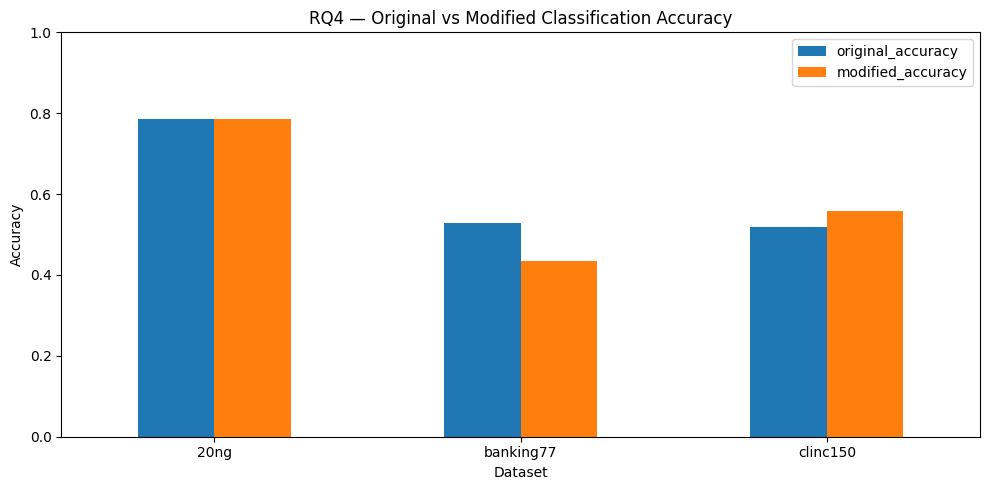

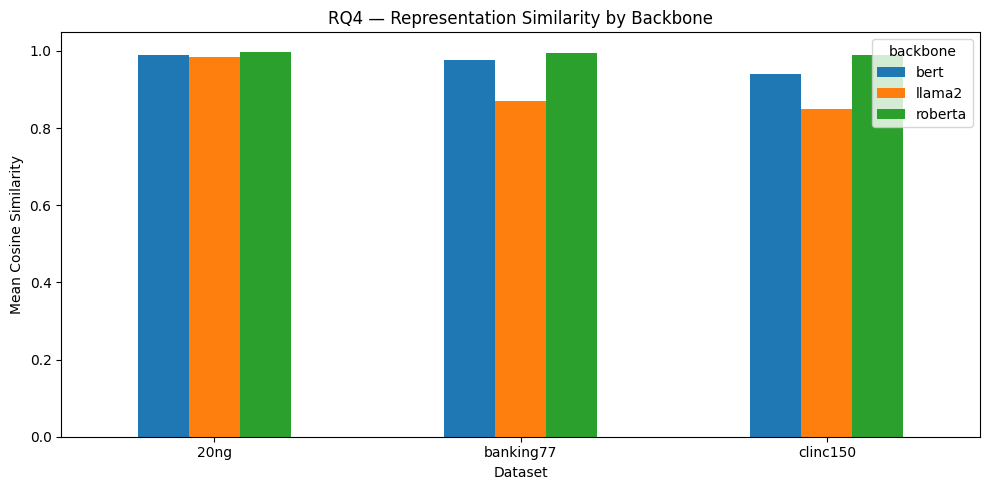


RQ4 FINAL VERIFICATION
Expected pairs: 133
Prediction pairs: 133
Similarity records: 399
Models: llama2, bert, roberta
Datasets: 3
Representation path: /content/drive/MyDrive/COMP8240_LLMEmbed/results_v2/RQ4_balanced_judge/representations_rq2_matched_v3
Results path: /content/drive/MyDrive/COMP8240_LLMEmbed/results_v2/RQ4_balanced_judge

RQ4 evaluation and validation completed successfully.


In [39]:
# Similarity analysis
# Source: original uploaded notebook, cell 132.
# Saved outputs are historical; rerun in Colab to reproduce.


# ============================================================
# RQ4 — REPRESENTATION SIMILARITY + FINAL VERIFICATION
# ============================================================

import json
import torch
import torch.nn.functional as F
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Compute paired representation similarity
# ------------------------------------------------------------

similarity_records = []

for task in TASKS:

    frame = (
        primary[primary.dataset_key.eq(task)]
        .sort_values("pair_id")
        .reset_index(drop=True)
    )

    n = len(frame)

    if n == 0:
        continue

    print("\nProcessing similarity:", task)

    for backbone in BACKBONES:

        path = (
            RQ4_REP / task / f"{backbone}.pt"
        )

        assert path.is_file(), (
            f"Missing representation: {path}"
        )

        representations = torch.load(
            path,
            map_location="cpu",
            weights_only=True
        ).float()

        expected = (
            2 * n,
            *SHAPES[backbone]
        )

        assert (
            tuple(representations.shape)
            == expected
        ), (
            f"Shape mismatch: {task}/{backbone}"
        )

        # First n examples: original text.
        # Next n examples: modified text.
        original = (
            representations[:n]
            .reshape(n, -1)
        )

        modified = (
            representations[n:]
            .reshape(n, -1)
        )

        cosine = F.cosine_similarity(
            original,
            modified,
            dim=1,
            eps=1e-8
        ).numpy()

        assert np.isfinite(cosine).all()

        for i, value in enumerate(cosine):

            similarity_records.append({
                "pair_id": frame.pair_id.iloc[i],
                "dataset_key": task,
                "transformation": (
                    frame.transformation.iloc[i]
                ),
                "backbone": backbone,
                "cosine_similarity": float(value)
            })

        print(
            backbone,
            "mean cosine:",
            round(float(np.mean(cosine)), 4)
        )

        del representations, original, modified

# ------------------------------------------------------------
# 2. Save pair-level similarity
# ------------------------------------------------------------

similarity_df = pd.DataFrame(
    similarity_records
)

assert not similarity_df.empty, (
    "No similarity results generated."
)

similarity_df.to_csv(
    RQ4_OUT / "representation_similarity.csv",
    index=False
)

# ------------------------------------------------------------
# 3. Summarise similarity by dataset and model
# ------------------------------------------------------------

similarity_by_dataset = (
    similarity_df
    .groupby(["dataset_key", "backbone"])
    .cosine_similarity
    .agg(
        pairs="count",
        mean_similarity="mean",
        std_similarity="std",
        min_similarity="min",
        max_similarity="max"
    )
    .reset_index()
)

similarity_by_transformation = (
    similarity_df
    .groupby([
        "dataset_key",
        "backbone",
        "transformation"
    ])
    .cosine_similarity
    .agg(
        pairs="count",
        mean_similarity="mean",
        std_similarity="std"
    )
    .reset_index()
)

similarity_by_dataset.to_csv(
    RQ4_OUT / "similarity_by_dataset.csv",
    index=False
)

similarity_by_transformation.to_csv(
    RQ4_OUT / "similarity_by_transformation.csv",
    index=False
)

print("\n" + "=" * 80)
print("RQ4 — REPRESENTATION SIMILARITY")
print("=" * 80)

display(
    similarity_by_dataset.round(4)
)

display(
    similarity_by_transformation.round(4)
)

# ------------------------------------------------------------
# 4. Plot original vs modified accuracy
# ------------------------------------------------------------

plot_data = by_dataset.set_index(
    "dataset_key"
)[
    [
        "original_accuracy",
        "modified_accuracy"
    ]
]

ax = plot_data.plot(
    kind="bar",
    figsize=(10, 5),
    rot=0
)

ax.set_title(
    "RQ4 — Original vs Modified Classification Accuracy"
)

ax.set_ylabel("Accuracy")
ax.set_xlabel("Dataset")
ax.set_ylim(0, 1)

plt.tight_layout()

plt.savefig(
    RQ4_OUT / "accuracy_comparison.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 5. Plot representation similarity
# ------------------------------------------------------------

similarity_plot = similarity_by_dataset.pivot(
    index="dataset_key",
    columns="backbone",
    values="mean_similarity"
)

ax = similarity_plot.plot(
    kind="bar",
    figsize=(10, 5),
    rot=0
)

ax.set_title(
    "RQ4 — Representation Similarity by Backbone"
)

ax.set_ylabel("Mean Cosine Similarity")
ax.set_xlabel("Dataset")

plt.tight_layout()

plt.savefig(
    RQ4_OUT / "representation_similarity_comparison.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 6. Final validation
# ------------------------------------------------------------

expected_pairs = len(primary)
actual_pairs = len(pred)

assert actual_pairs == expected_pairs, (
    f"Expected {expected_pairs} prediction pairs, "
    f"found {actual_pairs}."
)

assert pred.pair_id.is_unique, (
    "Duplicate pair IDs found."
)

expected_similarity_rows = (
    expected_pairs * len(BACKBONES)
)

assert len(similarity_df) == expected_similarity_rows, (
    "Some representation similarity results are missing."
)

assert not similarity_df[
    ["cosine_similarity"]
].isna().any().any()

# Verify that each pair has all three backbones.
backbone_counts = (
    similarity_df
    .groupby("pair_id")
    .backbone
    .nunique()
)

assert (
    backbone_counts == len(BACKBONES)
).all(), (
    "Some pairs are missing backbone representations."
)

print("\n" + "=" * 80)
print("RQ4 FINAL VERIFICATION")
print("=" * 80)

print("Expected pairs:", expected_pairs)
print("Prediction pairs:", actual_pairs)
print("Similarity records:", len(similarity_df))
print("Models:", ", ".join(BACKBONES))
print("Datasets:", pred.dataset_key.nunique())
print("Representation path:", RQ4_REP)
print("Results path:", RQ4_OUT)

print("\nRQ4 evaluation and validation completed successfully.")


## Output provenance
Any outputs displayed under cells above were saved inside the uploaded notebook. They are included for reference, **not produced by this notebook creation**. A full reproducibility run needs GPU execution, access to the same datasets/models and compatible saved assets. In particular, RQ3/RQ4 result tables should not be described as final unless their execution completed successfully.
